# GridDividend
## A Model for Electric Utility Reform Through Shared Savings

**Dr Robert A. F. Currie, May 2026**

Companion model to: *GridDividend: A Model for Electric Utility Reform* (Substack, 2026)  
Based on: *Electric Utility Reform in an Age of Electrification* (The States Forum, 2025)  
Repository: github.com/robertafcurrie/GridDividend

---

The United States is at an inflection point in how it powers itself. Electricity demand is rising for the first time in decades, driven by electric vehicles, heat pumps, data centres, and industrial electrification. The grid that will carry this load is being built now — in rate cases, capital programmes, and regulatory decisions made state by state, utility by utility, year by year. The choices made in the next decade will compound for half a century. This is not primarily a crisis. It is an opportunity — one of the largest in the history of the American electric industry. States and utilities that move early to align financial incentives with efficient outcomes will build a cleaner, more resilient, and more affordable grid than the one the current regulatory model would produce. The window for states AND utilities to lead on this is open. GridDividend is a tool for exploring what leadership could look like in practice — not a finished answer, but a structured starting point for the conversations that need to happen.

### What this model is — and is not

GridDividend is a **strategic policy simulation framework**. It is designed to show the *direction and order of magnitude* of the shared savings opportunity using real regulatory starting parameters and transparent assumptions. It is **not** a utility planning model, a rate case filing, or a forecast.

Three specific scope boundaries matter most:

- **Full tariff bill, not all bill components.** The bill figures include both delivery (distribution infrastructure) and supply (energy and NYISO capacity costs), anchored to filed tariff rates for a 600 kWh/month customer. Shared savings reform acts primarily on the delivery component through infrastructure avoidance, and secondarily on supply through lower peak demand reducing NYISO capacity obligations. What the model does not project are independent movements in wholesale energy prices, transmission costs, or policy surcharges — these are held at their starting growth trajectory. Reform savings represent what a distribution utility under shared savings incentives can influence, not a forecast of total electricity bill movements.
- **Spatially aggregate.** The model treats the grid as a system-wide pool of capacity. Real distribution systems are constrained networks where NWS value depends on *where* the DER is relative to *where* the constraint is. Individual feeders will see very different outcomes from the system average.
- **One representative scenario.** Results are a single deterministic trajectory, not a probability distribution. Many parameters are uncertain and correlated in ways the model does not capture.
- **AI assistance.** AI was used extensively in researching and creating this model, and in writing the companion article.

These limitations are discussed fully in Section 10.

### How to use this notebook

1. **Edit Section 1** to change any parameter
2. **Run All Cells** (Kernel → Restart & Run All)
3. Charts save to `charts_article/` folder

All bill figures are for a 600 kWh/month residential customer — the standard PSC benchmark.  
Results cover 2026–2050. BAU = Business As Usual. SS = Shared Savings Reform.

---

## Section 0: Setup
Imports, styling, and output directory.

In [1]:
# ============================================================
# SECTION 0: SETUP
# Loads the model engine from ../engine/model.py and utility
# data from ../utilities/*.json — see CLAUDE.md architecture notes.
# Requires: pandas, numpy, matplotlib (all standard Anaconda/pip packages)
# Install if needed: pip install pandas numpy matplotlib
# ============================================================

import sys, os, subprocess
sys.path.insert(0, '..')
import json
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

from engine import project, run_named_scenario, apply_passthrough_savings, apply_preset

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': '#f8f9fa',
    'axes.grid': True, 'grid.alpha': 0.35,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'figure.dpi': 130,
})
C = {
    'bau': '#d62728', 'shared': '#2ca02c',
    'freeze_bau': '#ff7f0e', 'freeze_shared': '#17becf',
    'util_bau': '#ff7f0e', 'util_shared': '#1f77b4',
    'neutral': '#888888', 'tax': '#9467bd',
    'capex_spent': '#1f77b4', 'capex_avoided': '#2ca02c',
    'opex_nws': '#ff7f0e', 'ineligible': '#c5b0d5',
}
YEARS = list(range(2026, 2051))
os.makedirs('charts', exist_ok=True)

# ── Utility data (loaded from ../utilities/*.json) ────────────────────────────
#
# Sources: see ../utilities/ConEd.json and ../utilities/RGE.json (_sources field)
#   Con Edison: NYPSC Case 25-E-0072, Joint Proposal adopted January 22, 2026
#               Con Edison 2024 Form 10-K; SEC 8-K November 2025
#   RG&E:       NYPSC Case 25-E-0379 — temporary rates set June 1 2026 (+4.0% electric)
#               Final PSC order still pending. Parameters estimated from June 2025 filing.
#               ⚠ RG&E rate base is back-calculated; update when PSC order issues.

UTILITIES = {
    "ConEd": json.load(open('../utilities/ConEd.json')),
    "RGE":   json.load(open('../utilities/RGE.json')),
}

# Shared parameters applying to both utilities
SHARED_DEFAULTS = {
    "ev_adoption_curve": {   # Statewide NY EVs (CLCPA-anchored, NYSERDA targets)
        2026: 1_000_000,
        2030: 3_000_000,
        2035: 6_000_000,
        2040: 8_500_000,
        2050: 10_000_000,
    },
    "ev_peak_kw": 7.2,       # Average peak draw per EV (Level 2 charging, kW)
}

print("GridDividend v1.0 — modular engine (engine/model.py) + JSON utility data.")
print(f"Modelling years: {YEARS[0]}–{YEARS[-1]}")
print(f"Charts → charts/")
print()
print("Utilities loaded:")
for k, u in UTILITIES.items():
    print(f"  {u['short_name']} ({u['filing_case']})")


GridDividend v1.0 — modular engine (engine/model.py) + JSON utility data.
Modelling years: 2026–2050
Charts → charts/

Utilities loaded:
  Con Edison (Case 25-E-0072)
  RG&E (Case 25-E-0379 (temporary rates Jun 2026; final order pending))


## Section 1: Parameters

**Edit any value here. Then re-run all cells.**

All parameters are documented with their sources and rationale.
See the companion article for full discussion of each assumption.

In [2]:
# ============================================================
# SECTION 1: USER-ADJUSTABLE PARAMETERS
# ============================================================

# ── Utilities to model ────────────────────────────────────────────────────────
utilities_to_run = ['ConEd', 'RGE']   # 'ConEd', 'RGE', or both

# ── Shared savings mechanism ──────────────────────────────────────────────────
UTILITY_SAVINGS_SHARE = 0.30
# Fraction of savings pool retained by utility. Default 30%.
# Based on NY PSC precedent for NWS incentive mechanisms.
# Remainder (70%) is returned to customers as bill savings.

# ── NWS-eligible CAPEX ────────────────────────────────────────────────────────
NWS_ELIGIBLE_CAPEX_SHARE_START = 0.30
# Starting fraction of annual CAPEX addressable by NWS (~30%).
# Consistent with proportion of Con Ed rate case increase driven by
# new infrastructure investment. Brattle Ontario study found 20-40%
# growth capex reduction at provincial scale — consistent with this range.

NWS_ELIGIBLE_CAPEX_SHARE_MAX = 0.50
# Maximum eligible share as electrification drives more load-growth CAPEX.
# Ceiling reflects that asset replacement never disappears from the programme.

NWS_ELIGIBLE_CAPEX_LOAD_SENSITIVITY = 2.0
# Rate at which eligible share grows with cumulative electrification load.

NWS_AVOIDANCE_OF_ELIGIBLE_START = 0.20
# Fraction of eligible CAPEX NWS defers in year 1.
# Low in early years: programmes nascent, DER aggregation immature.

NWS_AVOIDANCE_OF_ELIGIBLE_MATURE = 0.80
# Fraction of eligible CAPEX NWS defers at programme maturity.
# Supported by two bodies of evidence:
# (1) Brattle Ontario (2026): NWS cost-effective in 95% of feeder scenarios
# (2) GB flexibility markets (UKPN DSO, 2025): 31 GW tendered, 9 GW contracted,
#     mature DSO programmes meeting 100% of identified network constraints at
#     specific constrained locations, delivering £300M consumer savings in 2024.
# Source: UKPN DSO Performance Panel Report 2024/25; Blake Clough Consulting
# (2025), DSO Flexibility Markets: Transforming GB's Grid Economics.
# The 80% reflects a mature programme; 20% residual covers upgrades too large,
# too remote, or insufficiently served by available DER to be deferred by NWS.

NWS_AVOIDANCE_RAMP_YEARS = 9
# Years to ramp from START to MATURE avoidance rate.

# ── Utilisation credit — Brattle Untapped Grid mechanism ─────────────────────
FLEX_LOAD_UTILISATION_SHARE_SS = 0.15
# Fraction of annual load growth served from existing system headroom (SS only).
#
# Mechanism: flexible load (managed EVs, curtailable data centres, demand
# response) uses spare capacity without triggering proportional CAPEX growth.
# Fixed costs are spread over more kWh → delivery rate per kWh falls.
# This is independent of and additive to NWS CAPEX avoidance.
#
# Source: Brattle/Utilize Coalition (2026), "The Untapped Grid":
# 10% utilisation improvement → 4.8% all-in rate reduction; utility earnings
# still grow +23%; new load connects 4-9 years faster.
# Default 15% is conservative vs Brattle base case (~33%) — appropriate
# because GridDividend models distribution scope only.
#
# Set to 0.0 to disable and isolate the other two mechanisms.

FLEX_LOAD_UTILISATION_SHARE_BAU = 0.00
# No intentional utilisation optimisation in BAU.

# ── NWS programme costs ───────────────────────────────────────────────────────
OPEX_RATIO = 0.15
# NWS OPEX as fraction of avoided CAPEX (default 15%).
# Utility pays DER aggregators, demand response providers, managed charger fees.
#
# DERIVATION: Brattle Ontario (2026) used $50/kW-year for DER capacity costs.
# At $2M/MW avoided upgrade cost and ~25% dispatch efficiency, avoided CAPEX of
# $1M corresponds to roughly 0.5 MW of NWS capacity at ~$25k/yr OPEX → ~2.5%.
# However, real NWS programmes also include programme administration, DERMS
# operation, customer acquisition, and performance monitoring — these
# substantially increase total OPEX. BQDM actual OPEX ran ~12-18% of avoided
# capital on an annualised basis (source: NY PSC BQDM programme reports).
#
# RANGE: 10-25% is defensible; 15% is the central estimate.
# This parameter has significant uncertainty and should be treated as a
# sensitivity variable. See Section 8 for sensitivity analysis.
# Future versions should model OPEX explicitly by contract type:
#   - Availability payments (paid regardless of dispatch)
#   - Utilisation payments (per MWh dispatched)
#   - Capacity payments (per kW committed)
# These have very different cost profiles and risk allocations.

NWS_DISPATCH_EFFICIENCY = 0.25
# Fraction of total flex stack reliably dispatchable as NWS at any given time.

# ── Distribution upgrade cost — set per utility ──────────────────────────────
# $M per MW of NWS-eligible distribution upgrade deferred.
# This parameter does significant work in the physical NWS capability check:
#   nws_dollar_value_m = nws_capable_mw × DIST_UPGRADE_COST_PER_MW
# It must reflect the utility's actual distribution capital cost structure.
#
# RANGE AND SOURCES:
# Con Edison (dense urban, almost entirely underground):
#   $7.1M/MW — Idlewild Project: $1.2B for 170 MW of load transfer capacity
#     (Source: NYPSC Case 23-E-0360, approved Jan 2024; Con Edison 10-K 2024)
#     Note: this is a major substation project. Routine feeder reinforcements
#     in Con Edison's underground network typically run $3-5M/MW.
#     Conservative central estimate: $4.0M/MW for the eligible CAPEX mix
#     (weighted average of substation projects and feeder reinforcements).
#
# RG&E (suburban/rural, predominantly overhead):
#   Overhead distribution reinforcement: $0.5-1.5M/MW
#   Substation upgrades: $1.5-3.0M/MW
#   Conservative central estimate: $1.5M/MW for the eligible CAPEX mix
#   (RG&E capital programme is primarily overhead suburban work at lower cost)
#
# IMPORTANT MODELLING NOTE:
# This parameter varies enormously — even within a single utility's programme.
# A routine overhead line upgrade might cost $0.3M/MW; an urban underground
# substation might cost $8-10M/MW. Using a single blended figure is a
# necessary simplification for this model. State-level analysis should:
#   (1) Obtain the utility's CAPEX programme by project type and voltage class
#   (2) Apply category-specific costs to the NWS-eligible subset
#   (3) Model the distribution of upgrade sizes rather than a blended average
# See Part Nine of the companion article for discussion.
#
# In the current model, the physical NWS capability check (nws_dollar_value_m)
# is typically NOT the binding constraint — the policy ceiling on eligible
# CAPEX avoidance binds first. The cost parameter therefore has limited
# impact on results in the base case but becomes important in scenarios
# with high DER availability or high avoidance rates.

DIST_UPGRADE_COST_PER_MW = {
    'ConEd': 4.0,   # $M/MW — urban underground mix (see documentation above)
    'RGE':   1.5,   # $M/MW — suburban/rural overhead mix
}
# To use a single value for all utilities: set as a number, e.g. DIST_UPGRADE_COST_PER_MW = 2.0

# ── Pass-through savings ──────────────────────────────────────────────────────
# ── Capacity market pass-through savings ─────────────────────────────────────
#
# Pass-through savings are computed as a post-processing step in Section 4:
#   saving_year_N = (peak_bau_N − peak_ss_N) MW × capacity_cost_year_N
#
# This uses the actual peak demand difference between BAU and SS scenarios
# rather than approximating from a fixed percentage of supply costs.
#
# CAPACITY_COST_START: NYISO ICAP clearing price per MW-year by load zone
#   ConEd: NYC zone — avg ~$120/kW-yr = $0.120M/MW-yr (NYISO 2024 auctions)
#   RGE:   Upstate zones G/H/I — avg ~$70/kW-yr = $0.070M/MW-yr
#   Includes both generation ICAP and transmission capacity components.
#   Sources: NYISO Installed Capacity Market reports 2024; NYISO ICAP auctions.
#
# CAPACITY_COST_GROWTH: Real annual growth in capacity prices (3%/yr)
#   Electrification and data centre load tighten reserve margins → higher prices.
#   New peaking capacity (gas CT or large-scale BESS) sets price ceiling.
#   Nominal growth ~5%/yr including inflation; 3% real is conservative.

CAPACITY_COST_START = {
    'ConEd': 0.120,   # $M/MW-year (NYC zone, 2026 anchor)
    'RGE':   0.070,   # $M/MW-year (upstate zones G/H/I, 2026 anchor)
}
CAPACITY_COST_GROWTH = 0.03   # 3%/yr real growth in capacity prices

# ── Load growth ───────────────────────────────────────────────────────────────
BASELINE_LOAD_GROWTH = 0.005   # 0.5%/yr baseline organic growth

ELECTRIFICATION_RAMP = {
    (2026, 2030): 0.008,   # EVs and heat pumps ramping: +0.8%/yr
    (2031, 2035): 0.018,   # Peak CLCPA electrification decade: +1.8%/yr
    (2036, 2040): 0.012,   # Post-peak: +1.2%/yr
    (2041, 2050): 0.005,   # Mature electrification: +0.5%/yr
}

# ── DER adoption ──────────────────────────────────────────────────────────────
STORAGE_MAX_PCT_OF_PEAK = 0.35   # Storage ceiling: 35% of peak (CLCPA-anchored)
STORAGE_GROWTH_BAU      = 0.15   # 15%/yr storage growth (BAU, market-driven)
STORAGE_GROWTH_SHARED   = 0.22   # 22%/yr under SS (utility actively promotes)
DER_ADOPTION_LEAD_YEARS = 4      # SS achieves same DER level 4 years ahead of BAU
EV_MANAGED_CHARGING_SHARED = 0.45   # 45% managed EV charging under SS (vs ~10% BAU)
STORAGE_PEAK_OFFSET_KW_PER_MWH = 0.85   # kW of peak offset per MWh storage capacity

# ── Financial parameters ──────────────────────────────────────────────────────
COST_OF_DEBT   = 0.05    # 5% cost of debt
INFLATION_RATE = 0.025   # 2.5%/yr general inflation

# ── Floor constraint ──────────────────────────────────────────────────────────
CAPEX_SPENT_FLOOR_GROWTH = 0.005
# Minimum annual growth in CAPEX spent (0.5%/yr).
# NWS defers FUTURE projects, not current year commitments already underway.
# Without this floor, the model could show CAPEX spending falling in nominal
# terms, which is not realistic for a utility with multi-year capital programmes.

# ── Rate freeze overlay ───────────────────────────────────────────────────────
RATE_FREEZE_YEARS          = 2   # Duration of rate freeze (0 to disable)
RATE_FREEZE_RECOVERY_YEARS = 4   # Catch-up period to recover deferred costs

# ── State policy milestones — update for each state ───────────────────────────
# These appear as vertical reference lines on charts.
# CLCPA is New York's Climate Leadership and Community Protection Act (2019).
# Replace with the relevant state legislation when applying to other states.
MY = {
    2030: 'CLCPA\n70% Renew.',
    2035: 'CLCPA\nPeak Electrif.',
    2040: 'CLCPA\nNet-Zero',
}

# ── Residential bill anchor ───────────────────────────────────────────────────
RESIDENTIAL_KWH_MONTH = 600
# Standard PSC benchmark: 600 kWh/month residential customer.
# Used in all NY utility rate cases for illustrative bill comparisons.
# Actual usage: ~400 kWh/mo (small city apartment) to 1,000+ kWh/mo (suburban).
# Percentage savings apply regardless of usage level — reform acts on ¢/kWh rate.

UTILITY_BILL_PARAMS = {
    'ConEd': {
        'delivery_rate_kwh':  0.141,  # 14.1¢/kWh delivery (Case 25-E-0072, 2024 tariff)
        'supply_rate_kwh':    0.103,  # 10.3¢/kWh supply (2024 market average)
        'basic_charge_month': 18.0,   # $18/month basic service charge
        'delivery_share_rr':  0.60,   # ~60% of RR is delivery (vs supply pass-through)
        # Source: Con Edison SC-1 residential service tariff filed with NYPSC
    },
    'RGE': {
        'delivery_rate_kwh':  0.0741, # 7.41¢/kWh delivery (July 2024 tariff)
        'supply_rate_kwh':    0.080,  # 8.0¢/kWh supply (estimated market rate)
        'basic_charge_month': 27.0,   # $27/month basic service charge
        'delivery_share_rr':  0.56,   # ~56% of RR is delivery
        # Source: RG&E electric rate summary July 2024; supply rate estimated
        # ⚠️ RG&E Case 25-E-0379: PSC set temporary rates June 1 2026 (+4.0% electric).
        #    Final order pending. All RG&E figures estimated from June 2025 filing.
    },
}

# ── IMPORTANT NOTE ON PROPERTY TAX ───────────────────────────────────────────
# Property tax is set in load_utility() as a fraction of rate base.
# DEFAULT VALUES (electric assets only, approximate):
#   Con Edison: 1.6% of electric rate base (~$520M/yr on $32.9B rate base)
#   RG&E:       1.8% of electric rate base (~$29M/yr on $1.6B rate base)
#
# These are ILLUSTRATIVE estimates derived from utility annual reports and
# rate case evidence, applied only to the ELECTRIC rate base.
#
# KNOWN LIMITATIONS (see Part Six of companion article):
# (1) Assessed value ≠ rate base: NY franchise assessment uses income
#     capitalisation and stock-and-debt methods, not original cost.
# (2) NWS avoidance prevents future assets from being built; it does NOT
#     immediately reduce assessed value of existing assets. The property
#     tax saving materialises slowly over years as the avoided asset base
#     compounds, not immediately as the model implies.
# (3) NY franchise tax has both property AND income components. As utility
#     earnings rise under shared savings, the income component increases,
#     partially offsetting the property component reduction.
# (4) Municipal fiscal interests: Con Edison is one of NYC's largest
#     property taxpayers. Rate reform affecting assessed values will face
#     local government scrutiny not captured here.
#
# BOTTOM LINE: The property tax saving shown in results is directionally
# correct but likely overstated in magnitude and timing. It should be
# read as indicative of the category of benefit, not as a precise forecast.
# State-specific analysis should model property tax from actual utility
# tax filings, not from rate base × estimated rate.


# ── DER flex load capture (used in project() for peak reduction) ──────────────
FLEX_LOAD_CAPTURE_BAU    = 0.08   # 8% of load growth captured by flex resources (BAU)
FLEX_LOAD_CAPTURE_SHARED = 0.40   # 40% captured under shared savings (utility manages DER)

# ── Deferral vs permanent avoidance ──────────────────────────────────────────
# Share of avoided CAPEX that is temporary deferral rather than permanent
# avoidance. Deferred CAPEX re-enters the rate base after DEFERRAL_PERIOD_YEARS
# because the underlying constraint eventually returns as load grows.
#
# DEFERRAL_FRACTION = 0.0  → all NWS avoidance is permanent (current model)
# DEFERRAL_FRACTION = 0.3  → 30% of avoided CAPEX eventually gets built
# DEFERRAL_FRACTION = 0.6  → majority is deferral (dense urban networks)
#
# Default 0.0 reproduces existing results exactly.
# Con Edison (dense urban, high load growth): 0.40–0.60 more realistic long-term
# RG&E (suburban/rural, moderate growth):     0.15–0.30
#
# No published benchmarks exist — identified as priority future work.

DEFERRAL_FRACTION     = 0.0    # 0.0 = permanent avoidance (current assumption)
DEFERRAL_PERIOD_YEARS = 10     # Years before deferred CAPEX re-enters rate base

# ── Upfront customer passthrough ────────────────────────────────────────────
# Years in which 100% of shared savings income passes to customers.
# Utility retains 0% (rather than UTILITY_SAVINGS_SHARE) during this window.
# Standard split resumes in year UPFRONT_PASSTHROUGH_YEARS + 1.
#
# Represents a legislative design choice to front-load customer benefits
# while NWS capability is being established. Set to 0 for standard behaviour.
# Effect: approximately triples year 1-3 customer savings vs BASE case.
# Con Edison: ~$3.50/month saving by year 2 (2027), ~$5.50/month by year 3 (2028) when set to 3.

UPFRONT_PASSTHROUGH_YEARS = 0  # 0 = standard split from year one (default)

# ── Savings pool basis ───────────────────────────────────────────────────────
SAVINGS_POOL_BASIS = 'capex'
# How the shared-savings pool is measured each year.
# 'capex' (default, v1.0 behaviour): pool = avoided CAPEX − NWS OPEX in the year
#   of avoidance. The customer 70% is credited against that year's revenue
#   requirement while the avoided CAPEX also stays out of rate base, so the
#   same avoided dollar benefits customers twice (possible double count).
# 'revenue_requirement': pool = annual reduction in delivery revenue requirement
#   vs BAU (return + property tax on the avoided rate base) − NWS OPEX. Customers
#   receive it through the lower rate base; the utility's share is recovered in
#   rates. Pool can be negative in early years (OPEX > RR reduction).
# Source: model design choice — see CLAUDE.md "Savings pool basis" and
# engine/model.py project() docstring. Section 8b compares both.

# ── ROE override ──────────────────────────────────────────────────────────────
ROE_OVERRIDE = None
# None (default) = use each utility's rate-case ROE from utilities/*.json.
# A number (e.g. 0.080) replaces it for every utility in this run; WACC is
# recomputed as roe × equity_ratio + COST_OF_DEBT × (1 − equity_ratio), matching
# load_utility(). Values below the rate case are an illustrative market-return
# range, not an auction-clearing rate.
# Source: rate-case ROEs as documented in utilities/*.json (_sources fields).

ROE_OVERRIDE_REBASE_BILL = True
# When ROE_OVERRIDE is set, rescale the 2026 starting delivery bill by the ratio
# of first-year BAU delivery revenue requirement at the override ROE to that at
# the rate-case ROE (the starting tariff was set at the rate-case ROE). Without
# this, bills are indexed to each run's own first-year revenue requirement and
# an ROE change barely moves bill levels. No effect when ROE_OVERRIDE is None.
# Source: model design choice — see engine/model.py apply_roe_override().

# ── Correction flags (all default to v1.0 behaviour) ─────────────────────────
# Source for all flags below: model design choices — see CLAUDE.md
# "Correction flags and the CORRECTED preset" and engine/model.py project().

INCLUDE_DEPRECIATION_EXPENSE = False
# True: add depreciation (3.5% × opening rate base — the model's rate-base decay
# rate) to delivery RR, and recalibrate other O&M so 2026 BAU delivery RR equals
# the rate-case figure (total_revenue_m × delivery_share_rr). Avoided
# depreciation then counts in the 'revenue_requirement' savings pool.

NEGATIVE_POOL_TREATMENT = 'symmetric'
# 'symmetric' (v1.0): utility bears its share of negative pools.
# 'floor_zero': utility share never below zero; customers bear the shortfall.
# 'carry_forward': negative pools carried forward (no interest) and netted
#   against later positive pools before the utility share is applied.

NWS_COST_TREATMENT = 'expense'
# 'expense' (v1.0): NWS OPEX recovered in delivery RR in the year incurred.
# 'capitalise': NWS OPEX goes into a regulatory asset in rate base, earning
#   WACC and amortised straight-line over NWS_AMORTISATION_YEARS — so the
#   utility earns on NWS spend as it would on capital. Savings share on top.

NWS_AMORTISATION_YEARS = 10
# Amortisation period for capitalised NWS OPEX (years). Only used when
# NWS_COST_TREATMENT = 'capitalise'.

BILL_INDEX_BASE = 'own'
# 'own' (v1.0): each scenario's delivery bill is indexed to its own 2026
#   delivery RR, so first-year differences between scenarios never reach bills.
# 'bau': every scenario is indexed to the BAU 2026 delivery RR.

MODEL_PRESET = None
# None (default) or a key of engine PRESETS, e.g. 'CORRECTED', which switches
# on the recommended flags above together. Applied to MODEL_CONFIG below.

print("Section 1 complete — parameters loaded.")
print(f"Utilities: {utilities_to_run}")
print(f"Utility savings share: {UTILITY_SAVINGS_SHARE:.0%}")
print(f"NWS avoidance at maturity: {NWS_AVOIDANCE_OF_ELIGIBLE_MATURE:.0%} of eligible CAPEX")
print(f"Utilisation credit: {FLEX_LOAD_UTILISATION_SHARE_SS:.0%} of load growth uses headroom (SS)")
print(f"Rate freeze: {RATE_FREEZE_YEARS} years (set to 0 to disable)")

# Build explicit config dict — no globals injection needed
MODEL_CONFIG = {k: v for k, v in globals().items() if k.isupper()}
# Flatten SHARED_DEFAULTS into config so helpers can read EV params
MODEL_CONFIG['EV_ADOPTION_CURVE'] = SHARED_DEFAULTS['ev_adoption_curve']
MODEL_CONFIG['EV_PEAK_KW']        = SHARED_DEFAULTS['ev_peak_kw']
if MODEL_PRESET:
    MODEL_CONFIG = apply_preset(MODEL_CONFIG, MODEL_PRESET)
    print(f"Preset {MODEL_PRESET} applied to MODEL_CONFIG.")

# ── Section 11: Summary report ────────────────────────────────────────────
GENERATE_SUMMARY_REPORT = True        # toggle: build Section 11 HTML/PDF report
REPORT_SCENARIOS = ['BASE']           # SCENARIO_DEFS keys to report on, one file per key
                                       # each report is single-scenario-vs-BAU only —
                                       # add more keys for more files, never a
                                       # cross-scenario comparison within one file


Section 1 complete — parameters loaded.
Utilities: ['ConEd', 'RGE']
Utility savings share: 30%
NWS avoidance at maturity: 80% of eligible CAPEX
Utilisation credit: 15% of load growth uses headroom (SS)
Rate freeze: 2 years (set to 0 to disable)


## Section 1b: Near-Term vs Long-Term Scenario Definitions

Four named scenarios exploring the trade-off between near-term and long-term bill savings. All base case parameters in Section 1 are unchanged — these definitions configure parallel runs on top of the base case.

| Scenario | What changes | Near-term mechanism |
|----------|-------------|--------------------|
| **BASE** | Nothing — Section 1 reference case | — |
| **ACCELERATED** | Start avoidance 35%, ramp 6 yr, eligible share 35%→55% | Faster programme ramp |
| **FREEZE\_PLUS** | 4-year rate freeze | Legislative freeze |
| **COMBINED** | Accelerated parameters + 3-year rate freeze | Both |

Results stored in `scenario_results`. Charts and summary table in **Section 9b**.

In [3]:
# ============================================================
# SECTION 1b: NEAR-TERM VS LONG-TERM SCENARIO DEFINITIONS
# ============================================================
# Four named scenario configurations. BASE = no overrides (reference).
# Others override specific Section 1 globals via run_named_scenario().
# Execution cell follows Section 4 once project() and utility_data exist.

SCENARIO_DEFS = {
    'BASE': {
        'params': {},
        'freeze': False,
        'label': 'BASE (base case)',
        'colour': '#2ca02c',   # matches C['shared']
    },
    'ACCELERATED': {
        # Higher starting avoidance (0.35), shorter ramp (6 yr),
        # higher eligible share start (0.35) and max (0.55).
        # Represents a utility with existing NWS infrastructure and
        # aggregator relationships before reform takes effect.
        'params': {
            'NWS_AVOIDANCE_OF_ELIGIBLE_START': 0.35,
            'NWS_AVOIDANCE_RAMP_YEARS':        6,
            'NWS_ELIGIBLE_CAPEX_SHARE_START':  0.35,
            'NWS_ELIGIBLE_CAPEX_SHARE_MAX':    0.55,
        },
        'freeze': False,
        'label': 'ACCELERATED (faster NWS ramp)',
        'colour': '#1f77b4',   # matches C['util_shared']
    },
    'FREEZE_PLUS': {
        # Base case programme parameters with a 4-year rate freeze.
        # Near-term relief through legislative design, not programme acceleration.
        'params': {'RATE_FREEZE_YEARS': 4},
        'freeze': True,
        'label': 'FREEZE_PLUS (4-yr freeze)',
        'colour': '#17becf',   # matches C['freeze_shared']
    },
    'COMBINED': {
        # Accelerated programme parameters plus a 3-year rate freeze.
        # Most aggressive near-term delivery consistent with operational realism.
        'params': {
            'NWS_AVOIDANCE_OF_ELIGIBLE_START': 0.35,
            'NWS_AVOIDANCE_RAMP_YEARS':        6,
            'NWS_ELIGIBLE_CAPEX_SHARE_START':  0.35,
            'NWS_ELIGIBLE_CAPEX_SHARE_MAX':    0.55,
            'RATE_FREEZE_YEARS':               3,
        },
        'freeze': True,
        'label': 'COMBINED (accelerated + 3-yr freeze)',
        'colour': '#9467bd',
    },
    'FRONTLOADED': {
        'description': (
            'Base programme parameters with 3-year full customer passthrough. '
            'Utility passes 100% of shared savings to customers in years 1-3, '
            'standard 30/70 split resumes year 4. Legislative design choice to '
            'front-load customer benefits while NWS capability is established.'
        ),
        'colour': '#ff7f0e',   # orange
        'label':  'FRONTLOADED (3-yr full passthrough)',
        'params': {},                      # BASE programme parameters
        'freeze': False,
        'freeze_years': 0,
        'upfront_passthrough_years': 3,
        'deferral_fraction': 0.0,
    },
}

print('Section 1b definitions loaded:', list(SCENARIO_DEFS.keys()))


Section 1b definitions loaded: ['BASE', 'ACCELERATED', 'FREEZE_PLUS', 'COMBINED', 'FRONTLOADED']


## Parameter Guidance

The cell below documents every adjustable parameter, what it controls, its default value, its plausible range, and where to change it. **You do not need to run this cell** — it is documentation. Edit values in Section 1 above, then re-run all cells.

In [4]:
# ============================================================
# PARAMETER GUIDANCE: HOW TO CHANGE AN ASSUMPTION
# ============================================================
#
# If you disagree with any default value, change it in Section 1 above,
# then re-run all cells (Kernel → Restart & Run All).
#
# This cell provides a structured guide to which parameter to change
# for each type of assumption, and what the plausible range is.
#
# ┌─────────────────────────────────────────────────────────────────────┐
# │ QUESTION                     │ PARAMETER               │ DEFAULT  │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How much of the CAPEX         │ NWS_ELIGIBLE_CAPEX_     │  0.30   │
# │ programme can NWS address?    │ SHARE_START             │         │
# │ (starting share, year 1)      │ Range: 0.20 – 0.50      │         │
# │                               │ Brattle Ontario: 20-40% │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How much of eligible CAPEX    │ NWS_AVOIDANCE_OF_       │  0.80   │
# │ can NWS defer at maturity?    │ ELIGIBLE_MATURE         │         │
# │                               │ Range: 0.50 – 0.90      │         │
# │                               │ Programme average, not  │         │
# │                               │ per-project guarantee   │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How long to reach maturity?   │ NWS_AVOIDANCE_RAMP_YEARS│    9    │
# │                               │ Range: 5 – 15           │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How much do utilities keep    │ UTILITY_SAVINGS_SHARE   │  0.30   │
# │ from shared savings?          │ Range: 0.10 – 0.40      │         │
# │                               │ NY PSC precedent: ~30%  │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How much do NWS contracts     │ OPEX_RATIO              │  0.15   │
# │ cost vs CAPEX avoided?        │ Range: 0.10 – 0.25      │         │
# │                               │ BQDM actual: 12-18%     │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How much of new load uses     │ FLEX_LOAD_UTILISATION_  │  0.15   │
# │ spare capacity (Brattle       │ SHARE_SS                │         │
# │ Untapped Grid mechanism)?     │ Range: 0.00 – 0.30      │         │
# │ Set to 0.0 to disable         │ Brattle base: ~0.33     │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How fast does baseline load   │ BASELINE_LOAD_GROWTH    │  0.005  │
# │ grow per year?                │ Range: 0.003 – 0.010    │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ Is electrification faster or  │ ELECTRIFICATION_RAMP    │ (dict)  │
# │ slower than assumed?          │ Edit the (year,year):   │         │
# │                               │ rate values in the dict │         │
# │ Example — slower scenario:    │                         │         │
# │ (2031,2035): 0.012 not 0.018  │                         │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ What is the starting NYISO    │ CAPACITY_COST_START     │ (dict)  │
# │ capacity cost per MW-year?    │ ConEd: 0.120 $M/MW-yr   │         │
# │                               │ RGE:   0.070 $M/MW-yr   │         │
# │ Source: NYISO ICAP auctions   │ Range: 0.08 – 0.18      │         │
# │ NYC zone 2024; upstate 2024   │                         │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How fast do capacity prices   │ CAPACITY_COST_GROWTH    │  0.03   │
# │ grow in real terms per year?  │ Range: 0.01 – 0.05      │         │
# │ Driven by tightening margins  │ Conservative: 0.02      │         │
# │ as electrification grows      │ Optimistic:   0.05      │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ What is the cost per MW of    │ DIST_UPGRADE_COST_PER_  │ (dict)  │
# │ distribution upgrade for      │ MW = {'ConEd': 4.0,     │         │
# │ each utility?                 │        'RGE':  1.5}     │         │
# │                               │ Urban underground: 3-8  │         │
# │                               │ Rural overhead:  0.5-2  │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ What is the rate freeze       │ RATE_FREEZE_YEARS       │    2    │
# │ duration?                     │ Range: 0 – 5            │         │
# │ Set to 0 to remove freeze     │ NJ precedent: 2 years   │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ What should the benchmark     │ RESIDENTIAL_KWH_MONTH   │  600    │
# │ customer usage be?            │ Range: 400 – 900        │         │
# │                               │ NY PSC standard: 600    │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How quickly does storage      │ STORAGE_GROWTH_SHARED   │  0.22   │
# │ grow under shared savings?    │ STORAGE_GROWTH_BAU      │  0.15   │
# │                               │ Range: 0.10 – 0.35      │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How many years ahead does     │ DER_ADOPTION_LEAD_YEARS │    4    │
# │ shared savings accelerate     │ Range: 2 – 8            │         │
# │ DER deployment?               │                         │         │
# └─────────────────────────────────────────────────────────────────────┘
#
# APPLYING A DIFFERENT UTILITY:
# To add a new utility, add its parameters to the UTILITIES dict in
# Section 0, following the same structure as ConEd and RGE.
# Then add it to utilities_to_run = [...] in Section 1.
# Key items needed from a rate case filing:
#   rate_base_start_m, annual_capex_m, total_revenue_m,
#   roe, equity_ratio, electric_customers, peak_demand_mw,
#   annual_energy_gwh, der_storage_mw_start
# And from tariff schedules:
#   delivery_rate_kwh, supply_rate_kwh, basic_charge_month
#
# CONSERVATIVE SCENARIO (sceptical about NWS potential):
#   NWS_ELIGIBLE_CAPEX_SHARE_START = 0.20
#   NWS_AVOIDANCE_OF_ELIGIBLE_MATURE = 0.50
#   NWS_AVOIDANCE_RAMP_YEARS = 15
#   FLEX_LOAD_UTILISATION_SHARE_SS = 0.05
#   OPEX_RATIO = 0.20
#
# OPTIMISTIC SCENARIO (consistent with Brattle base case):
#   NWS_ELIGIBLE_CAPEX_SHARE_START = 0.40
#   NWS_AVOIDANCE_OF_ELIGIBLE_MATURE = 0.90
#   NWS_AVOIDANCE_RAMP_YEARS = 7
#   FLEX_LOAD_UTILISATION_SHARE_SS = 0.25
#   OPEX_RATIO = 0.12

print("Parameter guidance loaded.")
print("This cell contains no executable logic — it is documentation only.")
print("To apply a different assumption, edit Section 1 and re-run all cells.")

Parameter guidance loaded.
This cell contains no executable logic — it is documentation only.
To apply a different assumption, edit Section 1 and re-run all cells.


## Section 2: Utility Starting Data

Pre-populated from filed rate cases:
- **Con Edison**: Case 25-E-0072, approved January 2026
- **RG&E**: Case 25-E-0379, filed June 2025. PSC set **temporary rates effective June 1, 2026** (+4.0% electric revenue). Final order still pending.

Bills anchored to actual filed tariff rates for a 600 kWh/month customer.  
⚠️ **RG&E status (as of May 2026):** The PSC set temporary rates effective June 1, 2026, granting a 4.0% electric revenue increase — a fraction of the 20.1% total increase originally requested. The final order on Case 25-E-0379 is still pending. The temporary rates were set based on prior approved rate levels, not the filed request, while the Commission continues its review. A proposed settlement has also been filed. All RG&E model parameters remain estimates from the June 2025 filing and should be updated when the final order issues.

In [5]:
def load_utility(key):
    """Load and derive utility parameters from rate case data."""
    p = UTILITIES[key].copy()
    p.update(SHARED_DEFAULTS)
    p.update(UTILITIES[key])
    p.update(UTILITY_BILL_PARAMS[key])
    p['wacc'] = p['roe'] * p['equity_ratio'] + COST_OF_DEBT * (1 - p['equity_ratio'])
    # Property tax rate applied to ELECTRIC rate base only
    # These are illustrative estimates from utility annual reports.
    # See IMPORTANT NOTE ON PROPERTY TAX in Section 1 for limitations.
    # Using ~1.6% for ConEd and ~1.8% for RGE (electric assets only).
    # Prior versions used 4.6%/5.6% which inadvertently included all
    # utility assets and produced overstated property tax figures.
    p['property_tax_rate'] = p.get('property_tax_rate', 0.016 if key == 'ConEd' else 0.018)
    # Per-utility residential usage benchmark — falls back to the global
    # RESIDENTIAL_KWH_MONTH default if the utility JSON doesn't specify one.
    p['residential_kwh_month'] = p.get('residential_kwh_month', RESIDENTIAL_KWH_MONTH)
    # Tariff-anchored residential bill
    p['start_delivery_bill_monthly'] = (
        p['delivery_rate_kwh'] * p['residential_kwh_month'] + p['basic_charge_month']
    )
    p['start_supply_bill_monthly'] = p['supply_rate_kwh'] * p['residential_kwh_month']
    p['start_monthly_bill'] = (
        p['start_delivery_bill_monthly'] + p['start_supply_bill_monthly']
    )
    p['key'] = key   # stored so project() can look up per-utility parameters
    return p

utility_data = {k: load_utility(k) for k in utilities_to_run}

print("Utility starting parameters (from filed rate cases):")
print()
for key, p in utility_data.items():
    print(f"  {UTILITIES[key]['short_name']}")
    print(f"    Rate base:       ${p['rate_base_start_m']:>10,.0f}M")
    print(f"    Annual CAPEX:    ${p['annual_capex_m']:>10,.0f}M")
    print(f"    ROE:             {p['roe']:.1%}   WACC: {p['wacc']:.2%}")
    print(f"    Customers:       {p['electric_customers']:>10,.0f}")
    print(f"    Peak demand:     {p['peak_demand_mw']:>10,.0f} MW")
    print(f"    Starting bill:   ${p['start_monthly_bill']:.0f}/mo  "
          f"(delivery ${p['start_delivery_bill_monthly']:.0f} + supply ${p['start_supply_bill_monthly']:.0f})")
    print()

Utility starting parameters (from filed rate cases):

  Con Edison
    Rate base:       $    32,935M
    Annual CAPEX:    $     4,579M
    ROE:             9.4%   WACC: 7.11%
    Customers:        3,700,000
    Peak demand:         11,822 MW
    Starting bill:   $164/mo  (delivery $103 + supply $62)

  RG&E
    Rate base:       $     1,600M
    Annual CAPEX:    $       235M
    ROE:             10.0%   WACC: 7.40%
    Customers:          383,000
    Peak demand:          1,050 MW
    Starting bill:   $119/mo  (delivery $71 + supply $48)



## Section 3: Model Engine (v1.0)

The `project()` function runs the full 2026–2050 projection.

**Three shared savings mechanisms:**
1. **NWS CAPEX avoidance** — eligible CAPEX deferred → smaller rate base → lower delivery charge
2. **Capacity market pass-through savings** — NWS reduces peak demand → lower NYISO ICAP obligation → lower supply charge. Computed in Section 4 as `(peak_bau − peak_ss) × capacity_cost_per_mw_year`, where capacity cost grows at 3%/yr real from a 2026 anchor (NYC: $0.120M/MW-yr; RG&E: $0.070M/MW-yr).
3. **Utilisation credit** — flexible load uses existing spare capacity → fixed costs spread over more kWh → lower cost per kWh

Mechanisms 1 and 3 are computed inside `project()`. Mechanism 2 is applied as a post-processing step in Section 4 after both BAU and SS scenarios have run, so the actual peak demand difference can be used.

**Why this is commercially attractive to utilities:**
Shared savings offers utilities a new and politically durable growth engine. Traditional utility earnings grow by building infrastructure — a strategy increasingly generating rate cases, legislative intervention, and customer hostility as bills rise. Shared savings creates a second growth lever: earnings from finding cheaper solutions. A utility that saves customers $200 million a year through batteries, managed charging, and demand response earns $60 million of that directly — without a rate case, without political conflict, and with every customer and regulator as a commercial ally rather than an adversary. The capabilities required — DER aggregation, real-time grid optimisation, flexible load management — are also the foundational skills for operating a high-renewable, highly electrified grid. This is not a defensive accommodation of change. It is a strategic opportunity to lead it.

In [6]:
# Engine loaded from engine/model.py — see that file for full source

def vlines(ax):
    """Add CLCPA milestone vertical lines to a chart axis."""
    lo, hi = ax.get_ylim()
    for yr, lbl in MY.items():
        ax.axvline(yr, color='gray', ls=':', alpha=0.5, lw=1.2)
        ax.text(yr + 0.25, lo + (hi - lo) * 0.03, lbl, fontsize=7, color='#555', va='bottom')


## Section 4: Run All Scenarios

In [7]:
results = {}
for k in utilities_to_run:
    p = utility_data[k]
    results[k] = {}
    for scenario in ['bau', 'shared']:
        for freeze in [False, True]:
            key = f"{scenario}{'_freeze' if freeze else ''}"
            results[k][key] = project(p, scenario, freeze, config=MODEL_CONFIG)

# ── Post-processing: apply capacity market pass-through savings ───────────────
# See engine/model.py: apply_passthrough_savings() for full docstring/logic.
for k in utilities_to_run:
    results = apply_passthrough_savings(results, k, utility_data, MODEL_CONFIG)

print("All scenarios complete (including capacity market pass-through adjustment).")
print()
for k in utilities_to_run:
    bau = results[k]['bau']; sh = results[k]['shared']
    b50 = bau.iloc[-1]; s50 = sh.iloc[-1]
    sav_mo = b50['avg_monthly_bill'] - s50['avg_monthly_bill']
    sav_yr = sav_mo * 12
    cum = np.sum((bau['avg_annual_bill'].values - sh['avg_annual_bill'].values)
                 * sh['customers'].values) / 1e9
    bau_cum = np.sum(bau['capex_spent_m'].values) / 1000
    ss_cum  = np.sum(sh['total_grid_spend_m'].values) / 1000
    p = utility_data[k]
    print(f"  {UTILITIES[k]['short_name']}")
    print(f"    Start:  ${p['start_monthly_bill']:.0f}/mo")
    print(f"    BAU 2050:  ${b50['avg_monthly_bill']:.0f}/mo")
    print(f"    SS  2050:  ${s50['avg_monthly_bill']:.0f}/mo")
    print(f"    Saving:    ${sav_mo:.0f}/mo  (${sav_yr:,.0f}/yr,  "
          f"{sav_yr/(b50['avg_annual_bill']):.1%})")
    print(f"    Cum savings: ${cum:.1f}B  |  Grid spend: BAU ${bau_cum:.0f}B  SS ${ss_cum:.0f}B")
    print(f"    (Delivery + supply bill savings — wholesale energy/transmission/policy costs not modelled)")
    drops = [yr for yr in YEARS[1:]
             if sh[sh['year']==yr].iloc[0]['capex_spent_m']
             < sh[sh['year']==yr-1].iloc[0]['capex_spent_m'] - 0.1]
    print(f"    CAPEX dips: {'None ✓' if not drops else drops}")
    print()



All scenarios complete (including capacity market pass-through adjustment).

  Con Edison
    Start:  $164/mo
    BAU 2050:  $426/mo
    SS  2050:  $317/mo
    Saving:    $109/mo  ($1,310/yr,  25.6%)
    Cum savings: $50.5B  |  Grid spend: BAU $154B  SS $120B
    (Delivery + supply bill savings — wholesale energy/transmission/policy costs not modelled)
    CAPEX dips: None ✓

  RG&E
    Start:  $119/mo
    BAU 2050:  $296/mo
    SS  2050:  $231/mo
    Saving:    $66/mo  ($787/yr,  22.1%)
    Cum savings: $3.1B  |  Grid spend: BAU $8B  SS $6B
    (Delivery + supply bill savings — wholesale energy/transmission/policy costs not modelled)
    CAPEX dips: None ✓



In [8]:
# ============================================================
# SECTION 1b (CONTINUED): RUN NAMED SCENARIOS
# run_named_scenario() now lives in engine/model.py — see that file for
# the full docstring and logic.
# Depends on: utility_data (Section 2), project() (Section 3),
#             results[k]['bau'] (Section 4 — base case BAU reference)
# ============================================================

scenario_results = {}
for k in utilities_to_run:
    scenario_results[k] = {}
    for sname, sdef in SCENARIO_DEFS.items():
        scenario_results[k][sname] = run_named_scenario(
            k, sdef, utility_data, results, MODEL_CONFIG
        )

print('Section 1b scenario runs complete.\n')
for k in utilities_to_run:
    name   = UTILITIES[k]['short_name']
    bau_50 = results[k]['bau'][results[k]['bau']['year'] == 2050].iloc[0]['avg_monthly_bill']
    print(f'  {name}:')
    for sname, sdef in SCENARIO_DEFS.items():
        df  = scenario_results[k][sname]
        b28 = df[df['year'] == 2028].iloc[0]['avg_monthly_bill']
        b35 = df[df['year'] == 2035].iloc[0]['avg_monthly_bill']
        b50 = df[df['year'] == 2050].iloc[0]['avg_monthly_bill']
        sav = bau_50 - b50
        print(f'    {sname:<14}: 2028=${b28:.0f}  2035=${b35:.0f}  '
              f'2050=${b50:.0f}  (saves ${sav:.0f}/mo vs BAU)')
    print()


Section 1b scenario runs complete.

  Con Edison:
    BASE          : 2028=$181  2035=$231  2050=$317  (saves $109/mo vs BAU)
    ACCELERATED   : 2028=$180  2035=$226  2050=$308  (saves $118/mo vs BAU)
    FREEZE_PLUS   : 2028=$164  2035=$231  2050=$317  (saves $109/mo vs BAU)
    COMBINED      : 2028=$164  2035=$226  2050=$308  (saves $118/mo vs BAU)
    FRONTLOADED   : 2028=$178  2035=$231  2050=$317  (saves $109/mo vs BAU)

  RG&E:
    BASE          : 2028=$130  2035=$163  2050=$231  (saves $66/mo vs BAU)
    ACCELERATED   : 2028=$130  2035=$161  2050=$226  (saves $70/mo vs BAU)
    FREEZE_PLUS   : 2028=$119  2035=$163  2050=$231  (saves $66/mo vs BAU)
    COMBINED      : 2028=$119  2035=$161  2050=$226  (saves $70/mo vs BAU)
    FRONTLOADED   : 2028=$129  2035=$163  2050=$231  (saves $66/mo vs BAU)



## Section 5: Customer Bill Results

Four scenarios per utility:
- **BAU** — Business As Usual (no reform, no freeze)
- **Shared Savings** — Reform without freeze
- **BAU + Freeze** — BAU with 2-year rate freeze
- **SS + Freeze** — Reform with 2-year rate freeze

Bills are for a 600 kWh/month residential customer, anchored to filed tariff rates.

⚠️ **Scope note:** These figures include both the delivery charge (distribution infrastructure) and the supply charge (energy and NYISO capacity costs), tracked separately and anchored to filed tariff rates. Shared savings reform reduces delivery costs through infrastructure avoidance and supply costs modestly through lower peak demand. What is not modelled: independent movements in wholesale energy prices, transmission costs, or policy surcharges — these grow with load at their starting trajectory and are not subject to distribution utility reform. The savings shown represent what the distribution utility can influence. Total electricity bills will also be shaped by factors outside this model's scope.

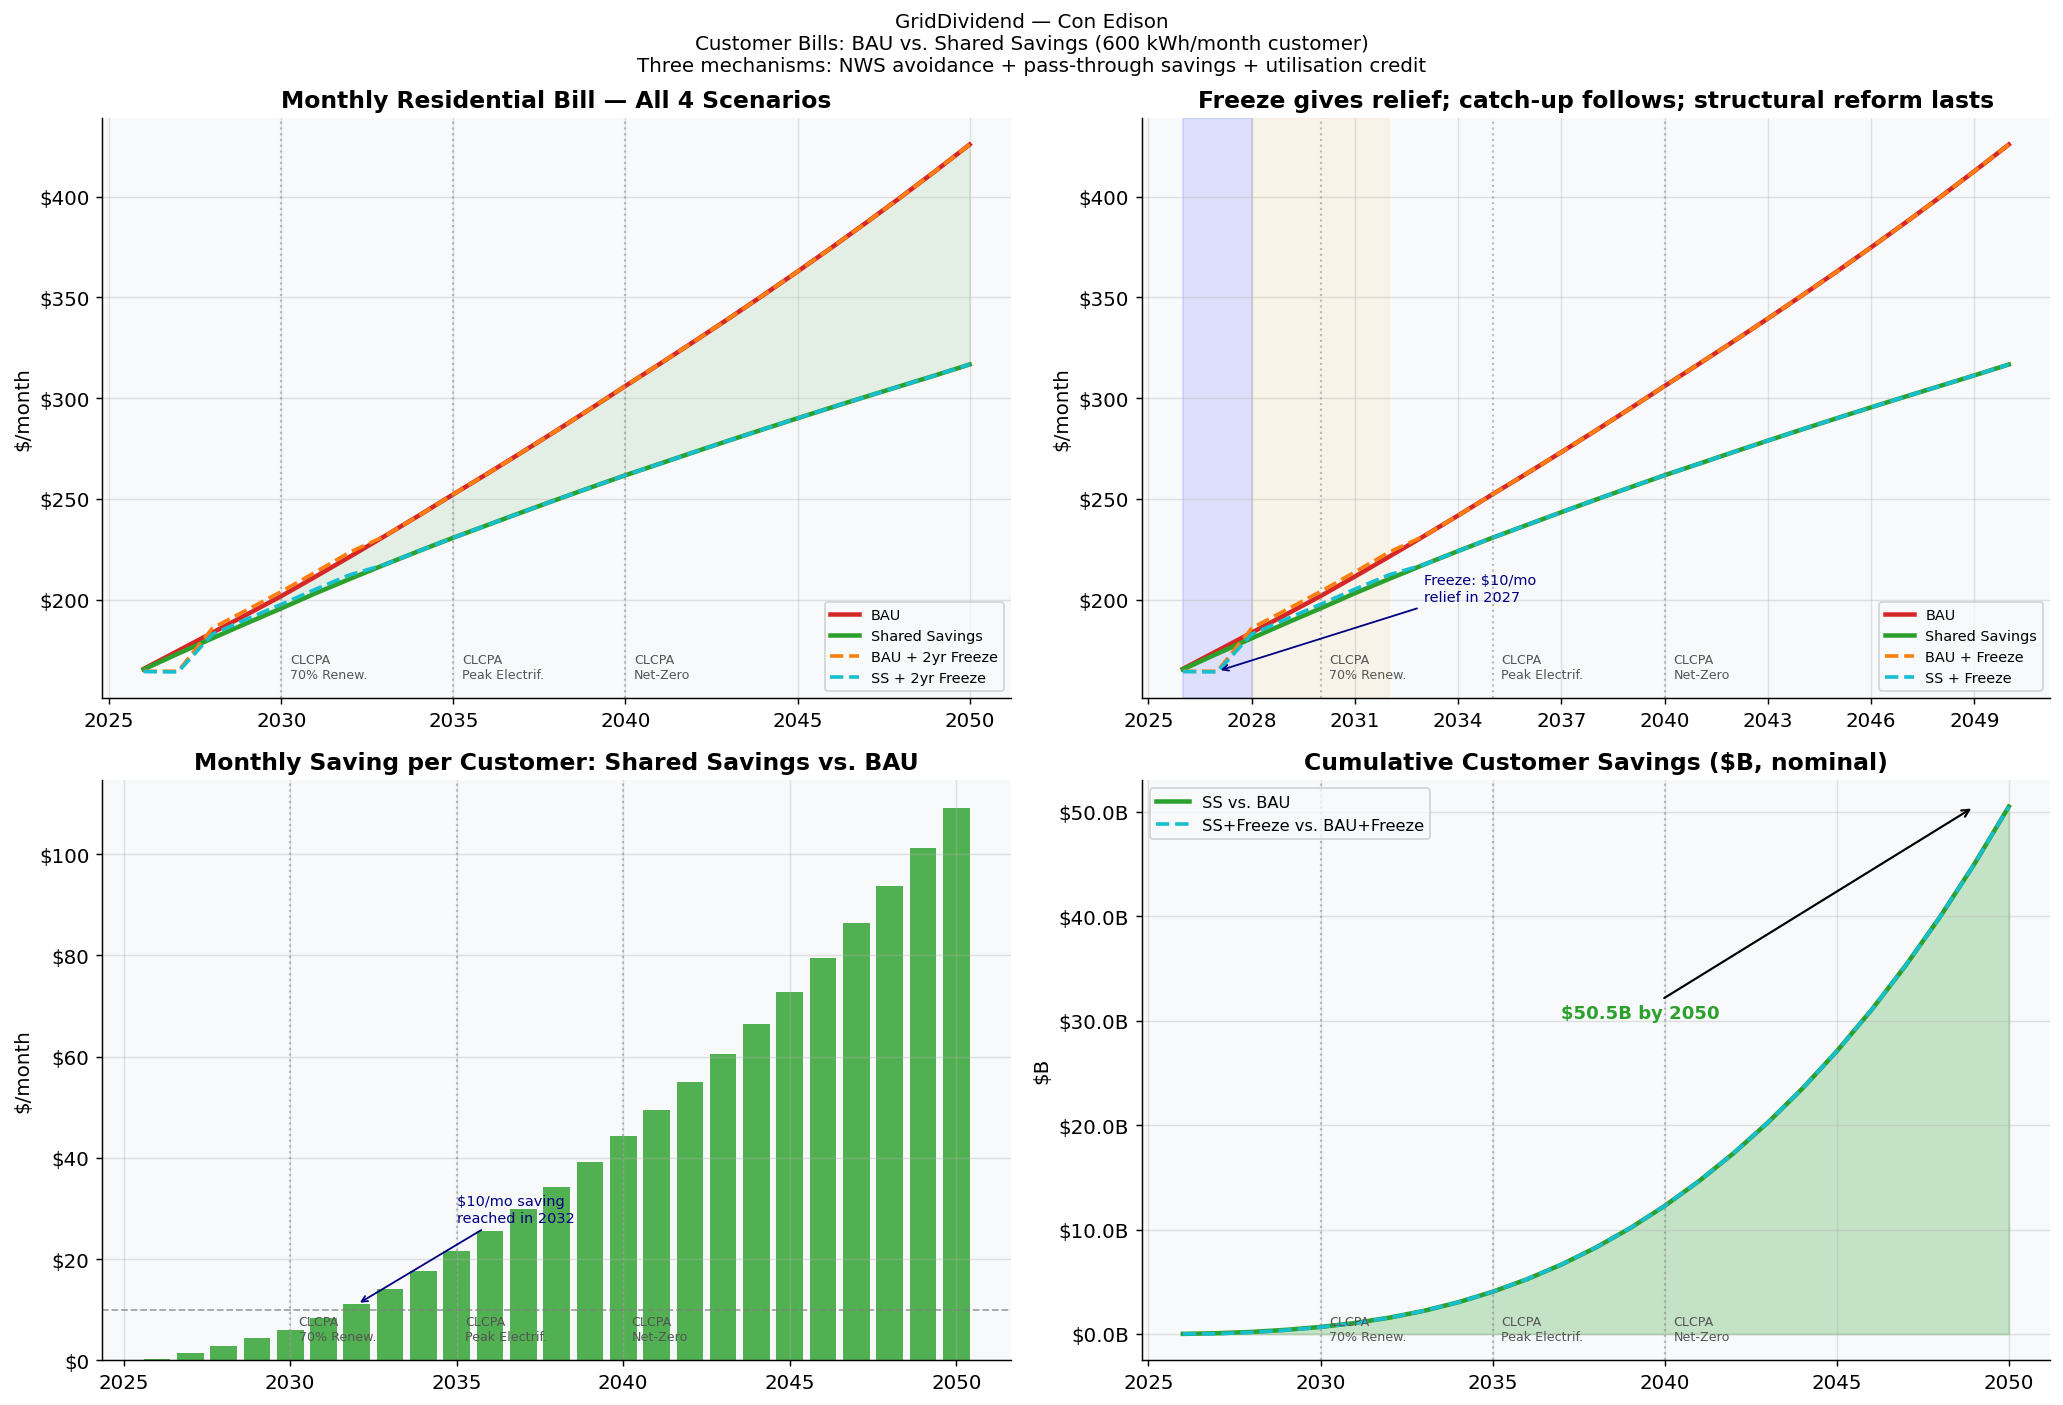


Con Edison — Bill Results Table (600 kWh/month)
  Year    BAU$/mo    SS$/mo    BAU+Frz    SS+Frz   Saving/yr       %    Cum$B
  ----------------------------------------------------------------------
  2026     165.6    165.3     164.4    164.2          3    0.2%      0.0
  2027     174.5    173.1     164.4    164.1         17    0.8%      0.1
  2028     183.6    180.8     185.8    182.8         33    1.5%      0.2
  2030     201.7    195.6     204.0    197.6         73    3.0%      0.7
  2032     221.3    210.3     223.6    212.3        132    5.0%      1.6
  2035     252.2    230.7     252.2    230.7        259    8.5%      4.0
  2040     306.0    261.7     306.0    261.7        532   14.5%     12.3
  2045     362.8    290.0     362.8    290.0        874   20.1%     27.1
  2050     425.8    316.7     425.8    316.7      1,310   25.6%     50.5



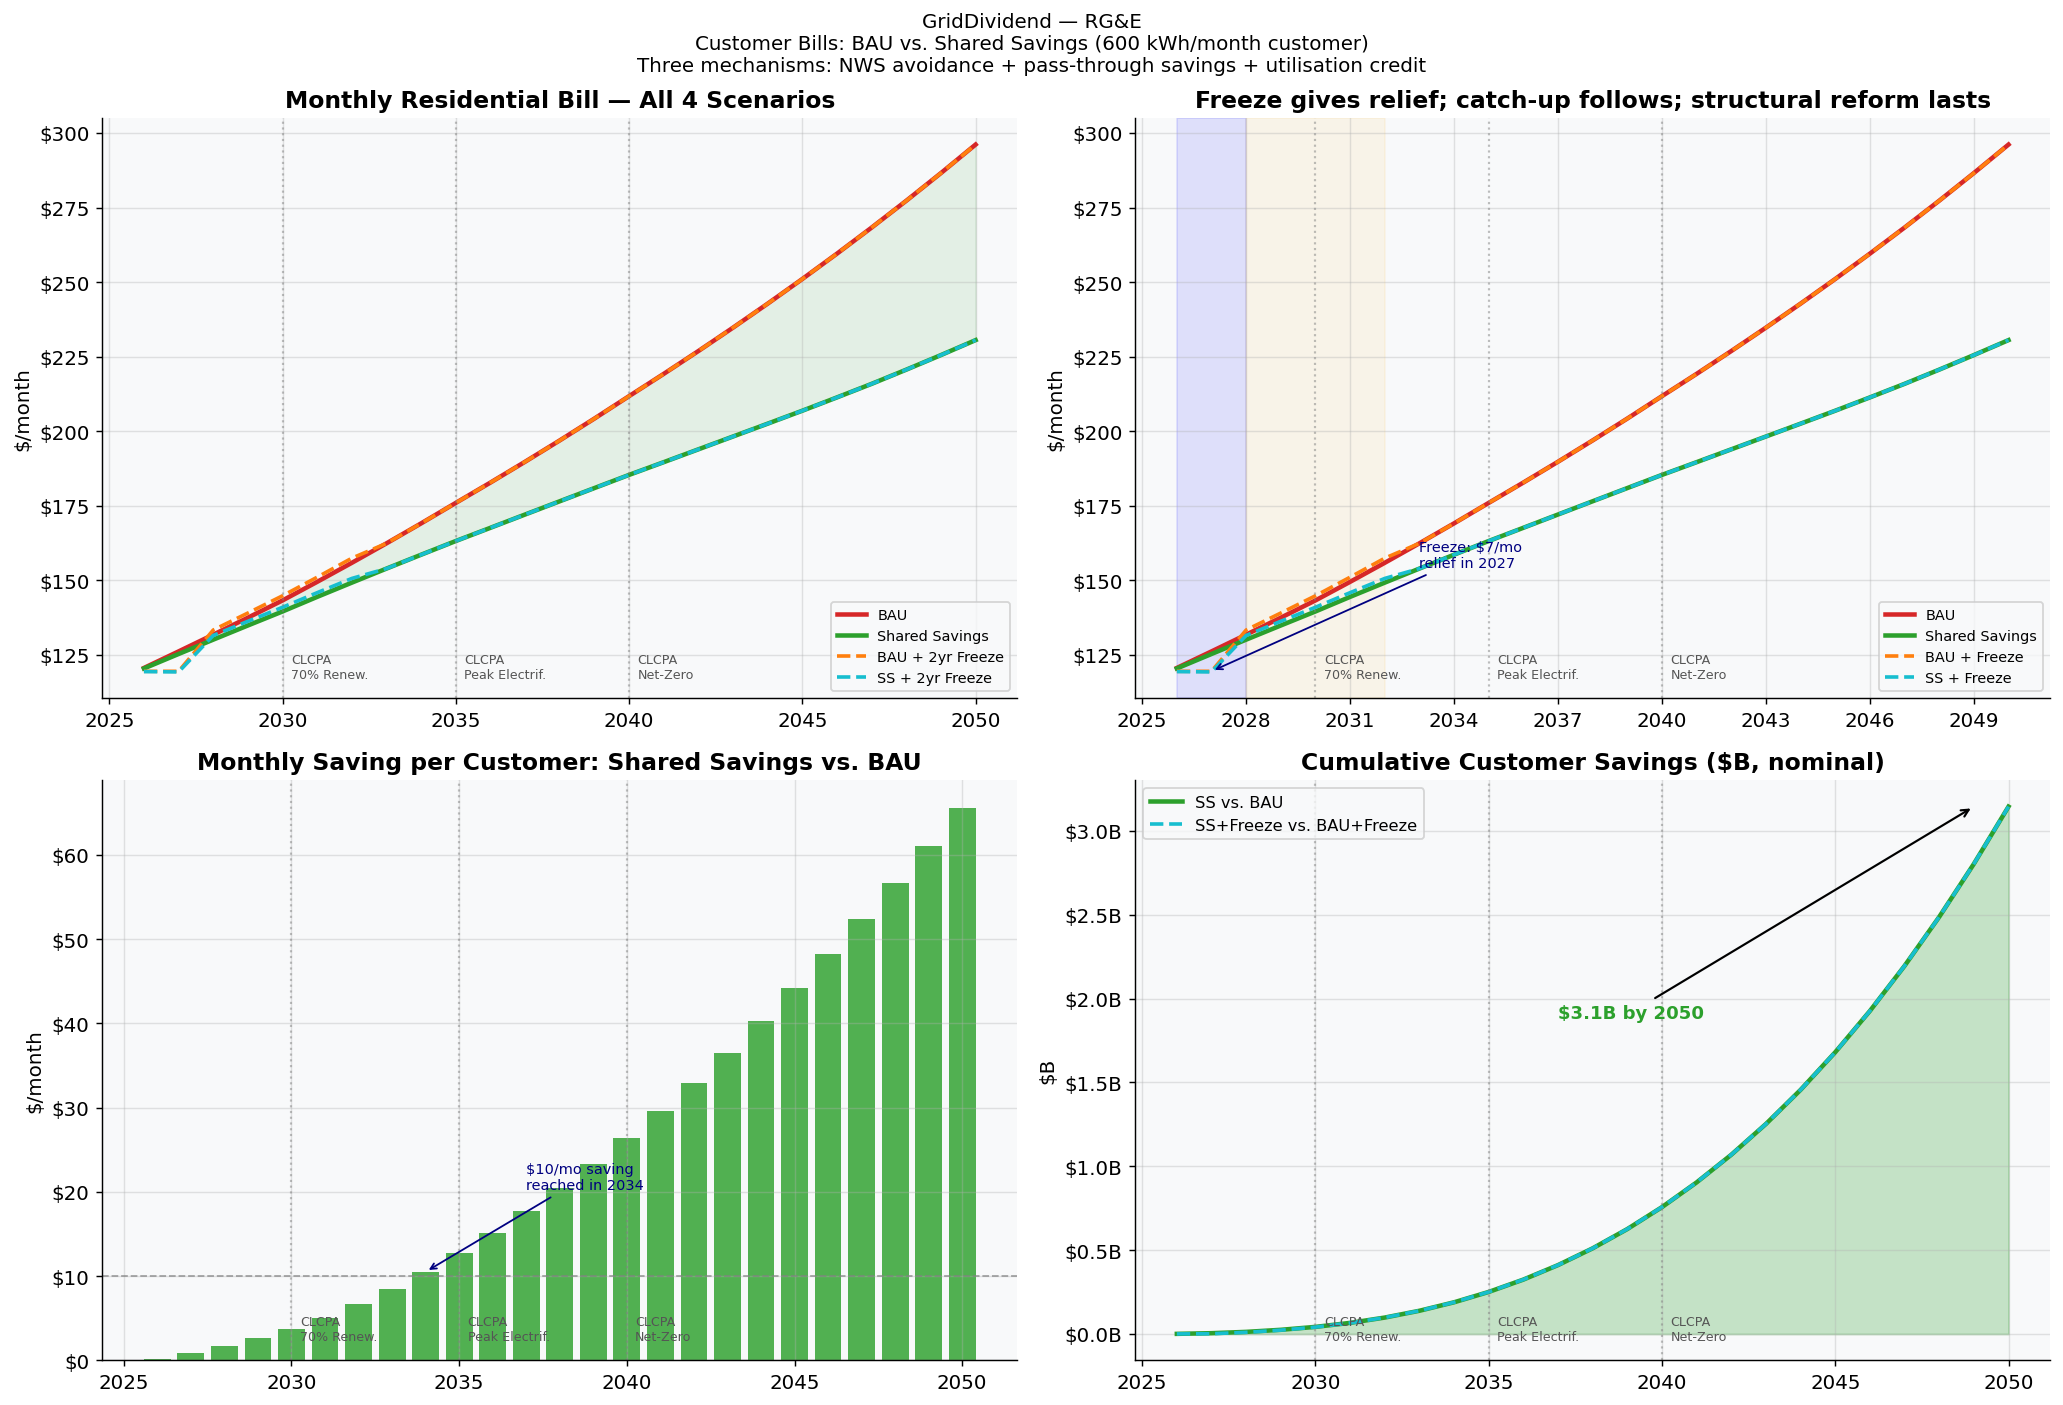


RG&E — Bill Results Table (600 kWh/month)
  Year    BAU$/mo    SS$/mo    BAU+Frz    SS+Frz   Saving/yr       %    Cum$B
  ----------------------------------------------------------------------
  2026     120.6    120.4     119.5    119.4          2    0.1%      0.0
  2027     126.1    125.3     119.5    119.2         10    0.7%      0.0
  2028     131.7    130.1     133.3    131.5         20    1.3%      0.0
  2030     143.2    139.5     144.8    140.9         44    2.6%      0.0
  2032     155.8    149.2     157.4    150.6         80    4.3%      0.1
  2035     175.9    163.2     175.9    163.2        153    7.3%      0.3
  2040     211.7    185.3     211.7    185.3        317   12.5%      0.8
  2045     251.0    206.9     251.0    206.9        530   17.6%      1.7
  2050     296.1    230.5     296.1    230.5        787   22.1%      3.1



In [9]:
for k in utilities_to_run:
    bau   = results[k]['bau'];   sh    = results[k]['shared']
    bau_f = results[k]['bau_freeze']; sh_f = results[k]['shared_freeze']
    name  = UTILITIES[k]['short_name']
    p     = utility_data[k]

    ann_sav_mo = bau['avg_monthly_bill'].values - sh['avg_monthly_bill'].values
    ann_sav_yr = bau['avg_annual_bill'].values  - sh['avg_annual_bill'].values
    cum_sav    = np.cumsum(ann_sav_yr * sh['customers'].values / 1e6) / 1000

    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    fig.suptitle(
        f'GridDividend — {name}\n'
        f'Customer Bills: BAU vs. Shared Savings (600 kWh/month customer)\n'
        f'Three mechanisms: NWS avoidance + pass-through savings + utilisation credit',
        fontsize=11)

    # All 4 scenarios — full timeline
    ax = axes[0, 0]
    ax.plot(YEARS, bau['avg_monthly_bill'],   color=C['bau'],          lw=2.5, label='BAU')
    ax.plot(YEARS, sh['avg_monthly_bill'],    color=C['shared'],        lw=2.5, label='Shared Savings')
    ax.plot(YEARS, bau_f['avg_monthly_bill'], color=C['freeze_bau'],   lw=2, ls='--', label='BAU + 2yr Freeze')
    ax.plot(YEARS, sh_f['avg_monthly_bill'],  color=C['freeze_shared'], lw=2, ls='--', label='SS + 2yr Freeze')
    ax.fill_between(YEARS, sh['avg_monthly_bill'], bau['avg_monthly_bill'], alpha=0.10, color=C['shared'])
    vlines(ax)
    ax.set_title('Monthly Residential Bill — All 4 Scenarios')
    ax.set_ylabel('$/month')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
    ax.legend(fontsize=8)

    # Near-term zoom: freeze effect
    ax = axes[0, 1]
    zoom = list(YEARS)
    filt = lambda df, c: list(df[c])
    ax.plot(zoom, filt(bau,   'avg_monthly_bill'), color=C['bau'],          lw=2.5, label='BAU')
    ax.plot(zoom, filt(sh,    'avg_monthly_bill'), color=C['shared'],        lw=2.5, label='Shared Savings')
    ax.plot(zoom, filt(bau_f, 'avg_monthly_bill'), color=C['freeze_bau'],   lw=2, ls='--', label='BAU + Freeze')
    ax.plot(zoom, filt(sh_f,  'avg_monthly_bill'), color=C['freeze_shared'], lw=2, ls='--', label='SS + Freeze')
    ax.axvspan(2026, 2028, alpha=0.10, color='blue')
    ax.axvspan(2028, 2032, alpha=0.07, color='orange')
    b27  = bau_f[bau_f['year'] == 2027].iloc[0]
    b27n = bau[bau['year']   == 2027].iloc[0]
    relief = b27n['avg_monthly_bill'] - b27['avg_monthly_bill']
    ax.annotate(
        f'Freeze: ${relief:.0f}/mo\nrelief in 2027',
        xy=(2027, b27['avg_monthly_bill']),
        xytext=(2033, b27['avg_monthly_bill'] + 35),
        arrowprops=dict(arrowstyle='->', color='navy', lw=1), fontsize=8, color='navy')
    vlines(ax)
    ax.set_title('Freeze gives relief; catch-up follows; structural reform lasts')
    ax.set_ylabel('$/month')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.legend(fontsize=8)

    # Monthly saving bar chart
    ax = axes[1, 0]
    ax.bar(YEARS, ann_sav_mo,
           color=[C['shared'] if s > 0 else C['bau'] for s in ann_sav_mo],
           alpha=0.82, width=0.8)
    ax.axhline(10, color='gray', ls='--', lw=1, alpha=0.7)
    over10 = np.where(ann_sav_mo > 10)[0]
    if len(over10):
        first_i = over10[0]
        ax.annotate(f'$10/mo saving\nreached in {YEARS[first_i]}',
                    xy=(YEARS[first_i], ann_sav_mo[first_i]),
                    xytext=(YEARS[first_i] + 3, ann_sav_mo[first_i] + ann_sav_mo.max() * 0.15),
                    arrowprops=dict(arrowstyle='->', color='navy', lw=1),
                    fontsize=8, color='navy')
    vlines(ax)
    ax.set_title('Monthly Saving per Customer: Shared Savings vs. BAU')
    ax.set_ylabel('$/month')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

    # Cumulative savings
    ax = axes[1, 1]
    ax.fill_between(YEARS, 0, cum_sav, alpha=0.25, color=C['shared'])
    ax.plot(YEARS, cum_sav, color=C['shared'], lw=2.5, label='SS vs. BAU')
    ann_sav_f = bau_f['avg_annual_bill'].values - sh_f['avg_annual_bill'].values
    cum_sav_f = np.cumsum(ann_sav_f * sh_f['customers'].values / 1e6) / 1000
    ax.plot(YEARS, cum_sav_f, color=C['freeze_shared'], lw=2, ls='--', label='SS+Freeze vs. BAU+Freeze')
    vlines(ax)
    ax.set_title('Cumulative Customer Savings ($B, nominal)')
    ax.set_ylabel('$B')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.1f}B'))
    final = cum_sav[-1]
    ax.annotate(f'${final:.1f}B by 2050', xy=(2049, final), xytext=(2037, final * 0.6),
        arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
        fontsize=10, fontweight='bold', color=C['shared'])
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(f'charts/chart1_bills_{k.lower()}.png', bbox_inches='tight', dpi=130)
    plt.show()

    # Results table
    print(f"\n{name} — Bill Results Table (600 kWh/month)")
    print(f"  {'Year':>4}  {'BAU$/mo':>9}  {'SS$/mo':>8}  {'BAU+Frz':>9}  {'SS+Frz':>8}"
          f"  {'Saving/yr':>10}  {'%':>6}  {'Cum$B':>7}")
    print("  " + "-" * 70)
    for yr in [2026, 2027, 2028, 2030, 2032, 2035, 2040, 2045, 2050]:
        br  = bau[bau['year']   == yr].iloc[0]
        sr  = sh[sh['year']    == yr].iloc[0]
        brf = bau_f[bau_f['year'] == yr].iloc[0]
        srf = sh_f[sh_f['year']  == yr].iloc[0]
        sv  = br['avg_annual_bill'] - sr['avg_annual_bill']
        idx = YEARS.index(yr)
        cumv = np.sum(
            (bau['avg_annual_bill'].values[:idx+1] - sh['avg_annual_bill'].values[:idx+1])
            * sh['customers'].values[:idx+1]) / 1e9
        print(f"  {yr:4d}   {br['avg_monthly_bill']:>7,.1f}   {sr['avg_monthly_bill']:>6,.1f}"
              f"   {brf['avg_monthly_bill']:>7,.1f}   {srf['avg_monthly_bill']:>6,.1f}"
              f"   {sv:>8,.0f}   {sv/br['avg_annual_bill']:>5.1%}   {cumv:>6.1f}")
    print()

## Section 6: Infrastructure Spending — CAPEX & OPEX

Shows utilities still invest heavily under shared savings — NWS defers a growing but bounded share of growth-driven upgrades. Both CAPEX spent and CAPEX avoided increase year-on-year.

Both utilities are shown. **Con Edison**: cumulative grid spend 2026–2050 (CAPEX plus NWS OPEX, undiscounted nominal) falls from ~$154B BAU to ~$120B SS (~$33B, 22% saving). **RG&E**: from ~$8.3B BAU to ~$6.3B SS (~$2.0B, 24% saving). RG&E's proportionally larger saving reflects its programme being more heavily weighted toward growth-driven overhead reinforcements well-suited to NWS deferral.

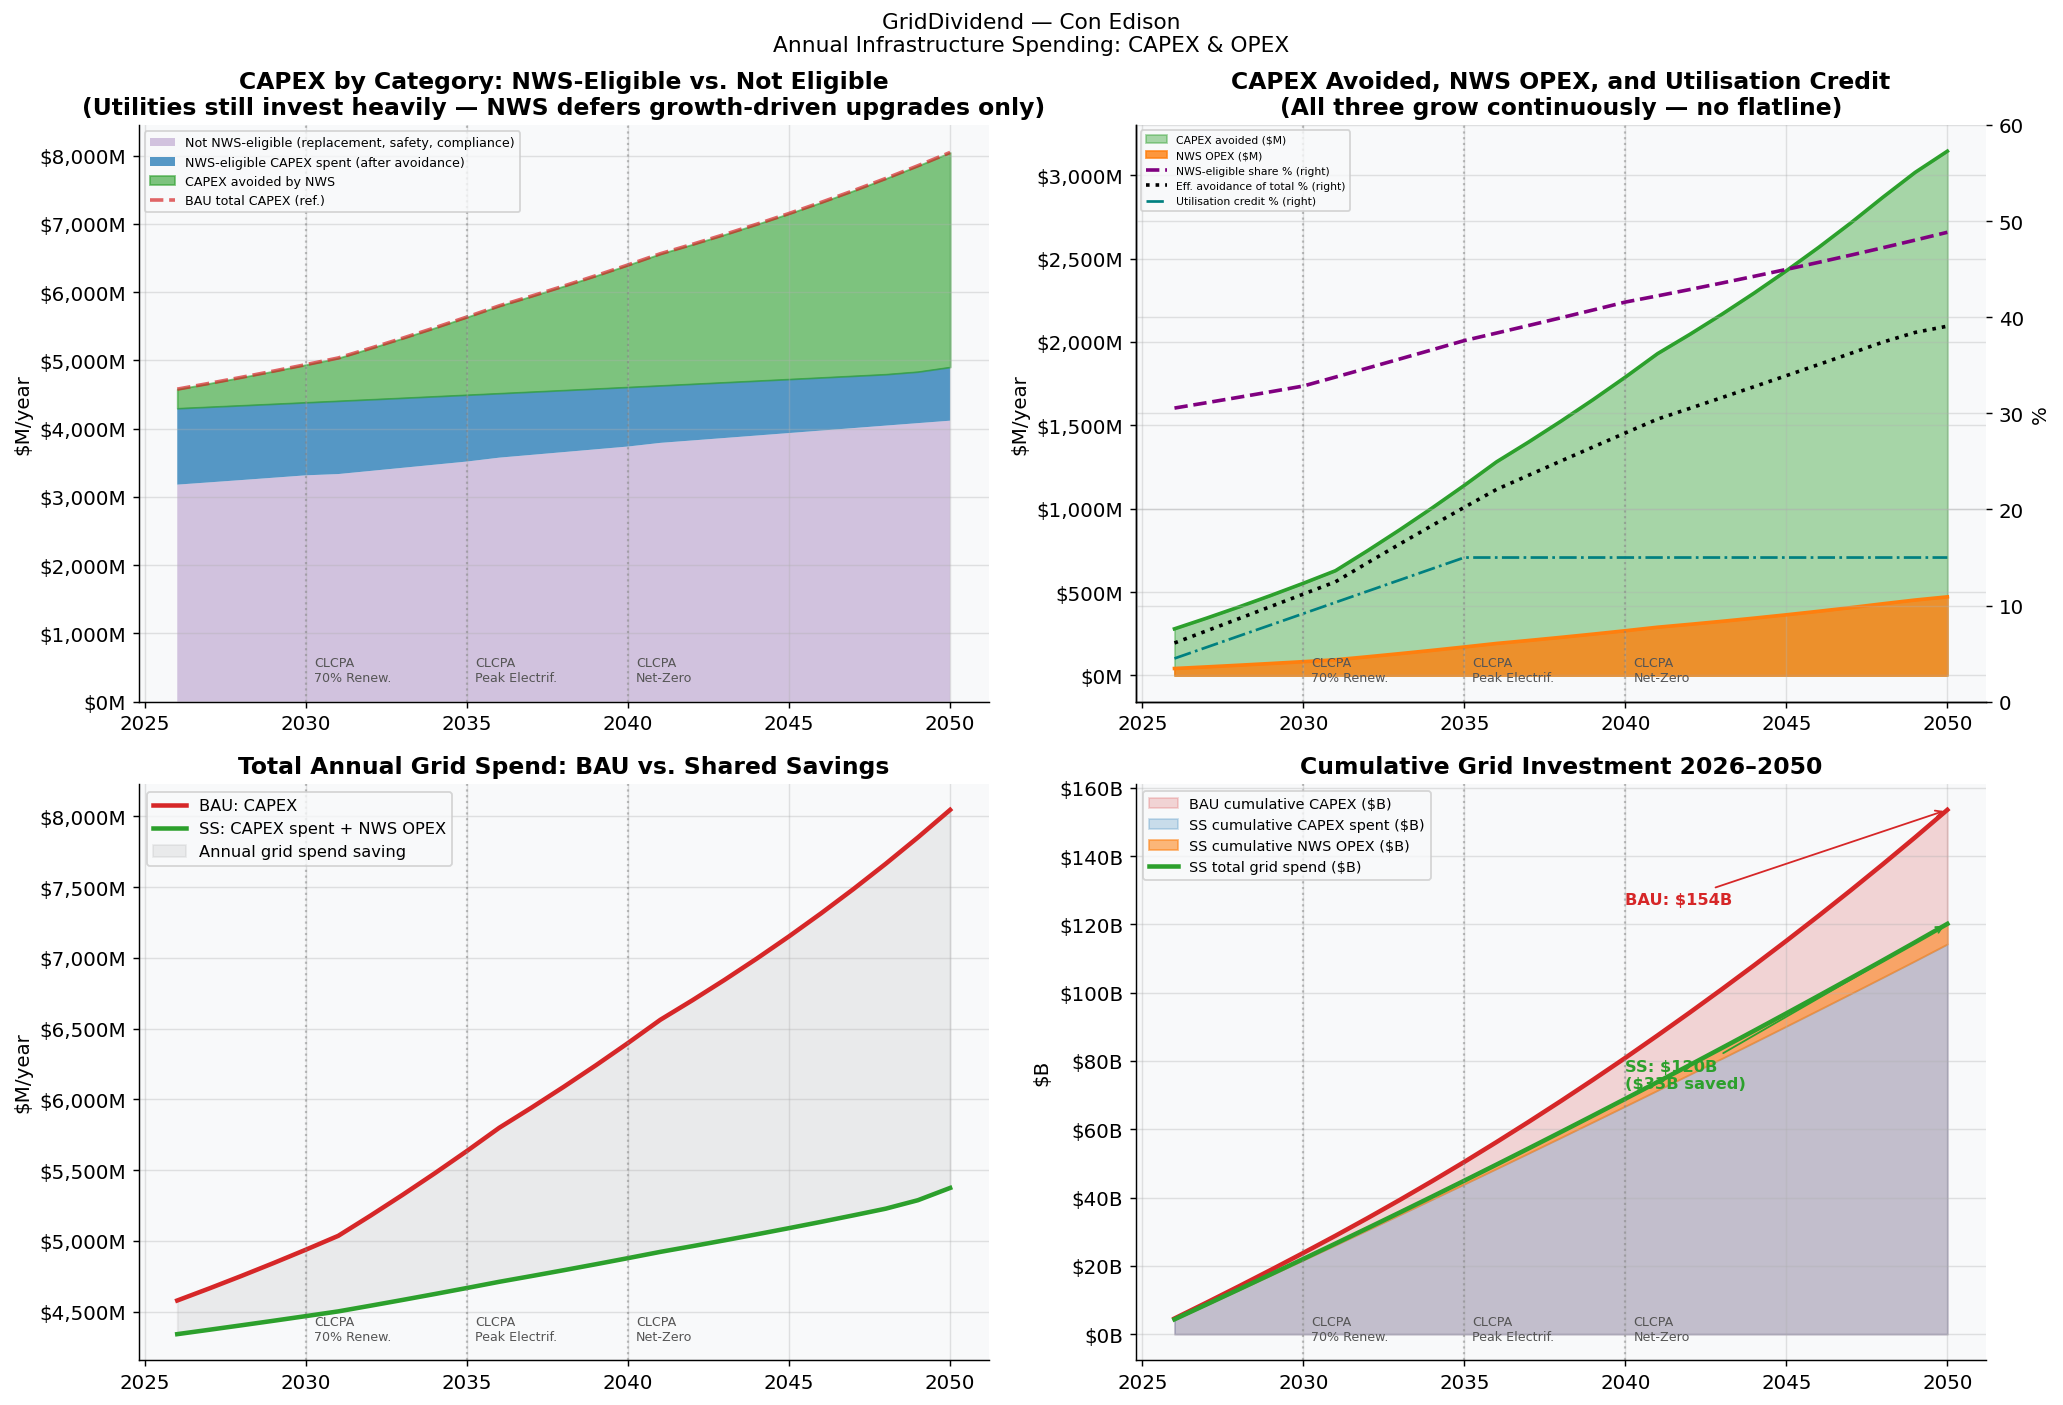


Con Edison — CAPEX & NWS OPEX Table
  Year    BAU CAPEX    Elig%    Avoided    SS Spent    NWS OPEX   Eff.Avoid%
  ------------------------------------------------------------------------
  2026       4,579    30.5%      280      4,299         42         6.1%
  2028       4,753    31.7%      411      4,342         62         8.6%
  2030       4,939    32.8%      553      4,386         83        11.2%
  2035       5,636    37.6%    1,140      4,497        171        20.2%
  2040       6,399    41.6%    1,789      4,610        268        28.0%
  2045       7,153    45.0%    2,426      4,727        364        33.9%
  2050       8,047    48.8%    3,144      4,903        472        39.1%



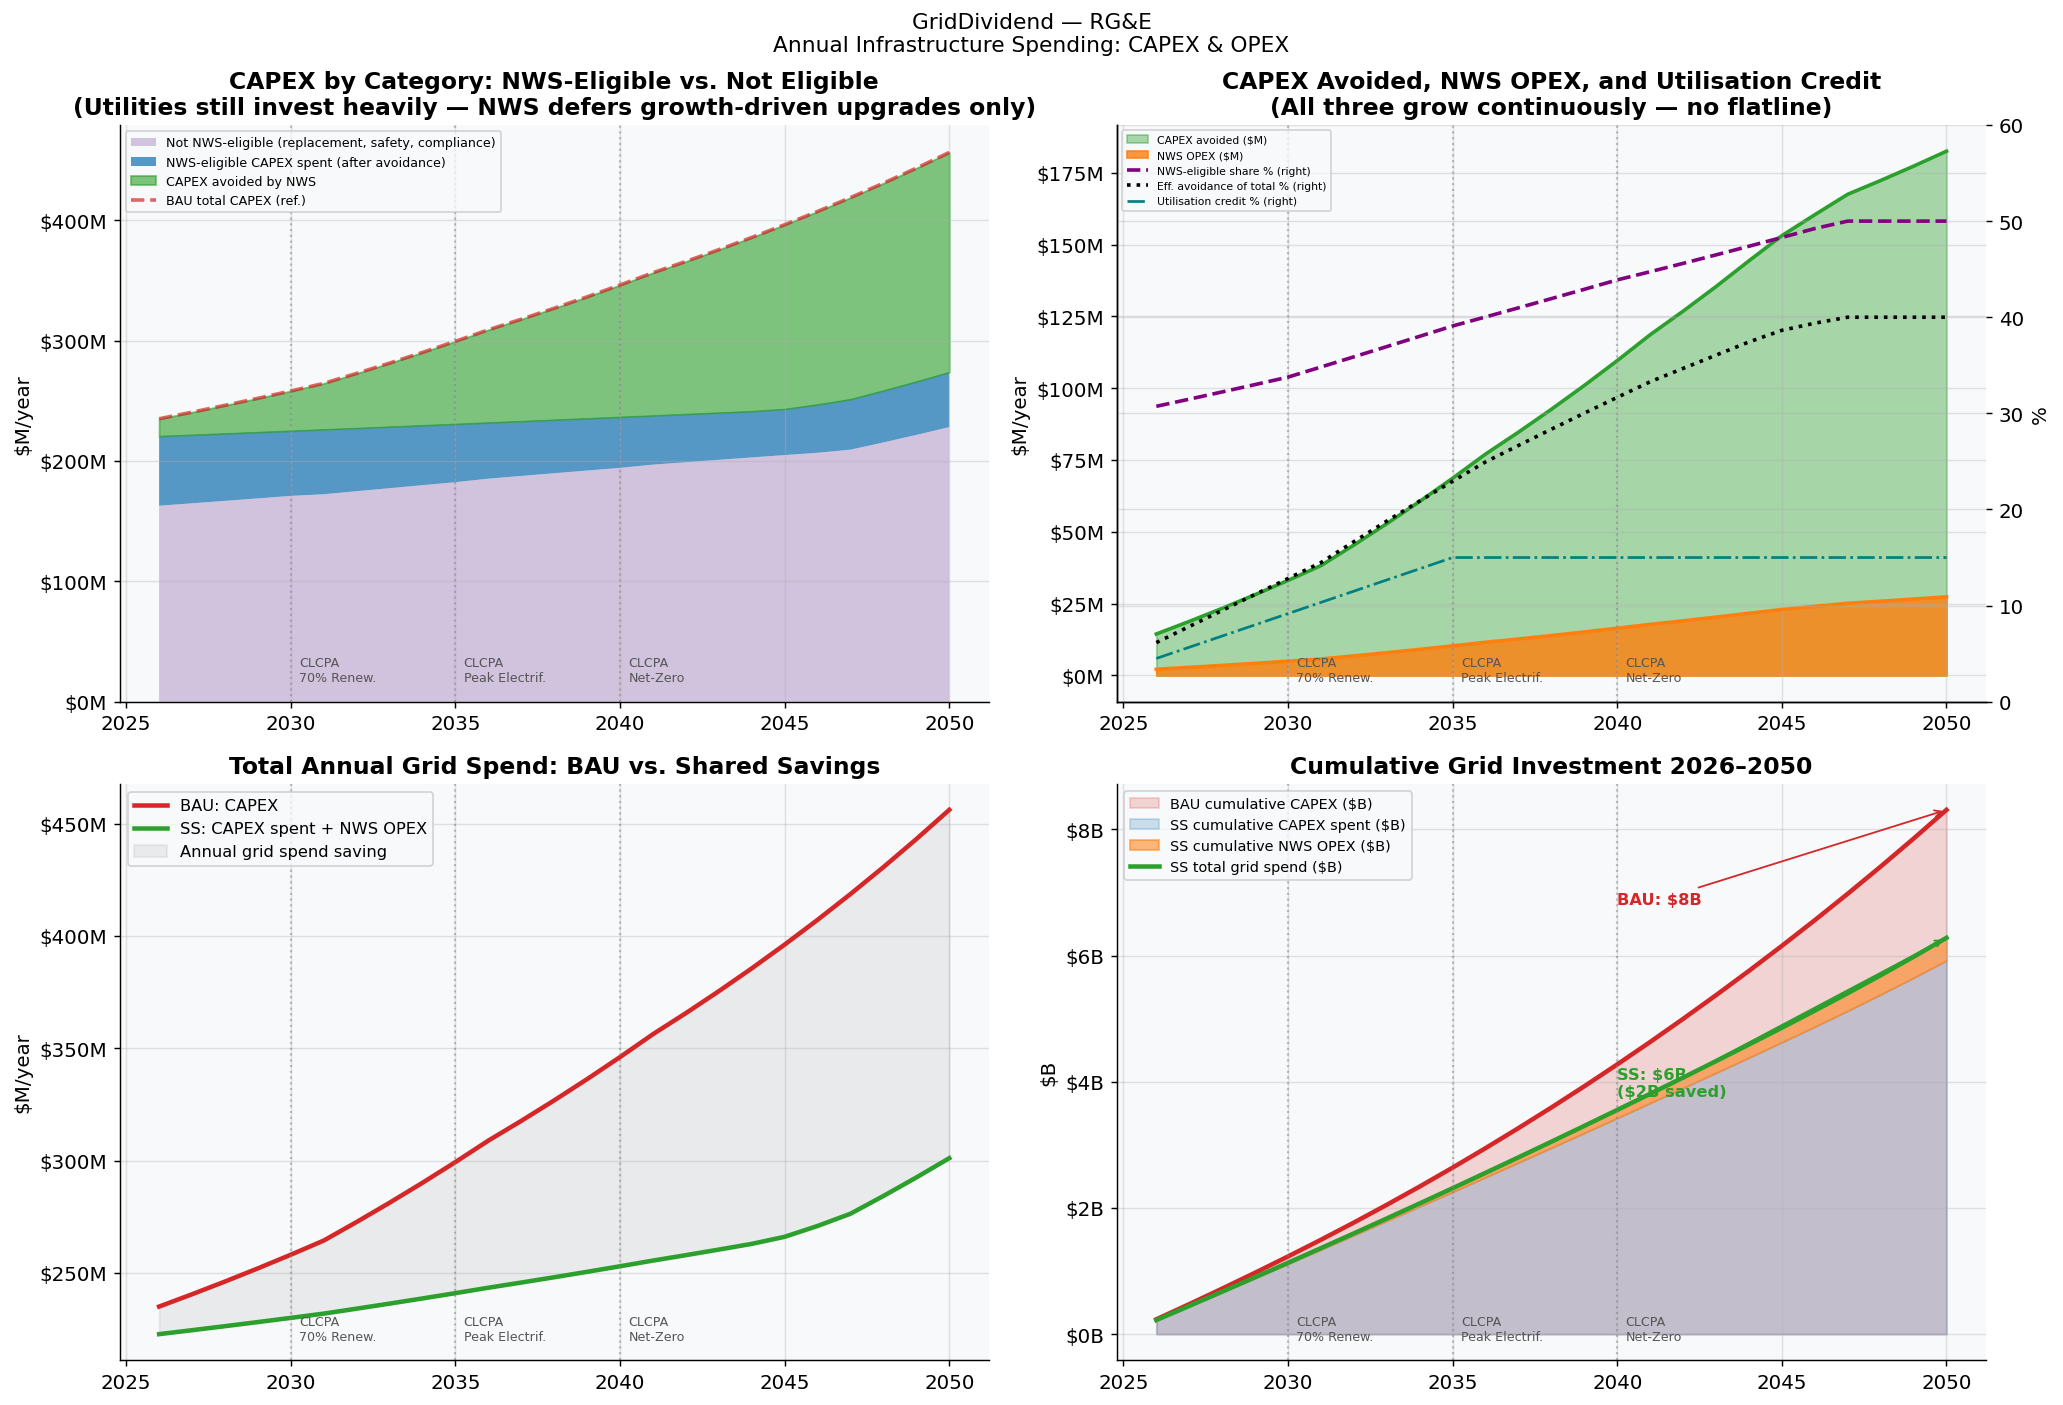


RG&E — CAPEX & NWS OPEX Table
  Year    BAU CAPEX    Elig%    Avoided    SS Spent    NWS OPEX   Eff.Avoid%
  ------------------------------------------------------------------------
  2026         235    30.7%       14        221          2         6.1%
  2028         246    32.2%       23        223          4         9.5%
  2030         258    33.8%       33        225          5        12.8%
  2035         299    39.1%       69        231         10        22.9%
  2040         346    43.9%      110        237         16        31.7%
  2045         396    48.3%      153        243         23        38.6%
  2050         456    50.0%      182        274         27        40.0%



In [10]:
for k in utilities_to_run:
    bau  = results[k]['bau']; sh = results[k]['shared']
    name = UTILITIES[k]['short_name']
    bau_cum    = np.cumsum(bau['capex_spent_m'].values)
    ss_cum     = np.cumsum(sh['capex_spent_m'].values)
    ss_nws_cum = np.cumsum(sh['nws_opex_m'].values)

    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    fig.suptitle(f'GridDividend — {name}\nAnnual Infrastructure Spending: CAPEX & OPEX', fontsize=12)

    ax = axes[0, 0]
    ax.stackplot(YEARS, sh['capex_ineligible_m'],
                 sh['capex_spent_m'] - sh['capex_ineligible_m'],
                 labels=['Not NWS-eligible (replacement, safety, compliance)',
                         'NWS-eligible CAPEX spent (after avoidance)'],
                 colors=[C['ineligible'], C['capex_spent']], alpha=0.75)
    ax.fill_between(YEARS, sh['capex_spent_m'], sh['capex_total_programme_m'],
                    alpha=0.60, color=C['capex_avoided'], label='CAPEX avoided by NWS')
    ax.plot(YEARS, bau['capex_spent_m'], color=C['bau'], lw=2, ls='--', alpha=0.7,
            label='BAU total CAPEX (ref.)')
    vlines(ax)
    ax.set_title('CAPEX by Category: NWS-Eligible vs. Not Eligible\n'
                 '(Utilities still invest heavily — NWS defers growth-driven upgrades only)')
    ax.set_ylabel('$M/year')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(fontsize=7, loc='upper left')

    ax = axes[0, 1]
    ax2 = ax.twinx()
    ax.fill_between(YEARS, 0, sh['capex_avoided_m'], alpha=0.40, color=C['capex_avoided'],
                    label='CAPEX avoided ($M)')
    ax.fill_between(YEARS, 0, sh['nws_opex_m'], alpha=0.80, color=C['opex_nws'],
                    label='NWS OPEX ($M)')
    ax.plot(YEARS, sh['capex_avoided_m'], color=C['capex_avoided'], lw=2)
    ax.plot(YEARS, sh['nws_opex_m'],      color=C['opex_nws'],      lw=2)
    ax2.plot(YEARS, sh['nws_eligible_share_pct'],       color='purple', lw=2, ls='--',
             label='NWS-eligible share % (right)')
    ax2.plot(YEARS, sh['capex_avoidance_pct_of_total'], color='black',  lw=2, ls=':',
             label='Eff. avoidance of total % (right)')
    ax2.plot(YEARS, sh['utilisation_credit_pct'].values,
             color='teal', lw=1.5, ls='-.', label='Utilisation credit % (right)')
    ax2.set_ylim(0, 60); ax2.set_ylabel('%')
    vlines(ax)
    ax.set_title('CAPEX Avoided, NWS OPEX, and Utilisation Credit\n'
                 '(All three grow continuously — no flatline)')
    ax.set_ylabel('$M/year')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    l1, lb1 = ax.get_legend_handles_labels(); l2, lb2 = ax2.get_legend_handles_labels()
    ax.legend(l1 + l2, lb1 + lb2, fontsize=6, loc='upper left')

    ax = axes[1, 0]
    ax.plot(YEARS, bau['capex_spent_m'],    color=C['bau'],    lw=2.5, label='BAU: CAPEX')
    ax.plot(YEARS, sh['total_grid_spend_m'], color=C['shared'], lw=2.5,
            label='SS: CAPEX spent + NWS OPEX')
    ax.fill_between(YEARS, sh['total_grid_spend_m'], bau['capex_spent_m'],
                    alpha=0.13, color=C['neutral'], label='Annual grid spend saving')
    vlines(ax)
    ax.set_title('Total Annual Grid Spend: BAU vs. Shared Savings')
    ax.set_ylabel('$M/year')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(fontsize=9)

    ax = axes[1, 1]
    ax.fill_between(YEARS, 0, bau_cum / 1000, alpha=0.18, color=C['bau'],
                    label='BAU cumulative CAPEX ($B)')
    ax.fill_between(YEARS, 0, ss_cum / 1000, alpha=0.22, color=C['capex_spent'],
                    label='SS cumulative CAPEX spent ($B)')
    ax.fill_between(YEARS, ss_cum / 1000, (ss_cum + ss_nws_cum) / 1000, alpha=0.55,
                    color=C['opex_nws'], label='SS cumulative NWS OPEX ($B)')
    ax.plot(YEARS, bau_cum / 1000, color=C['bau'], lw=2.5)
    ax.plot(YEARS, (ss_cum + ss_nws_cum) / 1000, color=C['shared'], lw=2.5,
            label='SS total grid spend ($B)')
    b2050 = bau_cum[-1] / 1000; s2050 = (ss_cum[-1] + ss_nws_cum[-1]) / 1000
    ax.annotate(f'BAU: ${b2050:.0f}B', xy=(2050, b2050), xytext=(2040, b2050 * 0.82),
        arrowprops=dict(arrowstyle='->', color=C['bau'], lw=1),
        fontsize=9, color=C['bau'], fontweight='bold')
    ax.annotate(f'SS: ${s2050:.0f}B\n(${b2050-s2050:.0f}B saved)',
        xy=(2050, s2050), xytext=(2040, s2050 * 0.60),
        arrowprops=dict(arrowstyle='->', color=C['shared'], lw=1),
        fontsize=9, color=C['shared'], fontweight='bold')
    vlines(ax)
    ax.set_title('Cumulative Grid Investment 2026–2050')
    ax.set_ylabel('$B')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}B'))
    ax.legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(f'charts/chart2_capex_opex_{k.lower()}.png', bbox_inches='tight', dpi=130)
    plt.show()

    print(f"\n{name} — CAPEX & NWS OPEX Table")
    print(f"  {'Year':>4}  {'BAU CAPEX':>11}  {'Elig%':>7}  {'Avoided':>9}  "
          f"{'SS Spent':>10}  {'NWS OPEX':>10}  {'Eff.Avoid%':>11}")
    print("  " + "-" * 72)
    for yr in [2026, 2028, 2030, 2035, 2040, 2045, 2050]:
        br = bau[bau['year'] == yr].iloc[0]; sr = sh[sh['year'] == yr].iloc[0]
        print(f"  {yr:4d}   {br['capex_spent_m']:>9,.0f}  "
              f"{sr['nws_eligible_share_pct']:>6.1f}%  "
              f"{sr['capex_avoided_m']:>7,.0f}   "
              f"{sr['capex_spent_m']:>8,.0f}   "
              f"{sr['nws_opex_m']:>8,.0f}   "
              f"{sr['capex_avoidance_pct_of_total']:>9.1f}%")
    print()

## Section 7: Utility Financial Results

Under shared savings, utility revenue exceeds BAU in the **early years** of the programme — the period when the utility most needs the commercial incentive to build NWS capabilities. As the avoided rate base accumulates, the compounding effect of foregone traditional earnings creates a crossover around the mid-2030s. This underscores why regulatory design matters: the shared savings percentage, performance corridor, and ROE framework need to be calibrated to keep the utility commercially motivated throughout the programme, not just in its early years.

**The early-year arithmetic:** the utility earns ~25¢ of shared savings income per $1 of deferred CAPEX but loses only ~7¢ in traditional earnings — a net benefit of ~18¢ per deferred dollar. This is what makes the reform commercially viable in its critical early phase.

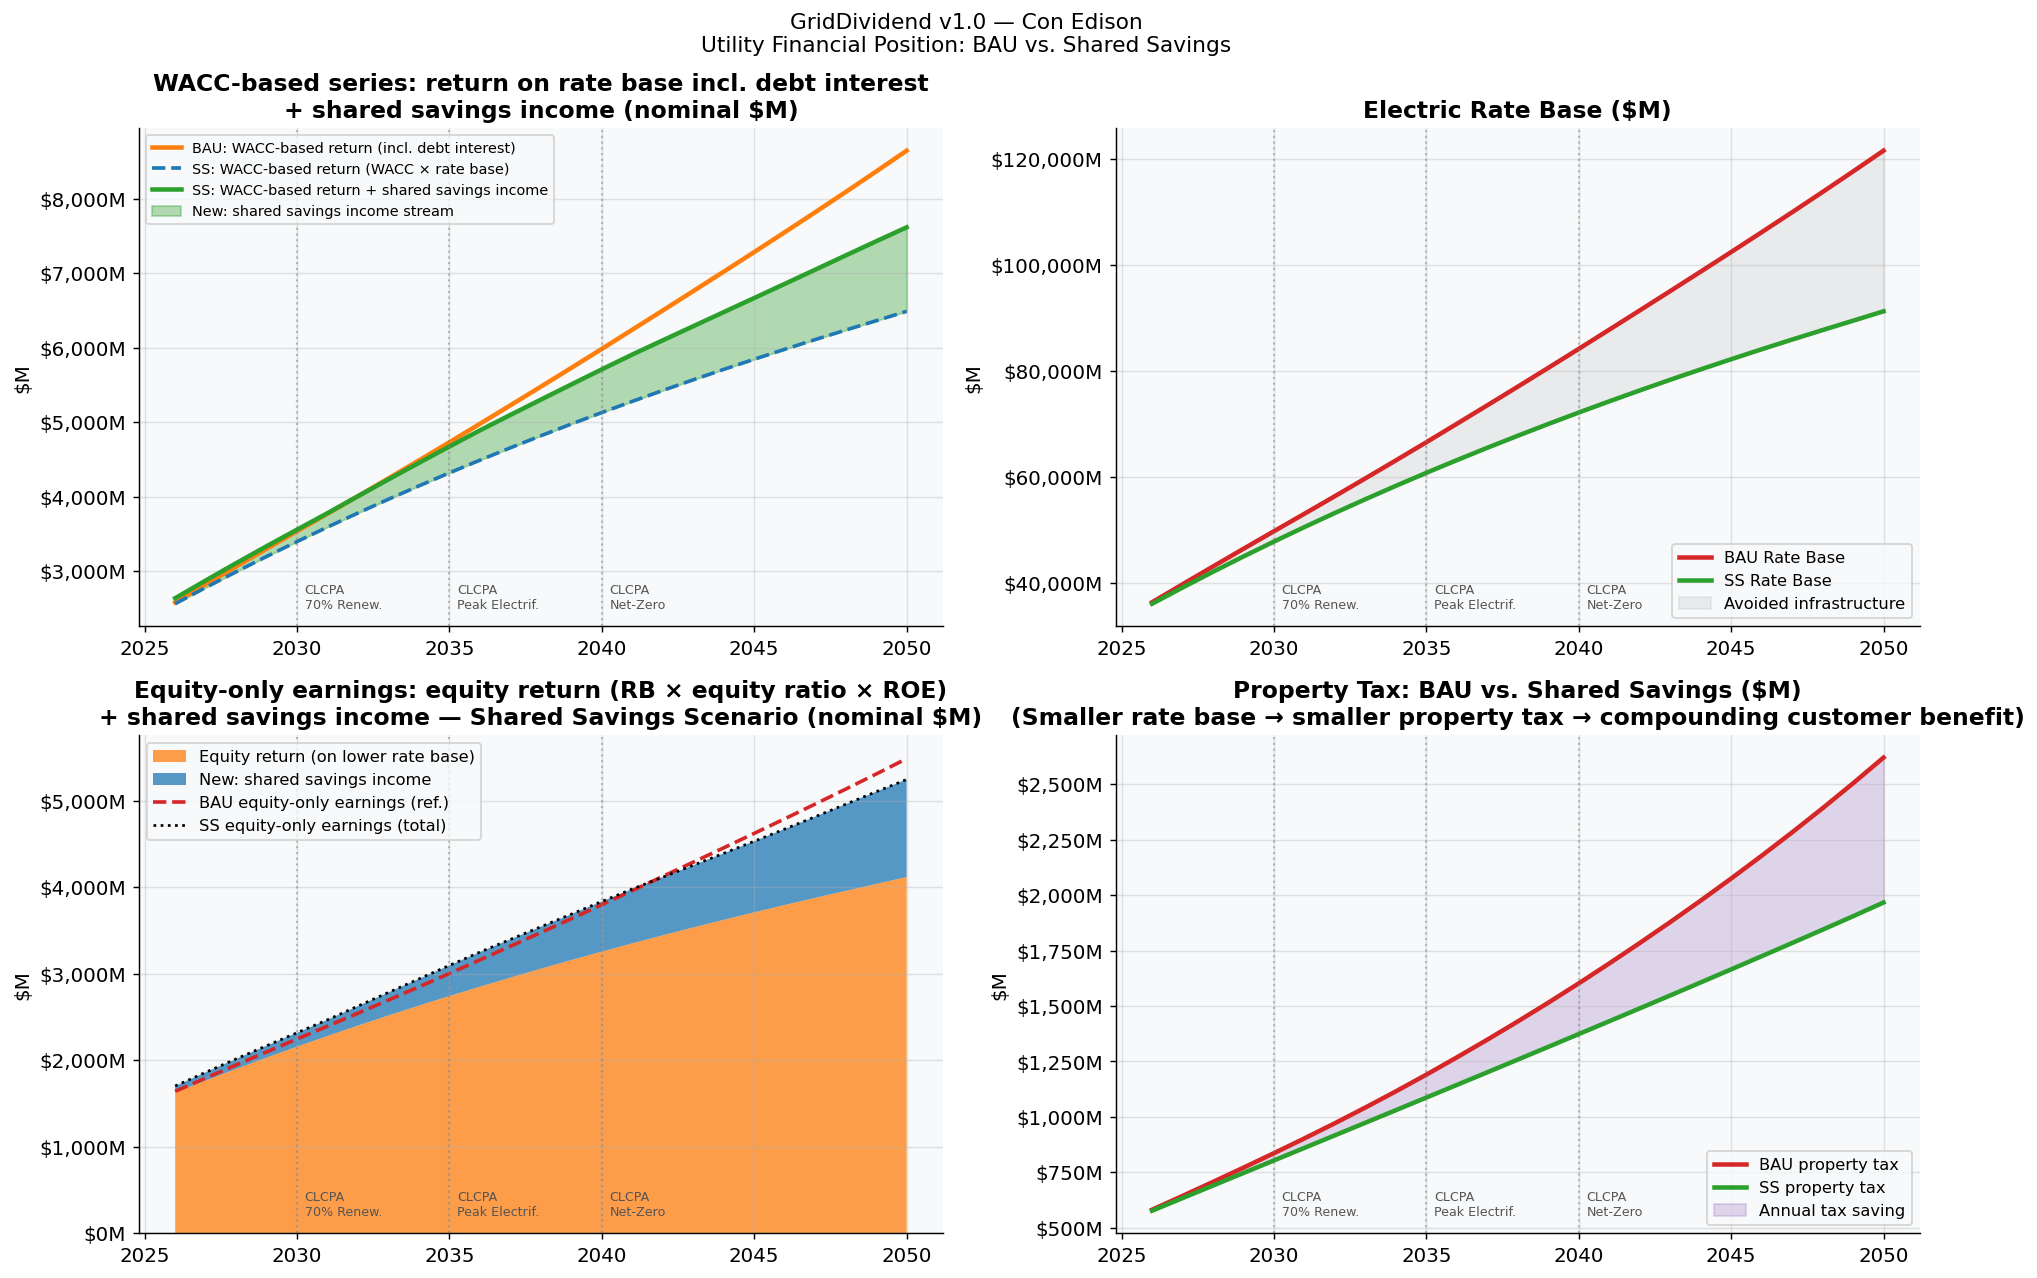

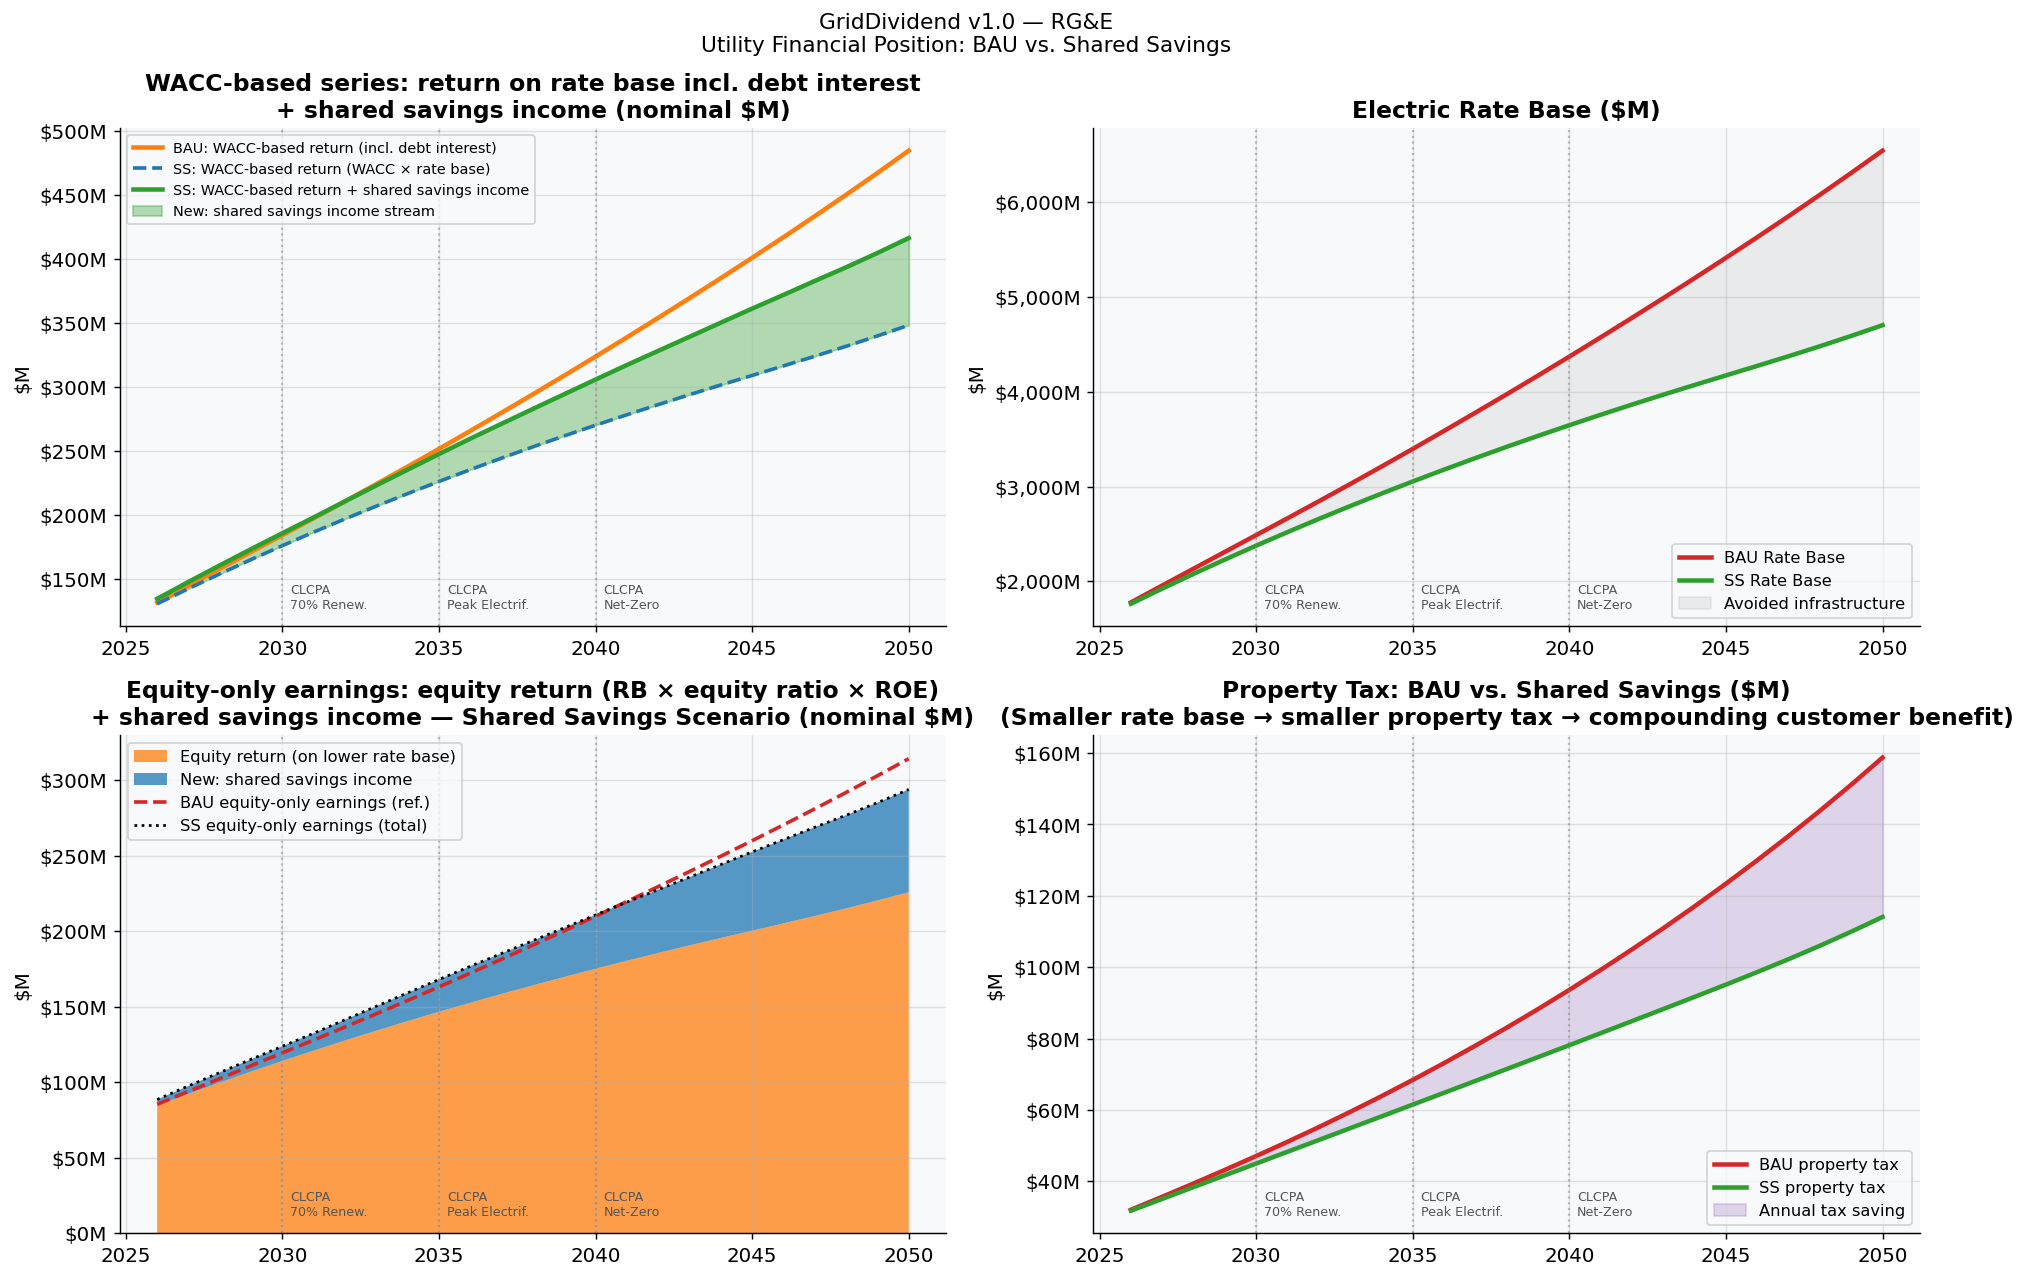

In [11]:
for k in utilities_to_run:
    bau  = results[k]['bau']; sh = results[k]['shared']
    name = UTILITIES[k]['short_name']

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle(f'GridDividend v1.0 — {name}\nUtility Financial Position: BAU vs. Shared Savings',
                 fontsize=12)

    ax = axes[0, 0]
    ax.plot(YEARS, bau['total_utility_revenue_m'], color=C['util_bau'], lw=2.5, label='BAU: WACC-based return (incl. debt interest)')
    ax.plot(YEARS, sh['traditional_earnings_m'], color=C['util_shared'], lw=2, ls='--',
            label='SS: WACC-based return (WACC × rate base)')
    ax.plot(YEARS, sh['total_utility_revenue_m'], color=C['shared'], lw=2.5,
            label='SS: WACC-based return + shared savings income')
    ax.fill_between(YEARS, sh['traditional_earnings_m'], sh['total_utility_revenue_m'],
                    alpha=0.35, color=C['shared'], label='New: shared savings income stream')
    vlines(ax)
    ax.set_title('WACC-based series: return on rate base incl. debt interest\n'
                 '+ shared savings income (nominal $M)')
    ax.set_ylabel('$M')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(fontsize=8, loc='upper left')

    ax = axes[0, 1]
    ax.plot(YEARS, bau['rate_base_m'], color=C['bau'],    lw=2.5, label='BAU Rate Base')
    ax.plot(YEARS, sh['rate_base_m'],  color=C['shared'], lw=2.5, label='SS Rate Base')
    ax.fill_between(YEARS, sh['rate_base_m'], bau['rate_base_m'],
                    alpha=0.13, color=C['neutral'], label='Avoided infrastructure')
    vlines(ax)
    ax.set_title('Electric Rate Base ($M)')
    ax.set_ylabel('$M')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(fontsize=9)

    ax = axes[1, 0]
    ax.stackplot(YEARS, sh['roe_earnings_m'], sh['utility_shared_revenue_m'],
        labels=['Equity return (on lower rate base)', 'New: shared savings income'],
        colors=[C['util_bau'], C['util_shared']], alpha=0.75)
    ax.plot(YEARS, bau['equity_earnings_m'], color=C['bau'], lw=2, ls='--',
            label='BAU equity-only earnings (ref.)')
    ax.plot(YEARS, sh['equity_earnings_m'], color='black', lw=1.5, ls=':',
            label='SS equity-only earnings (total)')
    vlines(ax)
    ax.set_title('Equity-only earnings: equity return (RB × equity ratio × ROE)\n'
                 '+ shared savings income — Shared Savings Scenario (nominal $M)')
    ax.set_ylabel('$M')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(fontsize=9)

    ax = axes[1, 1]
    ax.plot(YEARS, bau['property_tax_m'], color=C['bau'],    lw=2.5, label='BAU property tax')
    ax.plot(YEARS, sh['property_tax_m'],  color=C['shared'], lw=2.5, label='SS property tax')
    ax.fill_between(YEARS, sh['property_tax_m'], bau['property_tax_m'],
                    alpha=0.25, color=C['tax'], label='Annual tax saving')
    vlines(ax)
    ax.set_title('Property Tax: BAU vs. Shared Savings ($M)\n'
                 '(Smaller rate base → smaller property tax → compounding customer benefit)')
    ax.set_ylabel('$M')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(f'charts/chart3_utility_{k.lower()}.png', bbox_inches='tight', dpi=130)
    plt.show()

## Section 8: Sensitivity Analysis

Tests how results change across parameter ranges. Dot = default value.

**Note on parameter correlation:** The analysis below varies one parameter at a time, holding all others constant. In practice many parameters are correlated — high electrification growth tends to increase NWS opportunity but also increases operational complexity and may reduce effective avoidance rates; higher DER penetration is both a driver of flexibility and a source of dispatch uncertainty. A full probabilistic analysis using Monte Carlo methods with correlated parameter draws would produce wider confidence intervals than the ranges shown here. The single-variable sensitivity charts should be read as illustrating which parameters matter most, not as bounding the full range of possible outcomes.

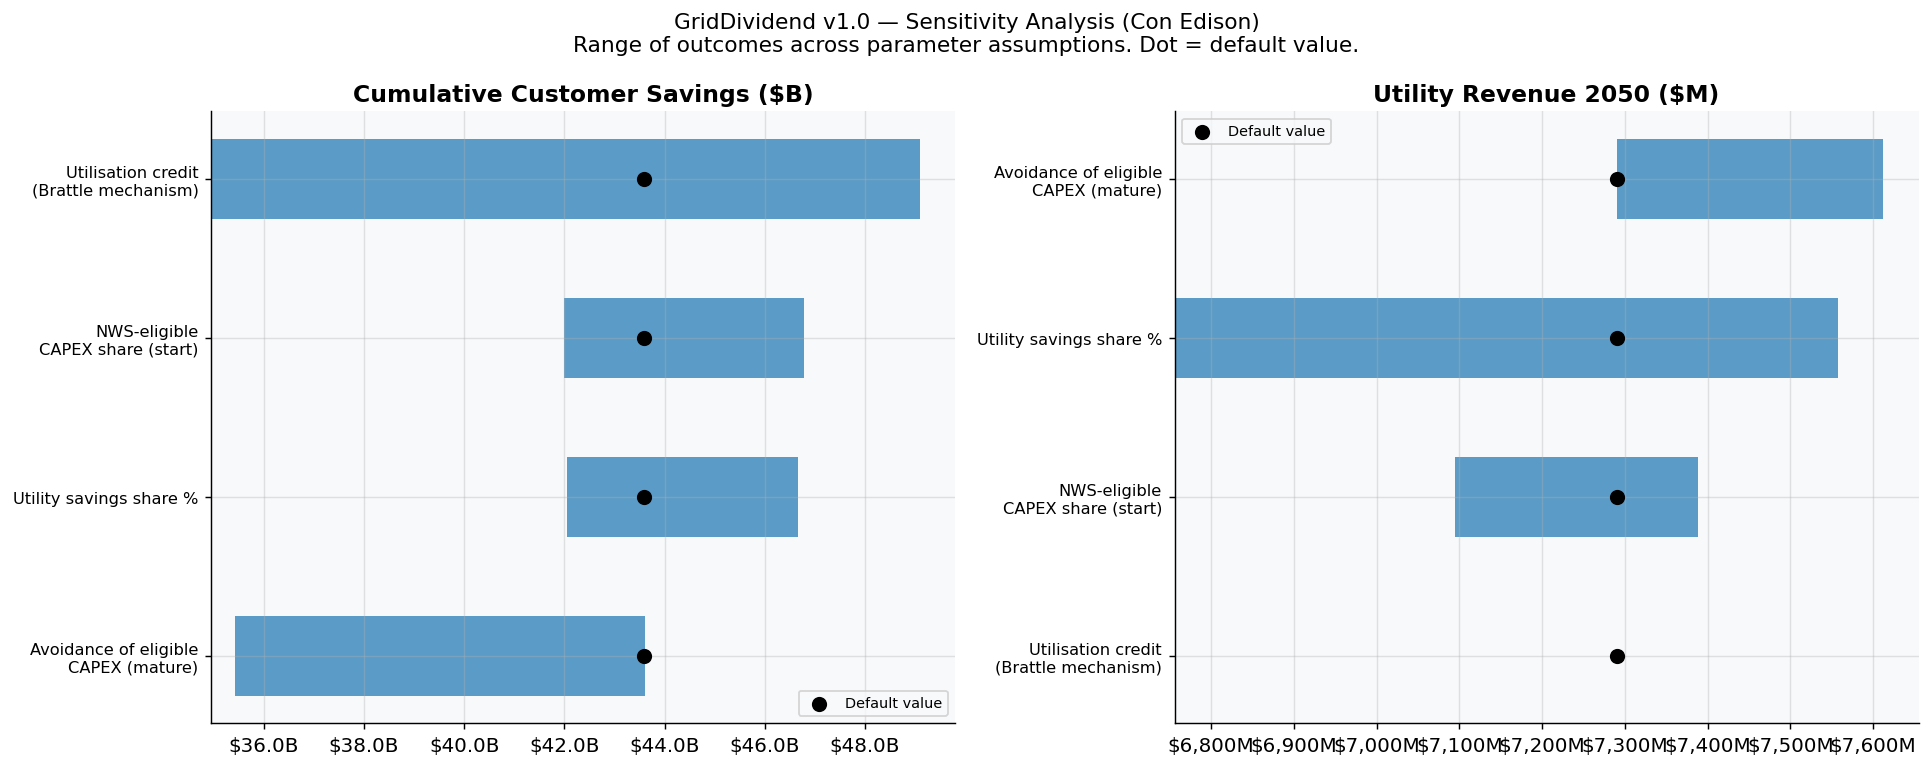

In [12]:
PARAM_DEFAULTS = {
    'NWS_ELIGIBLE_CAPEX_SHARE_START':   0.30,
    'NWS_AVOIDANCE_OF_ELIGIBLE_MATURE': 0.80,
    'UTILITY_SAVINGS_SHARE':            0.30,
    'FLEX_LOAD_UTILISATION_SHARE_SS':   0.15,
}
SENSITIVITY_RUNS = {
    'NWS_ELIGIBLE_CAPEX_SHARE_START':   [0.20, 0.25, 0.30, 0.40, 0.50],
    'NWS_AVOIDANCE_OF_ELIGIBLE_MATURE': [0.50, 0.65, 0.80, 0.90],
    'UTILITY_SAVINGS_SHARE':            [0.10, 0.20, 0.30, 0.40],
    'FLEX_LOAD_UTILISATION_SHARE_SS':   [0.00, 0.08, 0.15, 0.25],
}
PARAM_LABELS = {
    'NWS_ELIGIBLE_CAPEX_SHARE_START':   'NWS-eligible\nCAPEX share (start)',
    'NWS_AVOIDANCE_OF_ELIGIBLE_MATURE': 'Avoidance of eligible\nCAPEX (mature)',
    'UTILITY_SAVINGS_SHARE':            'Utility savings share %',
    'FLEX_LOAD_UTILISATION_SHARE_SS':   'Utilisation credit\n(Brattle mechanism)',
}

k = utilities_to_run[0]
p = utility_data[k]; bau_df = results[k]['bau']
all_sens = []
for pname, pvals in SENSITIVITY_RUNS.items():
    recs = []
    for val in pvals:
        cfg = {**MODEL_CONFIG, pname: val}
        s = project(p, 'shared', config=cfg)
        cum_b = np.sum((bau_df['avg_annual_bill'].values - s['avg_annual_bill'].values)
                       * s['customers'].values) / 1e9
        ur = s[s['year'] == 2050]['total_utility_revenue_m'].values[0]
        recs.append({'parameter': pname, 'value': val, 'cum_b': round(cum_b, 2), 'ur': round(ur, 0)})
    all_sens.append(pd.DataFrame(recs))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle(
    f'GridDividend v1.0 — Sensitivity Analysis ({UTILITIES[k]["short_name"]})\n'
    f'Range of outcomes across parameter assumptions. Dot = default value.',
    fontsize=12)

for ci, (metric, title) in enumerate([
    ('cum_b', 'Cumulative Customer Savings ($B)'),
    ('ur',    'Utility Revenue 2050 ($M)')]):
    ax = axes[ci]; ranges = []
    for s in all_sens:
        pname   = s['parameter'].iloc[0]
        default = PARAM_DEFAULTS[pname]
        lo = s[metric].min(); hi = s[metric].max()
        dr = s[abs(s['value'] - default) < 1e-9]
        mid = dr[metric].values[0] if len(dr) else (lo + hi) / 2
        ranges.append({'label': PARAM_LABELS[pname], 'lo': lo, 'hi': hi, 'mid': mid})
    rdf = pd.DataFrame(ranges).sort_values('hi', ascending=True)
    yp  = list(range(len(rdf)))
    ax.barh(yp, rdf['hi'] - rdf['lo'], left=rdf['lo'],
            color=C['util_shared'], alpha=0.72, height=0.5)
    ax.scatter(rdf['mid'], yp, color='black', zorder=5, s=55, label='Default')
    ax.set_yticks(yp); ax.set_yticklabels(rdf['label'], fontsize=9)
    ax.set_title(title)
    if metric == 'cum_b':
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.1f}B'))
    else:
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(['Default value'], fontsize=8)

plt.tight_layout()
plt.savefig('charts/chart4_sensitivity.png', bbox_inches='tight', dpi=130)
plt.show()

## Section 8b: ROE Sweep

Tests how lower allowed returns on equity interact with the shared-savings mechanism. For each utility, ROE runs from the rate-case value down to 7.0% in 0.5-point steps. Values below the rate case are an **illustrative market-return range**, not an auction-clearing rate. At each ROE the model runs BAU and the EASE Case (BASE scenario, with capacity pass-through applied as in Section 4). It sweeps `UTILITY_SAVINGS_SHARE` over 10–30% under both `SAVINGS_POOL_BASIS` values.

- **(a)** 2×2 quadrant: rate-case ROE vs 7.0% × BAU vs EASE Case, showing cumulative saving per customer against the status quo (rate-case ROE, BAU).
- **(b)** Cumulative saving per customer vs ROE.
- **(c)** Minimum incentive-compatible utility share vs ROE (cumulative utility earnings ≥ BAU over 10 and 25 years).
- **(d)** Year utility earnings fall permanently below BAU vs ROE.

Utility earnings = equity return on rate base + shared-savings income. Every dollar figure is labelled as undiscounted nominal or NPV (base year 2026). Charts are saved to `charts_article/roe_sweep_*_{utility keys}.png`.

**CORRECTED preset (continuation cell).** Section 8b's second cell reruns the sweep under the `CORRECTED` preset: depreciation in delivery RR, the `'revenue_requirement'` pool, negative pools carried forward, and bills indexed to BAU 2026. It runs once per `NWS_COST_TREATMENT` (`'expense'`, `'capitalise'`), with the utility share running 0–50%. It also prints the 2026 delivery revenue requirement reconciliation. `CORRECTED` is not the model default. Parts (a)–(d) above use `MODEL_CONFIG` as set in Section 1.

⚠ RG&E: results are PROVISIONAL — Case 25-E-0379 (temporary rates Jun 2026; final order pending).

ROE sweep: 6,500 rows (utility × ROE × share × pool basis × scenario × year).
ROE values below the rate-case figure are an illustrative market-return range.

Con Edison — Pool basis: 'capex' (v1.0) — share 30%
  Cumulative bill saving per customer vs status quo (rate-case ROE, BAU), 2026–2050, undiscounted nominal $:


,BAU,EASE Case
Rate-case ROE 9.4%,$0,"$12,423"
Illustrative 7.0%,"$6,259","$17,584"


Con Edison — Pool basis: 'capex' (v1.0) — share 30%
  Cumulative bill saving per customer vs status quo (rate-case ROE, BAU), 2026–2050, NPV at 3% (2026 $):


,BAU,EASE Case
Rate-case ROE 9.4%,$0,"$7,444"
Illustrative 7.0%,"$4,180","$10,968"


Con Edison — Pool basis: 'revenue_requirement' — share 30%
  Cumulative bill saving per customer vs status quo (rate-case ROE, BAU), 2026–2050, undiscounted nominal $:


,BAU,EASE Case
Rate-case ROE 9.4%,$0,"$8,182"
Illustrative 7.0%,"$6,259","$13,588"


... (8 outputs left out)

RG&E — Pool basis: 'revenue_requirement' — share 30%
  Cumulative bill saving per customer vs status quo (rate-case ROE, BAU), 2026–2050, NPV at 3% (2026 $):


,BAU,EASE Case
Rate-case ROE 10.0%,$0,"$3,071"
Illustrative 7.0%,"$2,372","$5,103"


Headline metrics at UTILITY_SAVINGS_SHARE = 30%:


,utility,pool_basis,roe,EASE bill 2030 ($/mo nominal),EASE bill 2040 ($/mo nominal),EASE bill 2050 ($/mo nominal),Cum saving/cust vs BAU (undiscounted nominal $),"Cum saving/cust vs BAU (NPV 3%, 2026 $)","Cum saving/cust vs BAU (NPV 7%, 2026 $)",crossover_year,Yrs 1-3 net utility gain per $ deferred (nominal),Shared income / total earnings (25-yr),min_share_10y,min_share_25y
4,ConEd,capex,0.094,195.605,261.692,316.658,12422.996,7443.613,3997.726,2042.0,0.192,0.148,0.179,0.299
9,ConEd,revenue_requirement,0.094,198.018,277.488,351.100,8182.012,4877.416,2600.382,2026.0,-0.060,0.108,0.523,0.430
14,ConEd,capex,0.090,193.463,258.576,312.853,12239.949,7334.350,3939.396,2043.0,0.196,0.153,0.172,0.286
19,ConEd,revenue_requirement,0.090,195.857,274.229,346.930,8039.818,4792.525,2555.055,2026.0,-0.057,0.110,0.512,0.419
24,ConEd,capex,0.085,190.786,254.681,308.097,12011.174,7197.793,3866.498,2045.0,0.200,0.161,0.162,0.271
29,ConEd,revenue_requirement,0.085,193.155,270.155,341.718,7862.061,4686.401,2498.389,2026.0,-0.054,0.113,0.497,0.406
34,ConEd,capex,0.080,188.108,250.786,303.340,11782.440,7061.262,3793.615,2049.0,0.204,0.169,0.153,0.255
39,ConEd,revenue_requirement,0.080,190.454,266.082,336.506,7684.286,4580.266,2441.717,2026.0,-0.051,0.117,0.482,0.391
44,ConEd,capex,0.075,185.431,246.890,298.583,11553.749,6924.758,3720.750,NaN,0.209,0.179,0.143,0.239
49,ConEd,revenue_requirement,0.075,187.753,262.008,331.294,7506.492,4474.118,2385.036,2026.0,-0.048,0.121,0.466,0.376


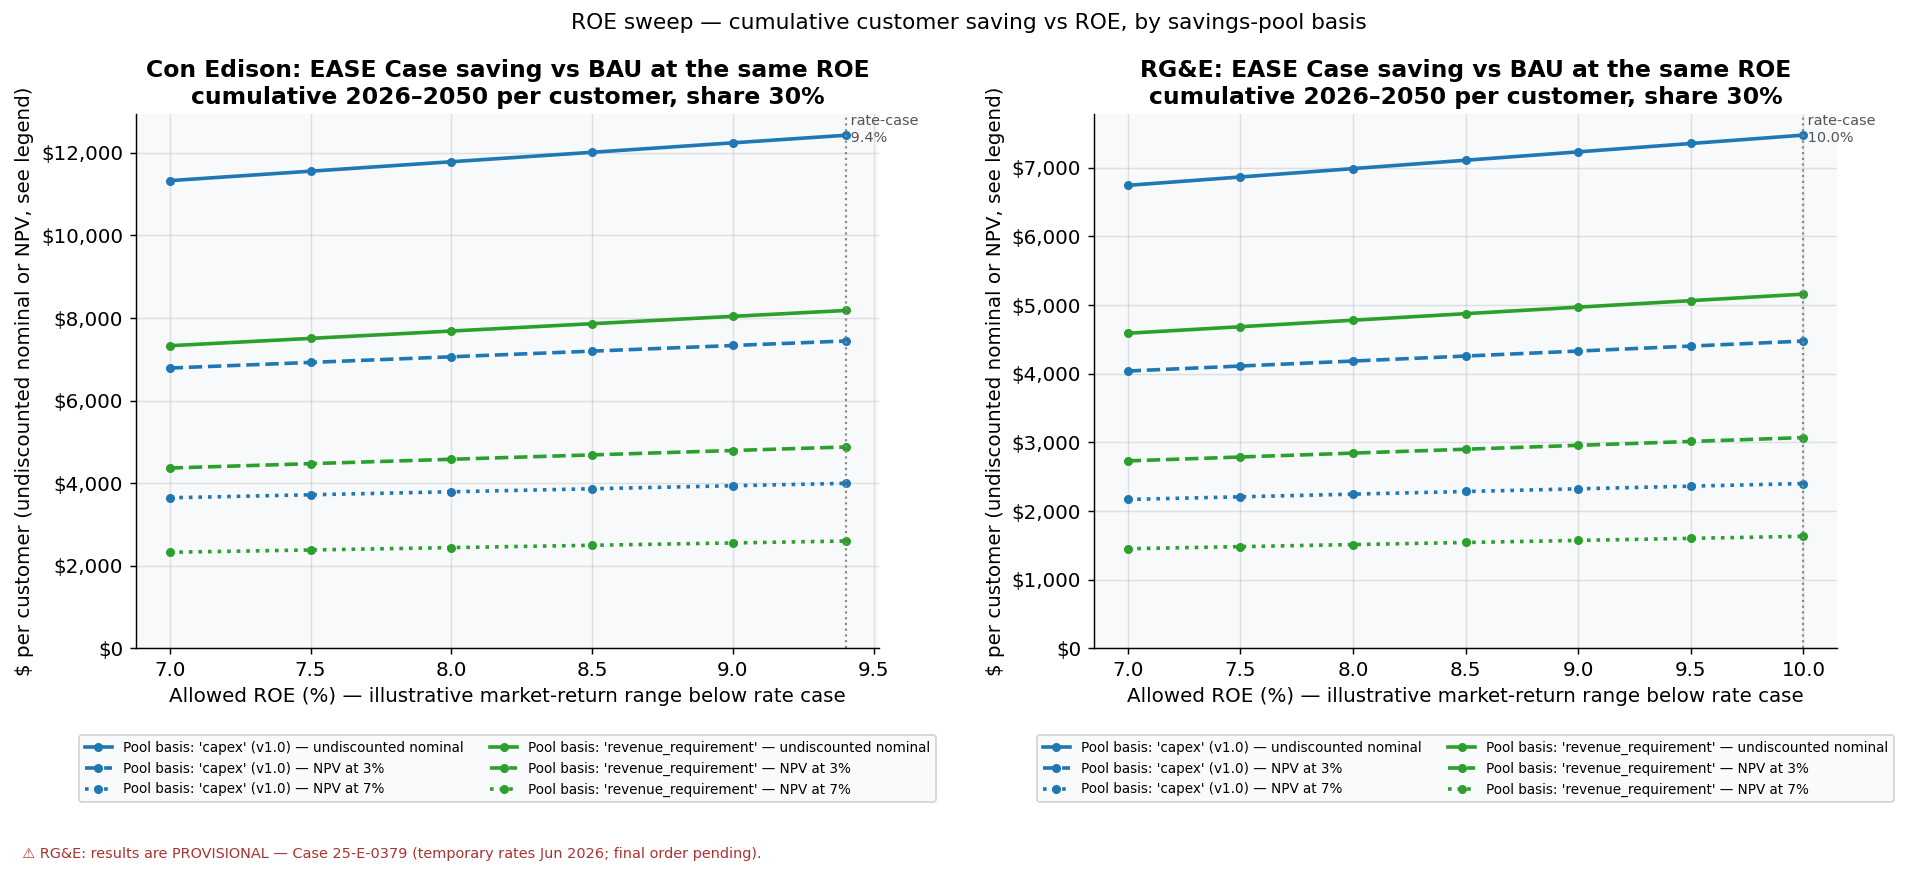

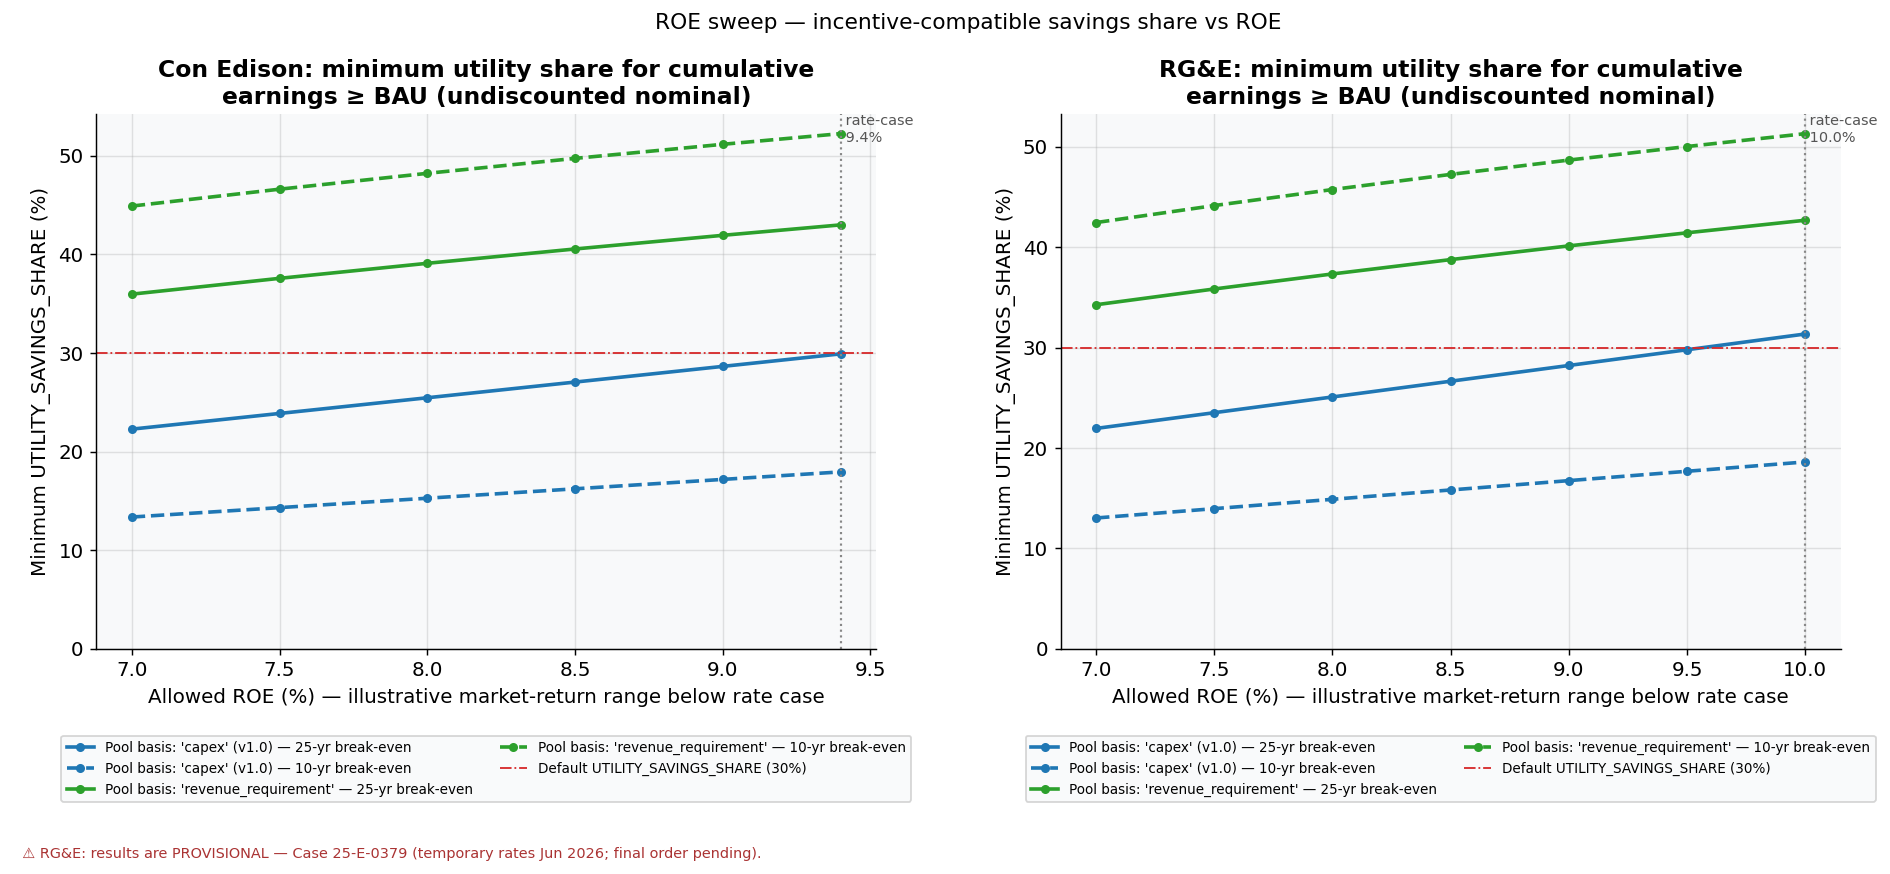

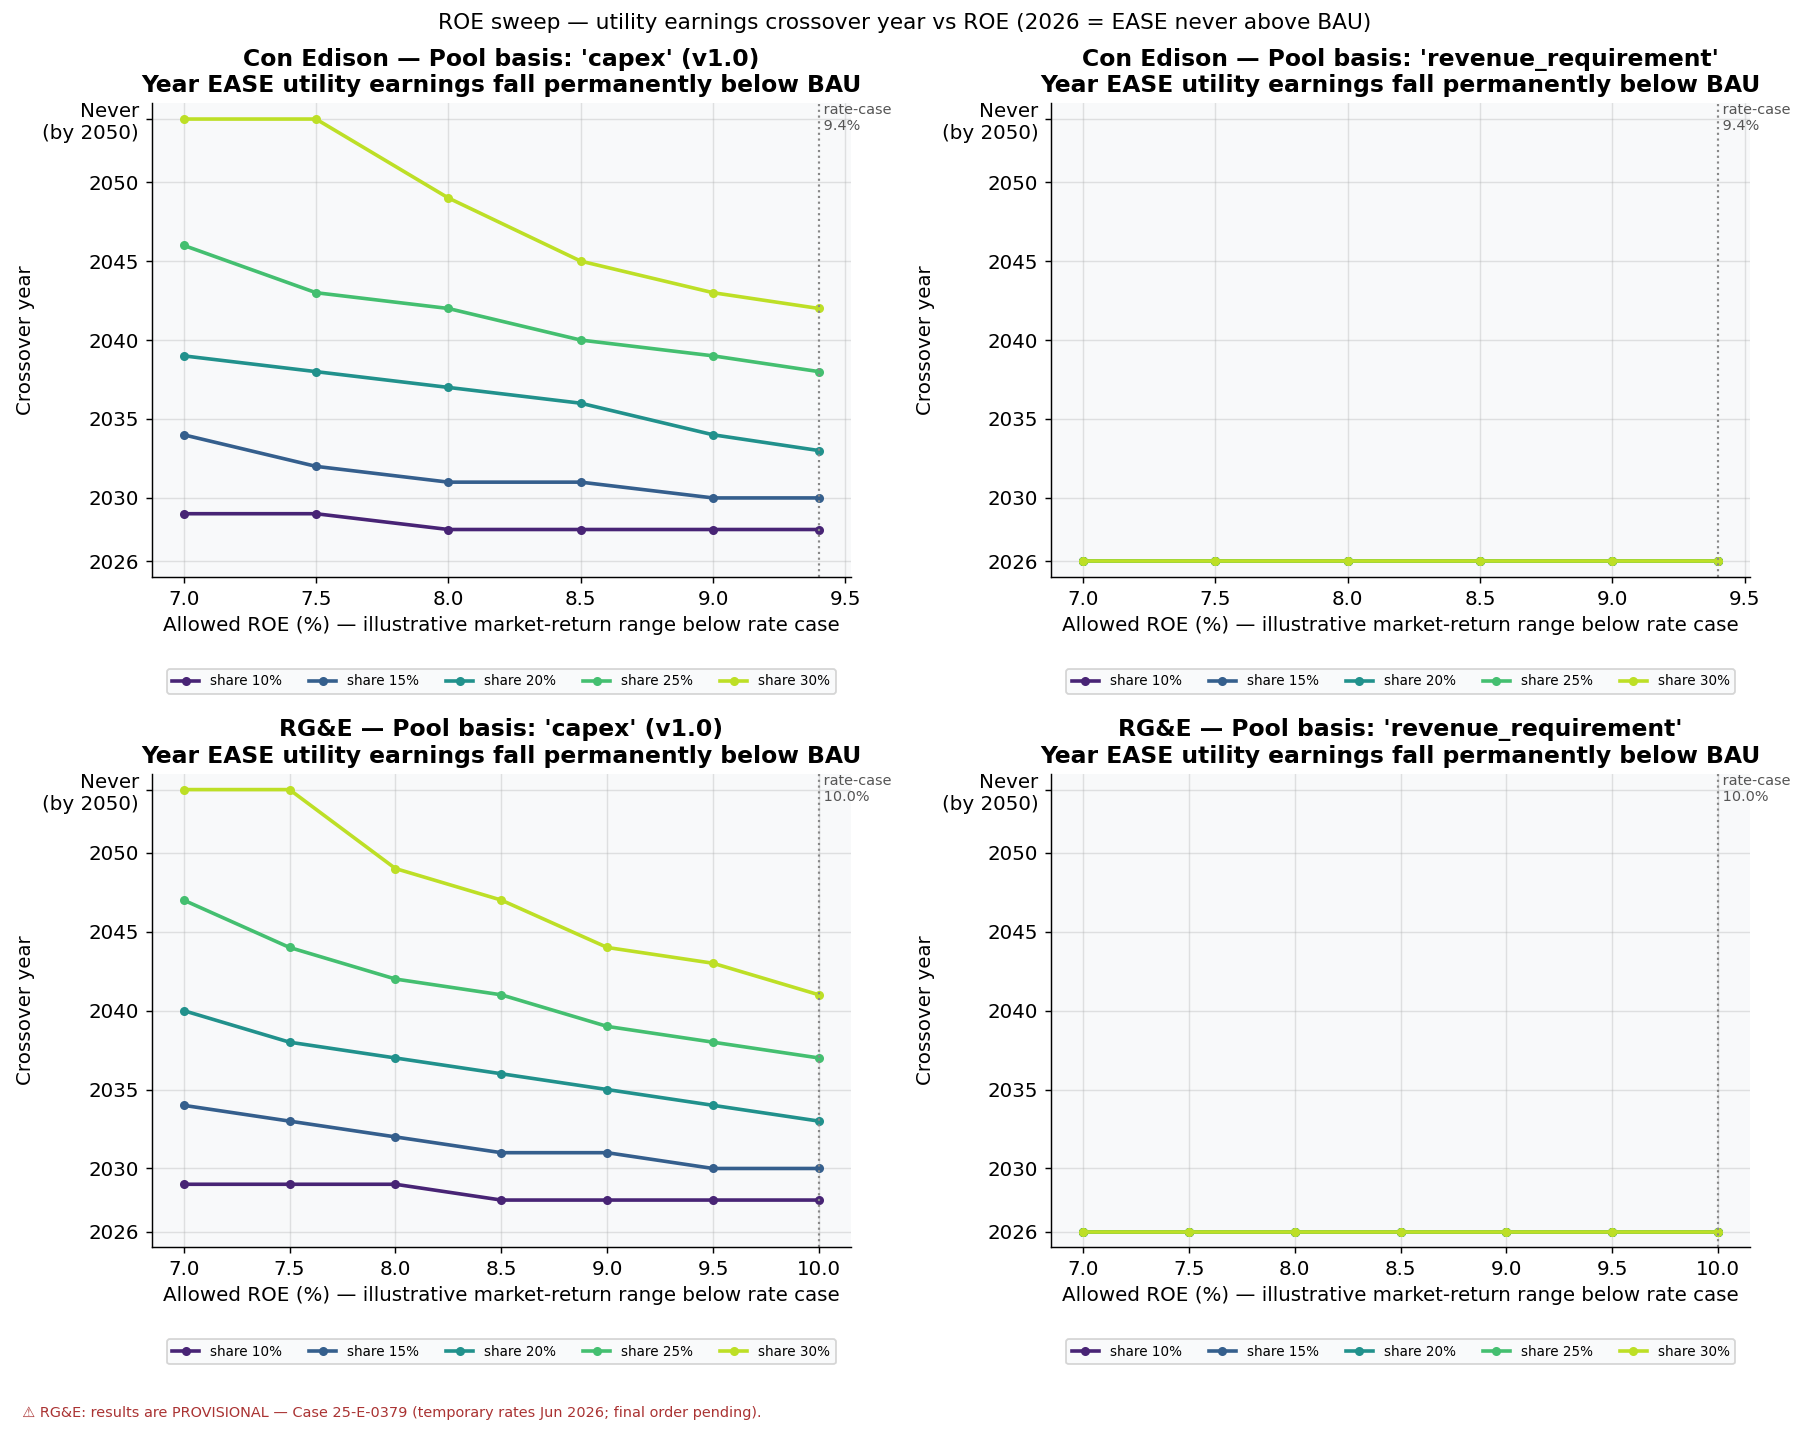

In [13]:
# ============================================================
# SECTION 8b: ROE SWEEP
# How lower allowed returns interact with the shared-savings mechanism.
# Engine: engine/roe_sweep.py. ROE values below the rate-case figure form an
# ILLUSTRATIVE MARKET-RETURN RANGE — none is an auction-clearing rate.
# Utility earnings = equity return (rate base × equity ratio × ROE)
#                    + shared-savings income.
# ============================================================
from engine.roe_sweep import (run_roe_sweep, compute_roe_metrics, quadrant_table,
                              data_quality_flags)
os.makedirs('charts_article', exist_ok=True)

ROE_SWEEP_FLOOR  = 0.070                           # bottom of illustrative range
ROE_SWEEP_STEP   = 0.005
ROE_SWEEP_SHARES = (0.10, 0.15, 0.20, 0.25, 0.30)  # UTILITY_SAVINGS_SHARE values
DEFAULT_SHARE    = MODEL_CONFIG['UTILITY_SAVINGS_SHARE']
BASIS_LABEL  = {'capex': "Pool basis: 'capex' (v1.0)",
                'revenue_requirement': "Pool basis: 'revenue_requirement'"}
BASIS_COLOUR = {'capex': C['util_shared'], 'revenue_requirement': C['shared']}

roe_sweep_df = run_roe_sweep(utility_data, MODEL_CONFIG, utilities_to_run,
                             scenario_def=SCENARIO_DEFS['BASE'],
                             shares=ROE_SWEEP_SHARES, roe_floor=ROE_SWEEP_FLOOR,
                             roe_step=ROE_SWEEP_STEP)
roe_metrics = compute_roe_metrics(roe_sweep_df)
flags = data_quality_flags(UTILITIES, utilities_to_run)
flag_note = ('  ⚠ ' + '  ⚠ '.join(flags)) if flags else ''
for f in flags:
    print('⚠', f)
print(f"\nROE sweep: {len(roe_sweep_df):,} rows "
      "(utility × ROE × share × pool basis × scenario × year).")
print("ROE values below the rate-case figure are an illustrative market-return range.\n")

# ── (a) 2×2 quadrant: rate-case ROE vs 7.0%, BAU vs EASE Case ─────────────────
for k in utilities_to_run:
    name = UTILITIES[k]['short_name']
    for basis in ['capex', 'revenue_requirement']:
        for col, lbl in [('nominal', 'undiscounted nominal $'), ('npv3', 'NPV at 3% (2026 $)')]:
            print(f"{name} — {BASIS_LABEL[basis]} — share {DEFAULT_SHARE:.0%}\n"
                  f"  Cumulative bill saving per customer vs status quo "
                  f"(rate-case ROE, BAU), 2026–2050, {lbl}:")
            q = quadrant_table(roe_metrics, k, basis, share=DEFAULT_SHARE,
                               roe_low=ROE_SWEEP_FLOOR, column=col)
            display(q.round(0).astype(int).apply(lambda s: s.map(lambda v: f'${v:,}')))

# ── Headline metrics at the default share ─────────────────────────────────────
show = roe_metrics[np.isclose(roe_metrics['share'], DEFAULT_SHARE)][[
    'utility', 'pool_basis', 'roe', 'ease_bill_2030', 'ease_bill_2040', 'ease_bill_2050',
    'cum_saving_nominal', 'cum_saving_npv3', 'cum_saving_npv7', 'crossover_year',
    'early_net_per_deferred_$', 'ss_income_share_of_earnings',
    'min_share_10y', 'min_share_25y']].rename(columns={
        'ease_bill_2030': 'EASE bill 2030 ($/mo nominal)',
        'ease_bill_2040': 'EASE bill 2040 ($/mo nominal)',
        'ease_bill_2050': 'EASE bill 2050 ($/mo nominal)',
        'cum_saving_nominal': 'Cum saving/cust vs BAU (undiscounted nominal $)',
        'cum_saving_npv3': 'Cum saving/cust vs BAU (NPV 3%, 2026 $)',
        'cum_saving_npv7': 'Cum saving/cust vs BAU (NPV 7%, 2026 $)',
        'early_net_per_deferred_$': 'Yrs 1-3 net utility gain per $ deferred (nominal)',
        'ss_income_share_of_earnings': 'Shared income / total earnings (25-yr)'})
print(f"Headline metrics at UTILITY_SAVINGS_SHARE = {DEFAULT_SHARE:.0%}:")
display(show.round(3))

def _fmt_roe_axis(ax, k):
    rc = utility_data[k]['roe']
    ax.axvline(rc * 100, color=C['neutral'], ls=':', lw=1.2)
    ax.text(rc * 100, ax.get_ylim()[1], f' rate-case\n {rc:.1%}', fontsize=8,
            color='#555', va='top')
    ax.set_xlabel('Allowed ROE (%) — illustrative market-return range below rate case')

def _save(fig, fname):
    fig.text(0.01, -0.02, flag_note, fontsize=8, color='#a33', ha='left', wrap=True)
    plt.tight_layout()
    plt.savefig(f'charts_article/{fname}_{UTIL_TAG}.png', bbox_inches='tight', dpi=300)
    plt.show()

n = len(utilities_to_run)
UTIL_TAG = '_'.join(k.lower() for k in utilities_to_run)   # e.g. coned_rge
d = roe_metrics[np.isclose(roe_metrics['share'], DEFAULT_SHARE)]

# ── (b) Cumulative saving per customer vs ROE ─────────────────────────────────
fig, axes = plt.subplots(1, n, figsize=(7.5 * n, 6.5), squeeze=False)
for ax, k in zip(axes[0], utilities_to_run):
    for basis in ['capex', 'revenue_requirement']:
        s = d[(d['utility'] == k) & (d['pool_basis'] == basis)].sort_values('roe')
        for col, ls, lbl in [('cum_saving_nominal', '-', 'undiscounted nominal'),
                             ('cum_saving_npv3', '--', 'NPV at 3%'),
                             ('cum_saving_npv7', ':', 'NPV at 7%')]:
            ax.plot(s['roe'] * 100, s[col], color=BASIS_COLOUR[basis], ls=ls, lw=2,
                    marker='o', ms=4, label=f"{BASIS_LABEL[basis]} — {lbl}")
    ax.set_title(f"{UTILITIES[k]['short_name']}: EASE Case saving vs BAU at the same ROE\n"
                 f"cumulative 2026–2050 per customer, share {DEFAULT_SHARE:.0%}")
    ax.set_ylabel('$ per customer (undiscounted nominal or NPV, see legend)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
    ax.set_ylim(bottom=0)
    _fmt_roe_axis(ax, k)
    ax.legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.suptitle('ROE sweep — cumulative customer saving vs ROE, by savings-pool basis', fontsize=12)
_save(fig, 'roe_sweep_cumulative_savings')

# ── (c) Minimum incentive-compatible share vs ROE ─────────────────────────────
fig, axes = plt.subplots(1, n, figsize=(7.5 * n, 6.5), squeeze=False)
for ax, k in zip(axes[0], utilities_to_run):
    for basis in ['capex', 'revenue_requirement']:
        s = d[(d['utility'] == k) & (d['pool_basis'] == basis)].sort_values('roe')
        for col, ls, lbl in [('min_share_25y', '-', '25-yr'), ('min_share_10y', '--', '10-yr')]:
            ax.plot(s['roe'] * 100, s[col] * 100, color=BASIS_COLOUR[basis], ls=ls, lw=2,
                    marker='o', ms=4, label=f"{BASIS_LABEL[basis]} — {lbl} break-even")
    ax.axhline(DEFAULT_SHARE * 100, color=C['bau'], lw=1, ls='-.',
               label=f'Default UTILITY_SAVINGS_SHARE ({DEFAULT_SHARE:.0%})')
    ax.set_title(f"{UTILITIES[k]['short_name']}: minimum utility share for cumulative\n"
                 "earnings ≥ BAU (undiscounted nominal)")
    ax.set_ylabel('Minimum UTILITY_SAVINGS_SHARE (%)')
    ax.set_ylim(bottom=0)
    _fmt_roe_axis(ax, k)
    ax.legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.suptitle('ROE sweep — incentive-compatible savings share vs ROE', fontsize=12)
_save(fig, 'roe_sweep_min_share')

# ── (d) Earnings crossover year vs ROE ────────────────────────────────────────
NEVER = YEARS[-1] + 4
fig, axes = plt.subplots(n, 2, figsize=(14, 5.4 * n), squeeze=False)
share_cmap = plt.cm.viridis(np.linspace(0.1, 0.9, len(ROE_SWEEP_SHARES)))
for r, k in enumerate(utilities_to_run):
    for c_, basis in enumerate(['capex', 'revenue_requirement']):
        ax = axes[r, c_]
        for sh_, col in zip(ROE_SWEEP_SHARES, share_cmap):
            s = roe_metrics[(roe_metrics['utility'] == k) & (roe_metrics['pool_basis'] == basis)
                            & np.isclose(roe_metrics['share'], sh_)].sort_values('roe')
            ax.plot(s['roe'] * 100, s['crossover_year'].fillna(NEVER), color=col, lw=2,
                    marker='o', ms=4, label=f'share {sh_:.0%}')
        ax.set_ylim(YEARS[0] - 1, NEVER + 1)
        ticks = [YEARS[0]] + list(range(2030, YEARS[-1] + 1, 5))
        ax.set_yticks(ticks + [NEVER])
        ax.set_yticklabels([f'{int(y)}' for y in ticks] + ['Never\n(by 2050)'])
        ax.set_title(f"{UTILITIES[k]['short_name']} — {BASIS_LABEL[basis]}\n"
                     "Year EASE utility earnings fall permanently below BAU")
        ax.set_ylabel('Crossover year')
        _fmt_roe_axis(ax, k)
        ax.legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=5)
fig.suptitle('ROE sweep — utility earnings crossover year vs ROE '
             f'({YEARS[0]} = EASE never above BAU)', fontsize=12)
_save(fig, 'roe_sweep_crossover_year')

CORRECTED preset flags: {'INCLUDE_DEPRECIATION_EXPENSE': True, 'SAVINGS_POOL_BASIS': 'revenue_requirement', 'NEGATIVE_POOL_TREATMENT': 'carry_forward', 'BILL_INDEX_BASE': 'bau', 'NWS_COST_TREATMENT': 'expense', 'ROE_OVERRIDE_REBASE_BILL': True, 'CAPACITY_SAVINGS_ALLOCATION': 'sales_share', 'CAPACITY_COST_GROWTH': 'INFLATION_RATE'}

2026 delivery revenue requirement reconciliation (BAU, rate-case ROE, nominal $M):
  ⚠ Con Edison: recalibrated other O&M is only 14% of delivery RR (< 15%) — implausibly low
  ⚠ RG&E: recalibrated other O&M is 64% of delivery RR (> 50%) — implausibly high; rate base may be understated relative to rate-case revenue


,Rate-case delivery RR,Return (WACC × RB),Property tax,Depreciation (3.5% × RB),Other O&M (recalibrated),Other O&M % of delivery RR,v1.0 model delivery RR,v1.0 other O&M
Utility,,,,,,,,
Con Edison,5040.0,2586.0,582.0,1153.0,719.0,14%,4405.0,1237.0
RG&E,614.0,132.0,32.0,56.0,394.0,64%,350.0,186.0



CORRECTED sweep: 14,300 rows. Variants: ['CORRECTED/expense', 'CORRECTED/capitalise']

Cumulative bill saving per residential customer, EASE Case vs BAU at the same ROE, 2026–2050, share 30%:


$ per residential customer, undiscounted nominal  \
Utility    variant              ROE                                                       
Con Edison CORRECTED/expense    9.4%                                             7983.0   
                                7.0%                                             7214.0   
RG&E       CORRECTED/expense    10.0%                                            3944.0   
                                7.0%                                             3612.0   
Con Edison CORRECTED/capitalise 9.4%                                             8060.0   
                                7.0%                                             7337.0   
RG&E       CORRECTED/capitalise 10.0%                                            3966.0   
                                7.0%                                             3654.0   

                                       $ per residential customer, NPV at 3% (2026 $)  \
Utility    variant              ROE                                                     
Con Edison CORRECTED/expense    9.4%                                           4740.0   
                                7.0%                                           4279.0   
RG&E       CORRECTED/expense    10.0%                                          2347.0   
                                7.0%                                           2148.0   
Con Edison CORRECTED/capitalise 9.4%                                           4811.0   
                                7.0%                                           4379.0   
RG&E       CORRECTED/capitalise 10.0%                                          2369.0   
                                7.0%                                           2183.0   

                                       $ per residential customer, NPV at 7% (2026 $)  
Utility    variant              ROE                                                    
Con Edison CORRECTED/expense    9.4%                                           2509.0  
                                7.0%                                           2261.0  
RG&E       CORRECTED/expense    10.0%                                          1248.0  
                                7.0%                                           1141.0  
Con Edison CORRECTED/capitalise 9.4%                                           2571.0  
                                7.0%                                           2340.0  
RG&E       CORRECTED/capitalise 10.0%                                          1267.0  
                                7.0%                                           1168.0

Break-even UTILITY_SAVINGS_SHARE: cumulative equity-only earnings ≥ BAU (undiscounted nominal). Independent of the share swept.


10-yr break-even share  \
Utility    variant              ROE                            
Con Edison CORRECTED/expense    9.4%                   40.2%   
                                7.0%                   33.3%   
RG&E       CORRECTED/expense    10.0%                  40.2%   
                                7.0%                   32.0%   
Con Edison CORRECTED/capitalise 9.4%                   30.7%   
                                7.0%                   24.8%   
RG&E       CORRECTED/capitalise 10.0%                  30.9%   
                                7.0%                   23.8%   

                                      25-yr break-even share  
Utility    variant              ROE                           
Con Edison CORRECTED/expense    9.4%                   33.8%  
                                7.0%                   27.6%  
RG&E       CORRECTED/expense    10.0%                  34.1%  
                                7.0%                   26.6%  
Con Edison CORRECTED/capitalise 9.4%                   30.5%  
                                7.0%                   24.6%  
RG&E       CORRECTED/capitalise 10.0%                  30.8%  
                                7.0%                   23.8%

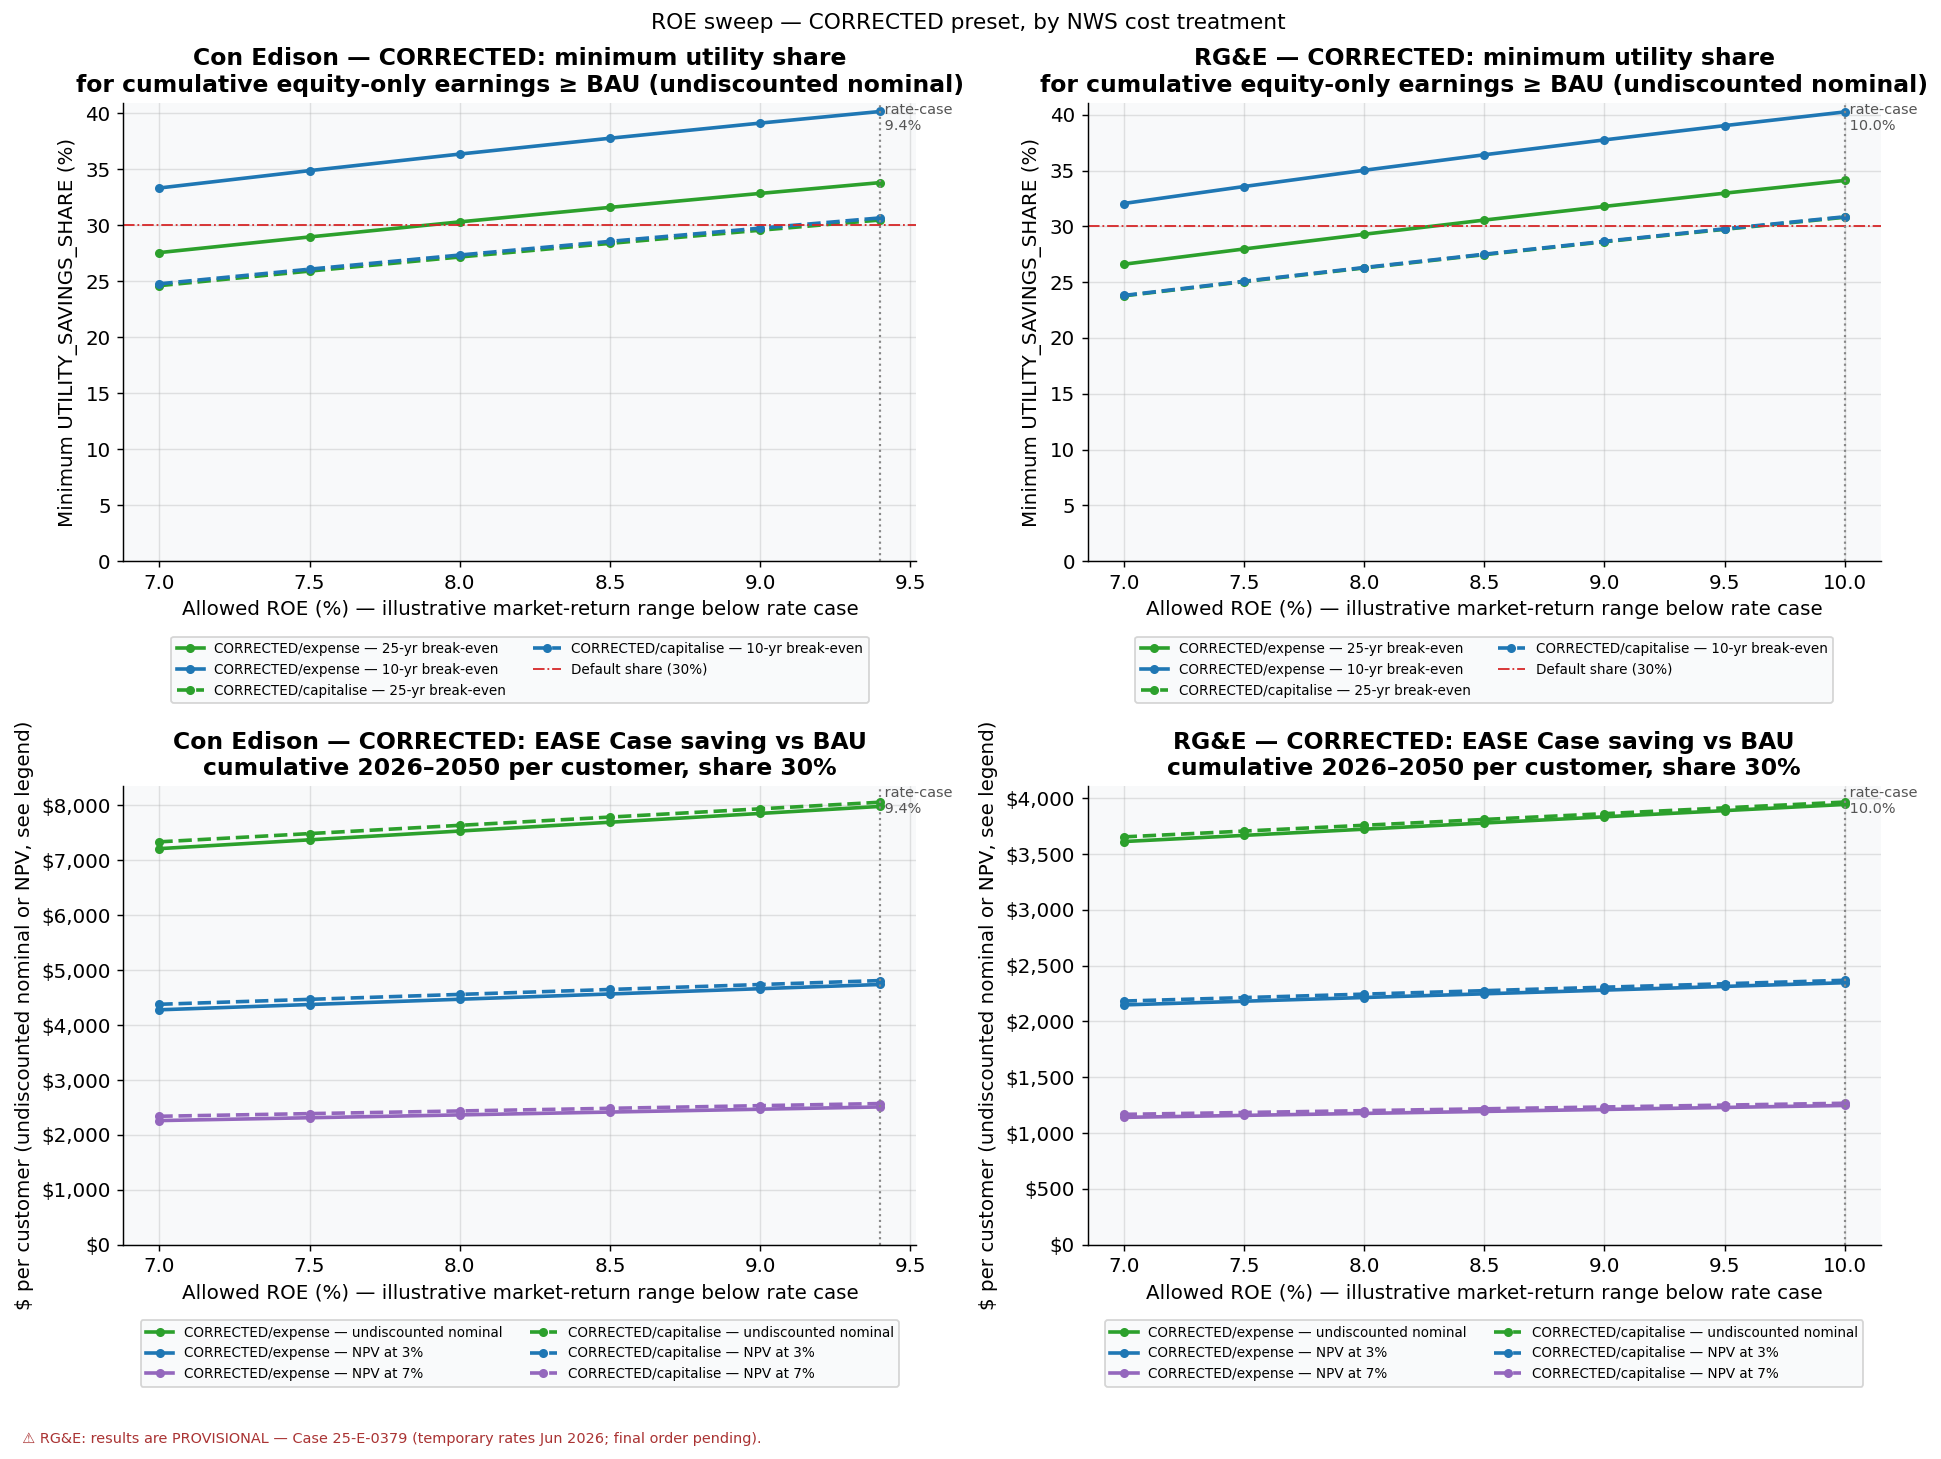

In [14]:
# ============================================================
# SECTION 8b (CONTINUED): CORRECTED PRESET SWEEP
# Runs the CORRECTED preset (engine/model.py PRESETS) — depreciation in
# delivery RR, 'revenue_requirement' pool, negative pools carried forward,
# bills indexed to BAU 2026 — for each NWS_COST_TREATMENT, ROE from the rate
# case to 7.0%, and UTILITY_SAVINGS_SHARE 0–50%. CORRECTED is NOT the model
# default; this cell leaves MODEL_CONFIG unchanged.
# Utility earnings here are equity-only (equity return + shared income).
# ============================================================
from engine import apply_preset, delivery_rr_reconciliation, PRESETS
from engine.roe_sweep import run_corrected_sweep

print('CORRECTED preset flags:', PRESETS['CORRECTED'])
print('\n2026 delivery revenue requirement reconciliation (BAU, rate-case ROE, nominal $M):')
recon = []
for k in utilities_to_run:
    r = delivery_rr_reconciliation(utility_data[k], MODEL_CONFIG)
    recon.append({'Utility': UTILITIES[k]['short_name'],
                  'Rate-case delivery RR': r['target_delivery_rr_m'],
                  'Return (WACC × RB)': r['return_m'],
                  'Property tax': r['property_tax_m'],
                  'Depreciation (3.5% × RB)': r['depreciation_m'],
                  'Other O&M (recalibrated)': r['other_om_recalibrated_m'],
                  'Other O&M % of delivery RR': f"{r['other_om_recalibrated_share']:.0%}",
                  'v1.0 model delivery RR': r['v10_delivery_rr_m'],
                  'v1.0 other O&M': r['other_om_v10_m']})
    for w in r['warnings']:
        print(f"  ⚠ {UTILITIES[k]['short_name']}: {w}")
display(pd.DataFrame(recon).set_index('Utility').round(0))

corr_df      = run_corrected_sweep(utility_data, MODEL_CONFIG, utilities_to_run,
                                   scenario_def=SCENARIO_DEFS['BASE'],
                                   roe_floor=ROE_SWEEP_FLOOR, roe_step=ROE_SWEEP_STEP)
corr_metrics = compute_roe_metrics(corr_df)
TREATMENTS   = list(dict.fromkeys(corr_metrics['variant']))
TREAT_STYLE  = {TREATMENTS[0]: '-', TREATMENTS[-1]: '--'}
print(f"\nCORRECTED sweep: {len(corr_df):,} rows. Variants: {TREATMENTS}")

# ── Cumulative saving per customer under CORRECTED (share = default) ──────────
at = corr_metrics[np.isclose(corr_metrics['share'], DEFAULT_SHARE)
                  & (np.isclose(corr_metrics['roe'], corr_metrics['rate_case_roe'])
                     | np.isclose(corr_metrics['roe'], ROE_SWEEP_FLOOR))].copy()
at['ROE'] = at['roe'].map(lambda r: f'{r:.1%}')
from engine import per_customer_label
_cust_lbl = per_customer_label(apply_preset(MODEL_CONFIG, 'CORRECTED'))   # 'per residential customer'
print(f"\nCumulative bill saving {_cust_lbl}, EASE Case vs BAU at the same ROE, 2026–2050, "
      f"share {DEFAULT_SHARE:.0%}:")
display(at.assign(Utility=at['utility'].map(lambda k: UTILITIES[k]['short_name']))
          .set_index(['Utility', 'variant', 'ROE'])[
              ['cum_saving_nominal', 'cum_saving_npv3', 'cum_saving_npv7']]
          .rename(columns={'cum_saving_nominal': f'$ {_cust_lbl}, undiscounted nominal',
                           'cum_saving_npv3': f'$ {_cust_lbl}, NPV at 3% (2026 $)',
                           'cum_saving_npv7': f'$ {_cust_lbl}, NPV at 7% (2026 $)'})
          .round(0))

# ── Break-even (minimum) utility share ────────────────────────────────────────
be = at.assign(Utility=at['utility'].map(lambda k: UTILITIES[k]['short_name']))
print("Break-even UTILITY_SAVINGS_SHARE: cumulative equity-only earnings ≥ BAU "
      "(undiscounted nominal). Independent of the share swept.")
display(be.set_index(['Utility', 'variant', 'ROE'])[['min_share_10y', 'min_share_25y']]
          .rename(columns={'min_share_10y': '10-yr break-even share',
                           'min_share_25y': '25-yr break-even share'})
          .apply(lambda col: col.map(lambda v: f'{v:.1%}' if np.isfinite(v) else 'none ≤ 100%')))

# ── Charts: CORRECTED min share and cumulative saving vs ROE ──────────────────
d_c = corr_metrics[np.isclose(corr_metrics['share'], DEFAULT_SHARE)]
fig, axes = plt.subplots(2, n, figsize=(7.5 * n, 11), squeeze=False)
for j, k in enumerate(utilities_to_run):
    ax = axes[0, j]
    for v in TREATMENTS:
        s = d_c[(d_c['utility'] == k) & (d_c['variant'] == v)].sort_values('roe')
        for col, colour, lbl in [('min_share_25y', C['shared'], '25-yr'),
                                 ('min_share_10y', C['util_shared'], '10-yr')]:
            ax.plot(s['roe'] * 100, s[col] * 100, color=colour, ls=TREAT_STYLE[v], lw=2,
                    marker='o', ms=4, label=f'{v} — {lbl} break-even')
    ax.axhline(DEFAULT_SHARE * 100, color=C['bau'], lw=1, ls='-.',
               label=f'Default share ({DEFAULT_SHARE:.0%})')
    ax.set_title(f"{UTILITIES[k]['short_name']} — CORRECTED: minimum utility share\n"
                 "for cumulative equity-only earnings ≥ BAU (undiscounted nominal)")
    ax.set_ylabel('Minimum UTILITY_SAVINGS_SHARE (%)'); ax.set_ylim(bottom=0)
    _fmt_roe_axis(ax, k)
    ax.legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)

    ax = axes[1, j]
    for v in TREATMENTS:
        s = d_c[(d_c['utility'] == k) & (d_c['variant'] == v)].sort_values('roe')
        for col, colour, lbl in [('cum_saving_nominal', C['shared'], 'undiscounted nominal'),
                                 ('cum_saving_npv3', C['util_shared'], 'NPV at 3%'),
                                 ('cum_saving_npv7', C['tax'], 'NPV at 7%')]:
            ax.plot(s['roe'] * 100, s[col], color=colour, ls=TREAT_STYLE[v], lw=2,
                    marker='o', ms=4, label=f'{v} — {lbl}')
    ax.set_title(f"{UTILITIES[k]['short_name']} — CORRECTED: EASE Case saving vs BAU\n"
                 f"cumulative 2026–2050 per customer, share {DEFAULT_SHARE:.0%}")
    ax.set_ylabel('$ per customer (undiscounted nominal or NPV, see legend)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
    ax.set_ylim(bottom=0)
    _fmt_roe_axis(ax, k)
    ax.legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.suptitle('ROE sweep — CORRECTED preset, by NWS cost treatment', fontsize=12)
_save(fig, 'roe_sweep_corrected')

## Section 9: Con Edison vs. RG&E — Side-by-Side Comparison

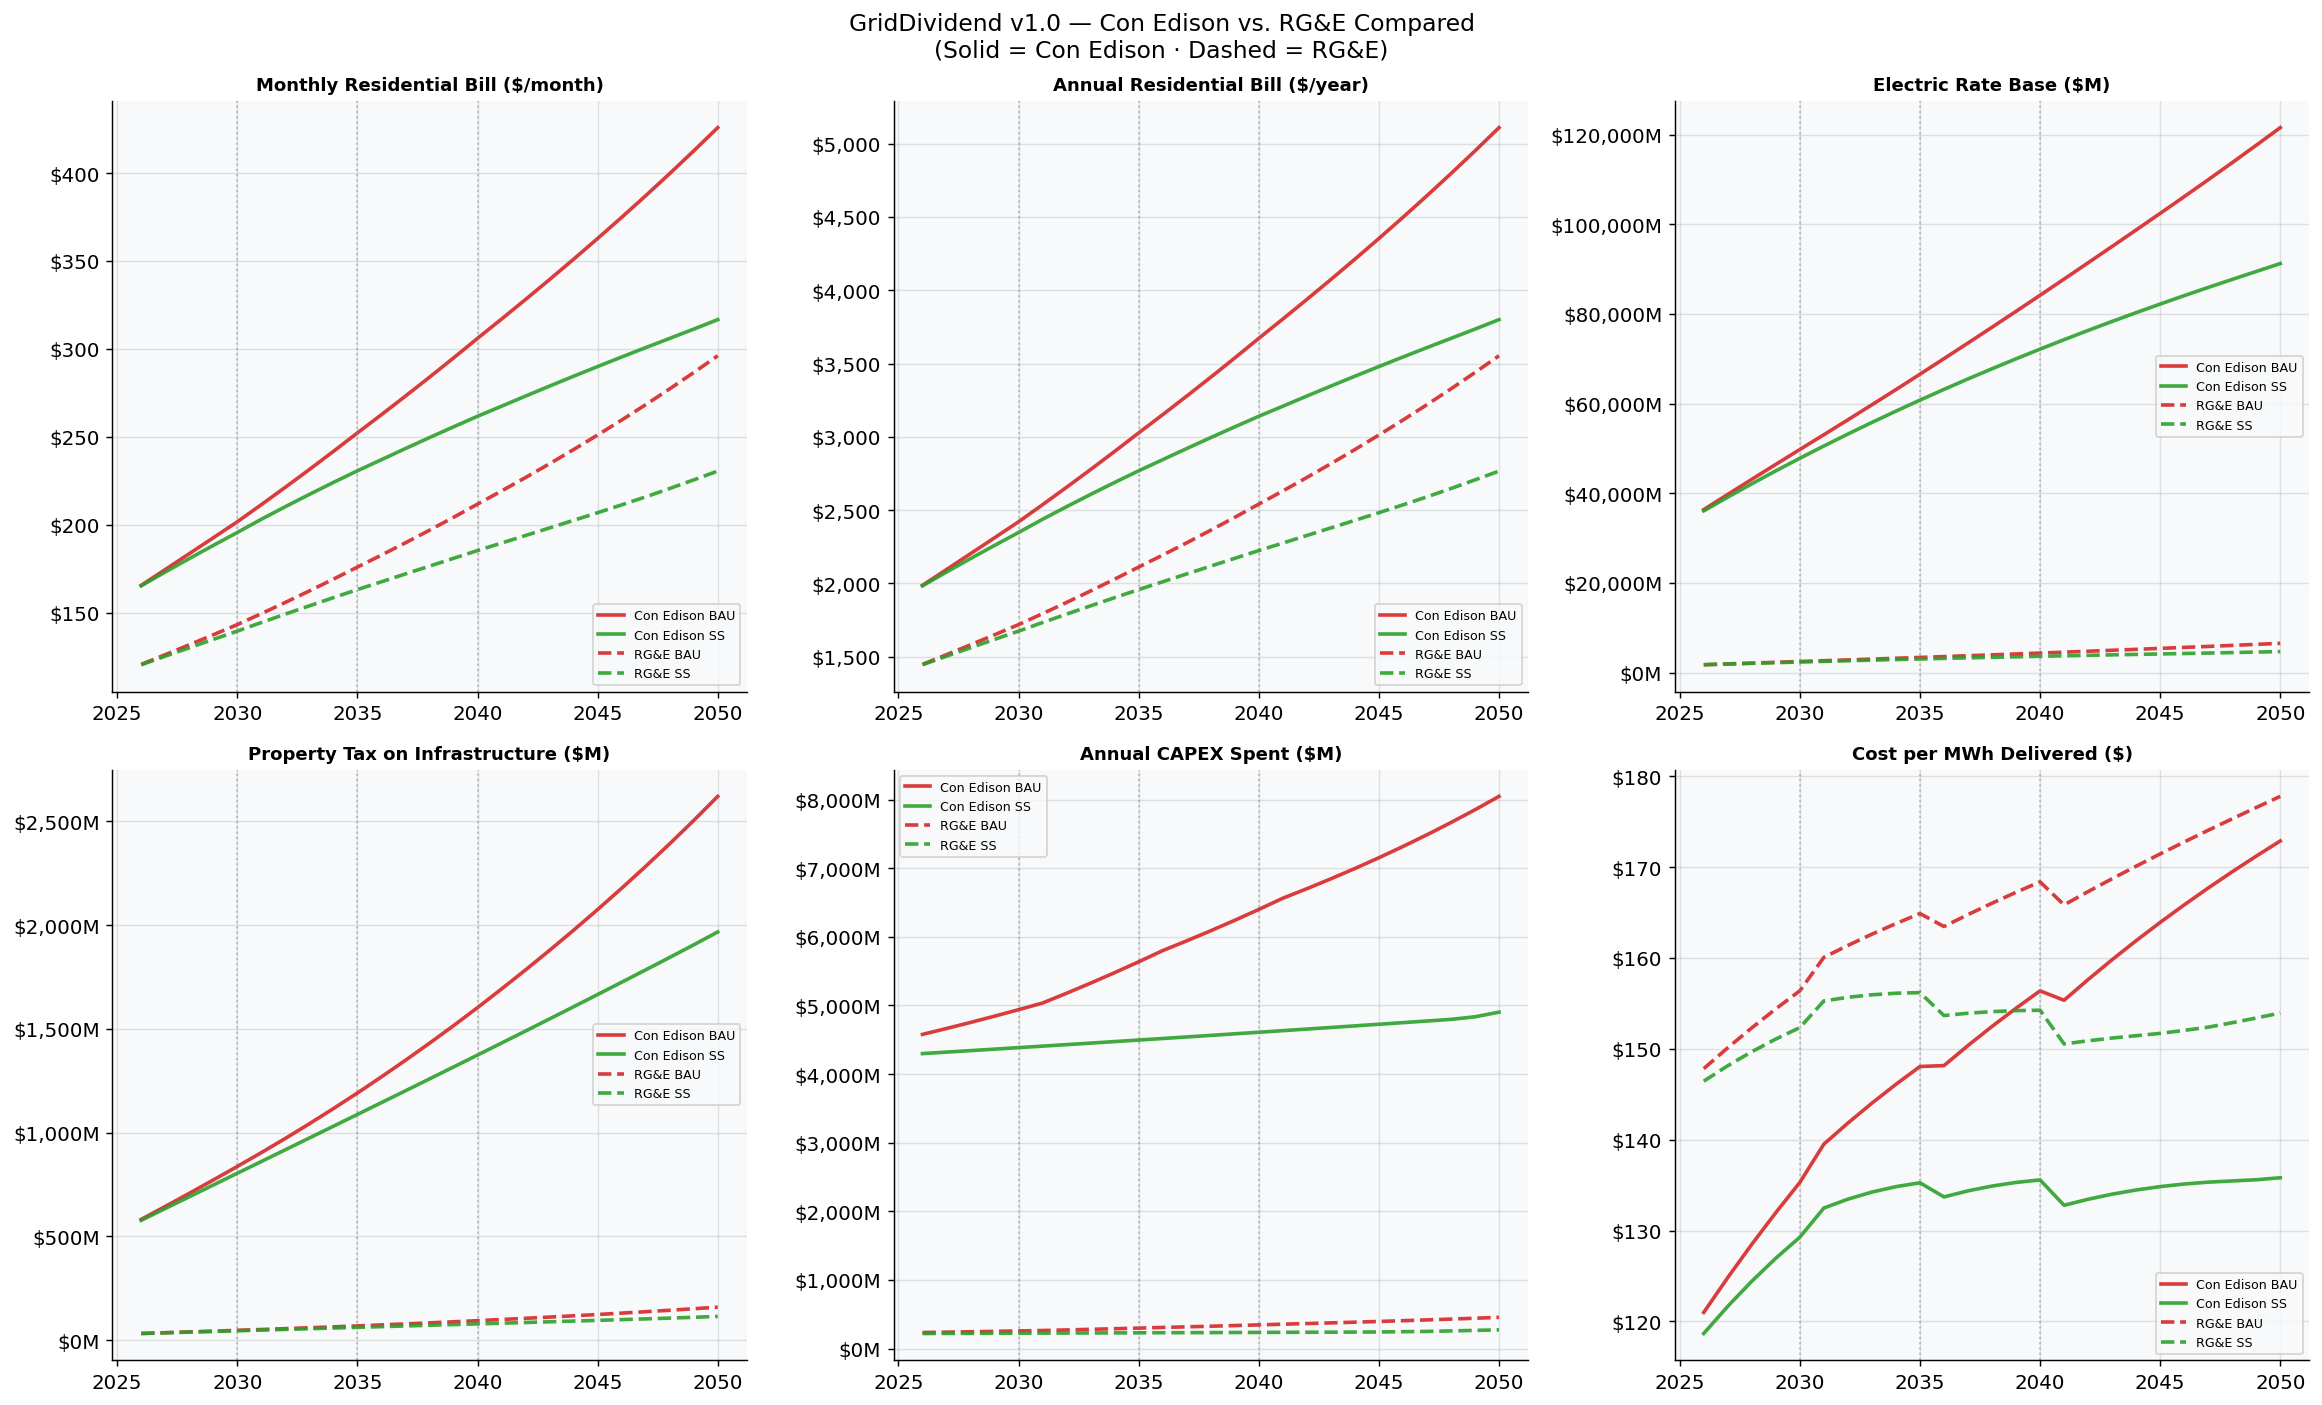

In [15]:
if len(utilities_to_run) < 2:
    print("Set utilities_to_run = ['ConEd', 'RGE'] in Section 1 to see comparison.")
else:
    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    fig.suptitle('GridDividend v1.0 — Con Edison vs. RG&E Compared\n'
                 '(Solid = Con Edison · Dashed = RG&E)', fontsize=13)
    panels = [
        ('avg_monthly_bill', 'Monthly Residential Bill ($/month)',  '${:,.0f}'),
        ('avg_annual_bill',  'Annual Residential Bill ($/year)',    '${:,.0f}'),
        ('rate_base_m',      'Electric Rate Base ($M)',             '${:,.0f}M'),
        ('property_tax_m',   'Property Tax on Infrastructure ($M)', '${:,.0f}M'),
        ('capex_spent_m',    'Annual CAPEX Spent ($M)',             '${:,.0f}M'),
        ('cost_per_mwh',     'Cost per MWh Delivered ($)',          '${:,.0f}'),
    ]
    for idx, (col, title, fmt) in enumerate(panels):
        ax = axes[idx // 3][idx % 3]
        for key in utilities_to_run:
            bau = results[key]['bau']; sh = results[key]['shared']
            lbl = UTILITIES[key]['short_name']
            ls  = '--' if key == 'RGE' else '-'
            ax.plot(YEARS, bau[col], color=C['bau'],    lw=2, ls=ls, alpha=0.9, label=f'{lbl} BAU')
            ax.plot(YEARS, sh[col],  color=C['shared'], lw=2, ls=ls, alpha=0.9, label=f'{lbl} SS')
        for yr in MY: ax.axvline(yr, color='gray', ls=':', alpha=0.45, lw=1.1)
        ax.set_title(title, fontsize=10)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _, f=fmt: f.format(x)))
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig('charts/chart5_comparison.png', bbox_inches='tight', dpi=130)
    plt.show()

## Section 9b: Near-Term vs Long-Term Trade-Off

These scenarios explore the parameter space around near-term vs long-term bill savings. They are not forecasts and do not represent recommendations. BASE is the reference case. ACCELERATED assumes the utility has existing NWS capabilities and the programme reaches maturity faster — this is a legislative design choice about what preconditions the statute should require before the reform takes effect. FREEZE\_PLUS uses a longer rate freeze as the near-term mechanism, accepting deferred cost recovery in exchange for immediate relief. COMBINED layers both approaches. Each has different implications for utility commercial viability, regulatory complexity, and legislative design — the choice between them is a policy question, not a modelling one.

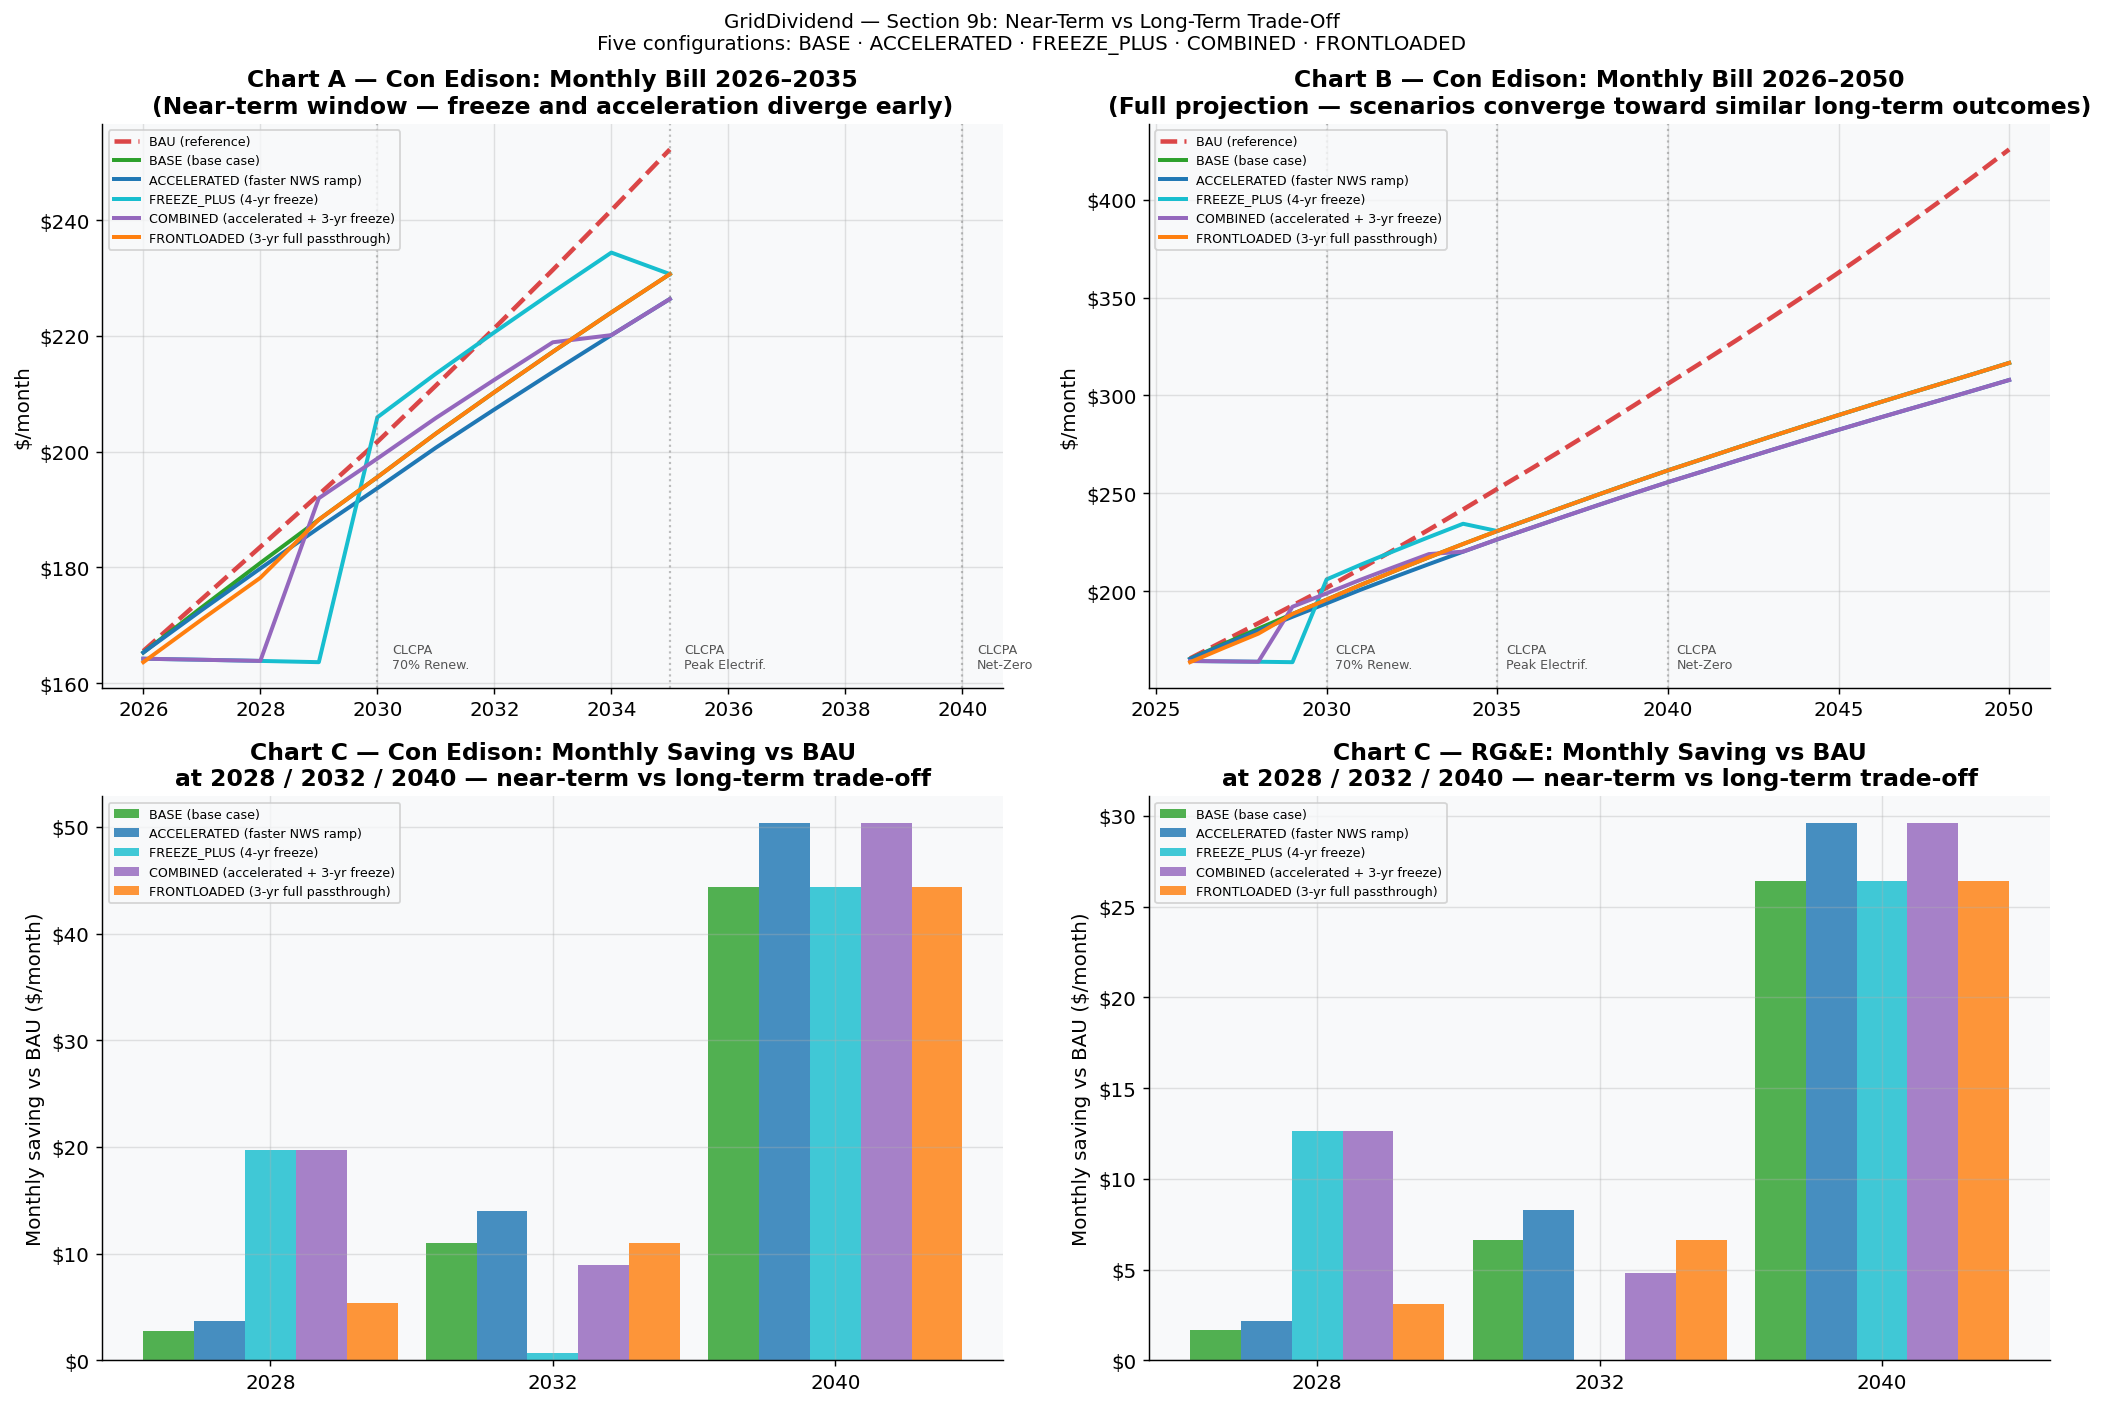

In [16]:
# ============================================================
# SECTION 9b: NEAR-TERM VS LONG-TERM TRADE-OFF — CHARTS
# Chart A: Con Edison monthly bill trajectories, 2026-2035 (near-term window)
# Chart B: Con Edison monthly bill trajectories, 2026-2050 (full projection)
# Chart C: Monthly saving vs BAU at 2028/2032/2040, both utilities side by side
# ============================================================

k_main    = utilities_to_run[0]
name_main = UTILITIES[k_main]['short_name']
bau_main  = results[k_main]['bau']

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(
    'GridDividend — Section 9b: Near-Term vs Long-Term Trade-Off\n'
    'Five configurations: BASE · ACCELERATED · FREEZE_PLUS · COMBINED · FRONTLOADED',
    fontsize=11)

# ── Chart A: near-term window 2026–2035 ──────────────────────────────────────
ax = axes[0, 0]
bau_a = bau_main[bau_main['year'] <= 2035]
ax.plot(bau_a['year'], bau_a['avg_monthly_bill'],
        color=C['bau'], lw=2.5, ls='--', alpha=0.85, label='BAU (reference)')
for sname, sdef in SCENARIO_DEFS.items():
    df_a = scenario_results[k_main][sname]
    df_a = df_a[df_a['year'] <= 2035]
    ax.plot(df_a['year'], df_a['avg_monthly_bill'],
            color=sdef['colour'], lw=2.2, label=sdef['label'])
vlines(ax)
ax.set_title(f'Chart A — {name_main}: Monthly Bill 2026–2035\n'
             '(Near-term window — freeze and acceleration diverge early)')
ax.set_ylabel('$/month')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.legend(fontsize=7, loc='upper left')

# ── Chart B: full projection 2026–2050 ───────────────────────────────────────
ax = axes[0, 1]
ax.plot(YEARS, bau_main['avg_monthly_bill'],
        color=C['bau'], lw=2.5, ls='--', alpha=0.85, label='BAU (reference)')
for sname, sdef in SCENARIO_DEFS.items():
    df_b = scenario_results[k_main][sname]
    ax.plot(df_b['year'], df_b['avg_monthly_bill'],
            color=sdef['colour'], lw=2.2, label=sdef['label'])
vlines(ax)
ax.set_title(f'Chart B — {name_main}: Monthly Bill 2026–2050\n'
             '(Full projection — scenarios converge toward similar long-term outcomes)')
ax.set_ylabel('$/month')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.legend(fontsize=7, loc='upper left')

# ── Chart C: savings vs BAU at 2028 / 2032 / 2040, both utilities ────────────
snapshots = [2028, 2032, 2040]
x_pos     = np.arange(len(snapshots))
bar_w     = max(0.10, 0.90 / len(SCENARIO_DEFS))

for ci, k in enumerate(utilities_to_run[:2]):
    ax     = axes[1, ci]
    bau_df = results[k]['bau']
    for si, (sname, sdef) in enumerate(SCENARIO_DEFS.items()):
        sh_df   = scenario_results[k][sname]
        savings = []
        for yr in snapshots:
            bau_bill = bau_df[bau_df['year'] == yr].iloc[0]['avg_monthly_bill']
            sh_bill  = sh_df[sh_df['year']  == yr].iloc[0]['avg_monthly_bill']
            savings.append(max(0.0, bau_bill - sh_bill))
        offset = (si - (len(SCENARIO_DEFS) - 1) / 2) * bar_w
        ax.bar(x_pos + offset, savings, bar_w,
               color=sdef['colour'], label=sdef['label'], alpha=0.82)
    ax.set_xticks(x_pos)
    ax.set_xticklabels([str(y) for y in snapshots])
    ax.set_ylabel('Monthly saving vs BAU ($/month)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}'))
    ax.set_title(f'Chart C — {UTILITIES[k]["short_name"]}: Monthly Saving vs BAU\n'
                 'at 2028 / 2032 / 2040 — near-term vs long-term trade-off')
    ax.legend(fontsize=7)

if len(utilities_to_run) < 2:
    axes[1, 1].set_visible(False)

plt.tight_layout()
plt.savefig('charts/chart9b_nearterm_tradeoff.png', bbox_inches='tight', dpi=130)
plt.show()


In [17]:
# ============================================================
# SECTION 9b: NEAR-TERM VS LONG-TERM TRADE-OFF — SUMMARY TABLES
# Separate tables for each utility.
# Per scenario: bills at 2028/2035/2050, first year savings exceed
# $10/month vs BAU, and cumulative savings to 2050.
# ============================================================

def print_scenario_table(k):
    name   = UTILITIES[k]['short_name']
    bau_df = results[k]['bau']
    hdr = (f"  {'Scenario':<16} {'2028 $/mo':>10} {'2035 $/mo':>10} "
           f"{'2050 $/mo':>10} {'$10+/mo yr':>11} {'Cum $B':>8}")
    print(f'Section 9b — {name} Scenario Summary Table (600 kWh/month benchmark)')
    print(hdr)
    print('  ' + '-' * (len(hdr) - 2))
    for sname, sdef in SCENARIO_DEFS.items():
        df  = scenario_results[k][sname]
        b28 = df[df['year'] == 2028].iloc[0]['avg_monthly_bill']
        b35 = df[df['year'] == 2035].iloc[0]['avg_monthly_bill']
        b50 = df[df['year'] == 2050].iloc[0]['avg_monthly_bill']
        first_10 = '—'
        for yr in YEARS:
            bau_bill = bau_df[bau_df['year'] == yr].iloc[0]['avg_monthly_bill']
            sh_bill  = df[df['year'] == yr].iloc[0]['avg_monthly_bill']
            if bau_bill - sh_bill > 10:
                first_10 = str(yr)
                break
        cum = np.sum(
            (bau_df['avg_annual_bill'].values - df['avg_annual_bill'].values)
            * df['customers'].values
        ) / 1e9
        print(f'  {sname:<16} {b28:>9.1f}  {b35:>9.1f}  {b50:>9.1f}  '
              f'{first_10:>10}  {cum:>6.1f}B')
    print()

for k in utilities_to_run:
    print_scenario_table(k)


Section 9b — Con Edison Scenario Summary Table (600 kWh/month benchmark)
  Scenario          2028 $/mo  2035 $/mo  2050 $/mo  $10+/mo yr   Cum $B
  ----------------------------------------------------------------------
  BASE                 180.8      230.7      316.7        2032    50.5B
  ACCELERATED          179.8      226.4      307.9        2031    56.5B
  FREEZE_PLUS          163.9      230.7      316.7        2027    50.4B
  COMBINED             163.9      226.4      307.9        2027    56.5B
  FRONTLOADED          178.2      230.7      316.7        2032    50.8B

Section 9b — RG&E Scenario Summary Table (600 kWh/month benchmark)
  Scenario          2028 $/mo  2035 $/mo  2050 $/mo  $10+/mo yr   Cum $B
  ----------------------------------------------------------------------
  BASE                 130.1      163.2      230.5        2034     3.1B
  ACCELERATED          129.6      160.8      225.9        2033     3.5B
  FREEZE_PLUS          119.1      163.2      230.5        2028 

$10/month threshold year by NWS ramp length (BASE params)
   Ramp yrs    Con Edison          RG&E
  --------------------------------------
          5          2032          2034
          6          2032          2034
          7          2032          2034
          8          2032          2034
          9          2032          2034 ◄ BASE
         10          2032          2034
         11          2032          2034
         12          2032          2034
         13          2032          2034
         14          2032          2035
         15          2032          2035


Saved: charts_article/chart6_ramp_sensitivity.png


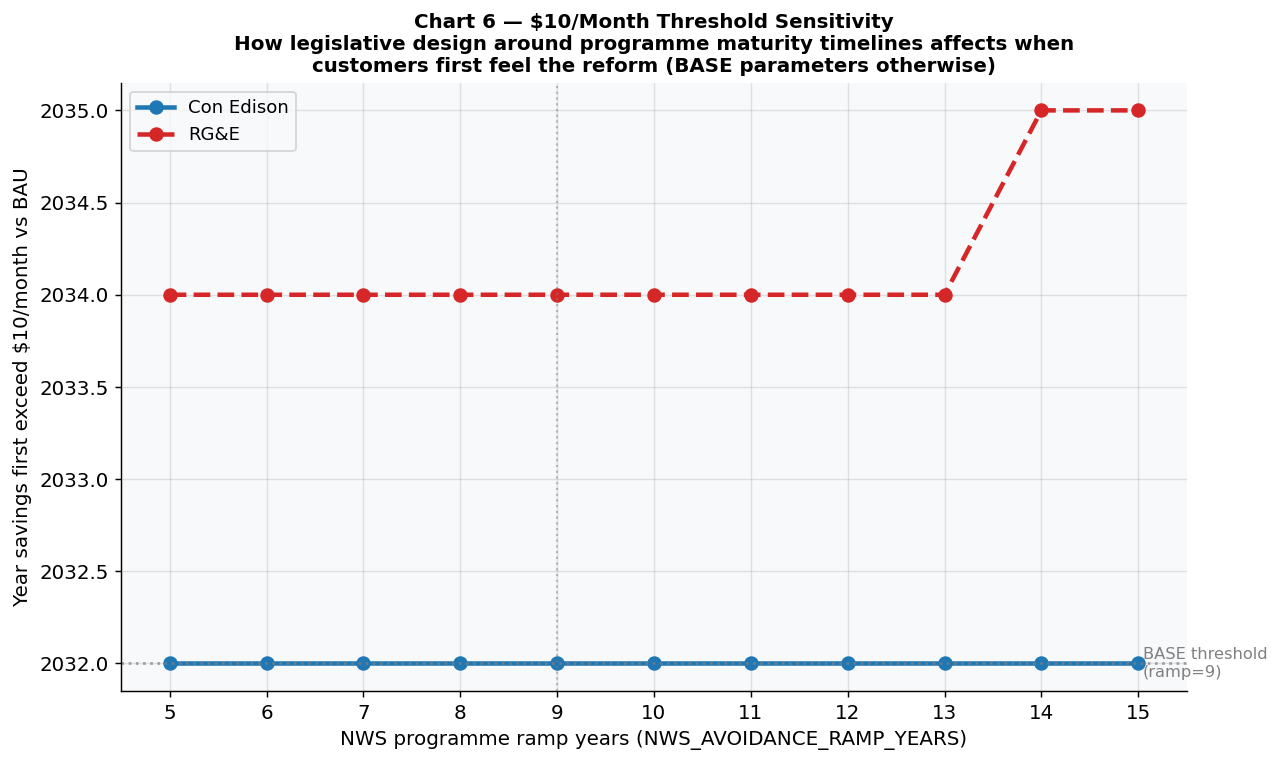

In [18]:
# ============================================================
# SECTION 9b (CONTINUED): $10/MONTH THRESHOLD RAMP SENSITIVITY
# Sweeps NWS_AVOIDANCE_RAMP_YEARS 5→15, BASE case params otherwise.
# For each ramp length: first year monthly savings vs BAU exceed $10/mo.
# ============================================================

ramp_range = list(range(5, 16))   # 5 to 15 inclusive
ramp_threshold = {k: [] for k in utilities_to_run}

for ramp_yrs in ramp_range:
    cfg = {**MODEL_CONFIG, 'NWS_AVOIDANCE_RAMP_YEARS': ramp_yrs}
    for k in utilities_to_run:
        p      = utility_data[k]
        bau_df = results[k]['bau']
        sh     = project(p, 'shared', False, config=cfg)
        # Apply same capacity pass-through as run_named_scenario BASE
        cap_cost_start = (CAPACITY_COST_START[k]
                          if isinstance(CAPACITY_COST_START, dict) else CAPACITY_COST_START)
        pt_m = []
        for yr in YEARS:
            b_row = bau_df[bau_df['year']==yr].iloc[0]
            s_row = sh[sh['year']==yr].iloc[0]
            peak_red = max(0.0, b_row['peak_mw'] - s_row['peak_mw'])
            cap_c    = cap_cost_start * (1 + CAPACITY_COST_GROWTH)**(yr-2026)
            saving_m = peak_red * cap_c
            monthly_red = (saving_m*(1-UTILITY_SAVINGS_SHARE)*1e6) / (s_row['customers']*12)
            pt_m.append(monthly_red)
        pt_df = pd.DataFrame({'year': YEARS, 'pt': pt_m})
        sh = sh.merge(pt_df, on='year', how='left')
        sh['avg_monthly_bill'] -= sh['pt']
        threshold_yr = None
        for yr in YEARS:
            bau_bill = bau_df[bau_df['year']==yr].iloc[0]['avg_monthly_bill']
            sh_bill  = sh[sh['year']==yr].iloc[0]['avg_monthly_bill']
            if bau_bill - sh_bill > 10:
                threshold_yr = yr
                break
        ramp_threshold[k].append(threshold_yr if threshold_yr else 2051)

# Print results table
print('$10/month threshold year by NWS ramp length (BASE params)')
print(f"  {'Ramp yrs':>9}", end='')
for k in utilities_to_run:
    print(f"  {UTILITIES[k]['short_name']:>12}", end='')
print()
print('  ' + '-' * (10 + 14 * len(utilities_to_run)))
for i, r in enumerate(ramp_range):
    marker = ' ◄ BASE' if r == 9 else ''
    print(f"  {r:>9}", end='')
    for k in utilities_to_run:
        t = ramp_threshold[k][i]
        print(f"  {t if t < 2051 else '>2050':>12}", end='')
    print(marker)

# Chart 6: ramp sensitivity
import os; os.makedirs('charts_article', exist_ok=True)

fig6, ax6 = plt.subplots(figsize=(10, 6))
util_styles = {'ConEd': ('-', '#1f77b4', 'Con Edison'),
               'RGE':   ('--', '#d62728', 'RG\u0026E')}
for k in utilities_to_run:
    ls, col, lbl = util_styles.get(k, ('-', '#888888', UTILITIES[k]['short_name']))
    vals = [t if t < 2051 else None for t in ramp_threshold[k]]
    ax6.plot(ramp_range, vals, color=col, ls=ls, lw=2.5, marker='o', ms=7, label=lbl)
_base_ramp = MODEL_CONFIG['NWS_AVOIDANCE_RAMP_YEARS']
_base_thr = ramp_threshold[utilities_to_run[0]][ramp_range.index(_base_ramp)]
if _base_thr < 2051:
    ax6.axhline(_base_thr, color='gray', ls=':', lw=1.5, alpha=0.7)
    ax6.text(15.05, _base_thr, f'BASE threshold\n(ramp={_base_ramp})', fontsize=9, va='center', color='gray')
ax6.axvline(_base_ramp, color='gray', ls=':', lw=1.2, alpha=0.5)
ax6.set_xlabel('NWS programme ramp years (NWS_AVOIDANCE_RAMP_YEARS)', fontsize=11)
ax6.set_ylabel('Year savings first exceed $10/month vs BAU', fontsize=11)
ax6.set_title('Chart 6 — $10/Month Threshold Sensitivity\n'
              'How legislative design around programme maturity timelines affects when\n'
              'customers first feel the reform (BASE parameters otherwise)',
              fontsize=11)
ax6.set_xticks(ramp_range)
ax6.set_xlim(4.5, 15.5)
ax6.legend(fontsize=10)
fig6.tight_layout()
fname6 = 'charts_article/chart6_ramp_sensitivity.png'
fig6.savefig(fname6, dpi=300, bbox_inches='tight')
print(f'Saved: {fname6}')
plt.show()


## Section 9c: Article Charts

Six publication-quality charts saved to `charts_article/` at 300 dpi, plus a ramp sensitivity analysis for Section 9b.

**Chart 1:** Near-term bill savings vs BAU, Con Edison, 2026–2035  
**Chart 2:** Full-projection bill savings vs BAU, Con Edison, 2026–2050  
**Chart 3:** Near-term bill savings vs BAU, RG&E, 2026–2035  
**Chart 4:** Full-projection bill savings vs BAU, RG&E, 2026–2050  
**Chart 5:** Milestone bar chart — savings at 2028 / 2032 / 2040, both utilities  
**Chart 6:** Ramp sensitivity — year $10/month threshold reached vs NWS ramp years

Saved: charts_article/chart1_coned_nearterm.png


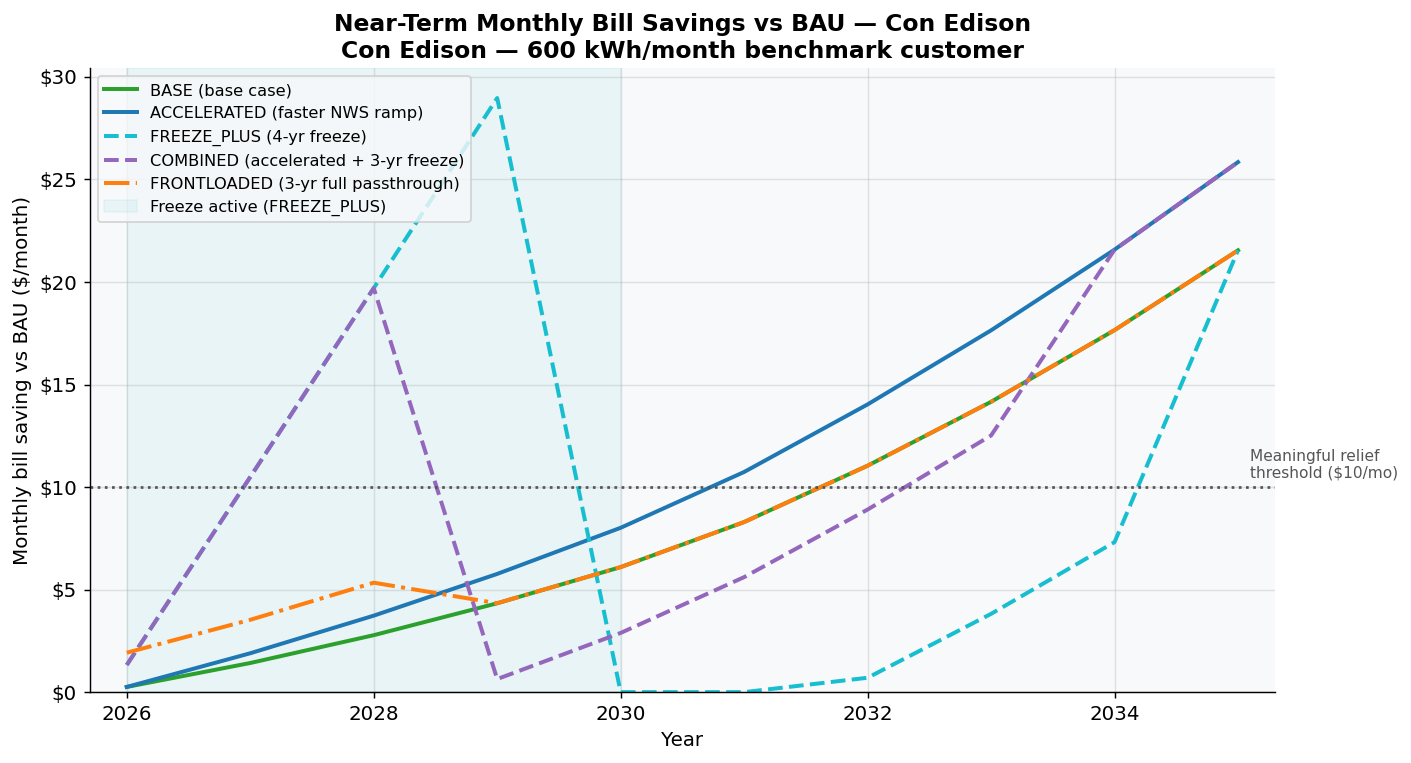

Saved: charts_article/chart2_coned_full.png


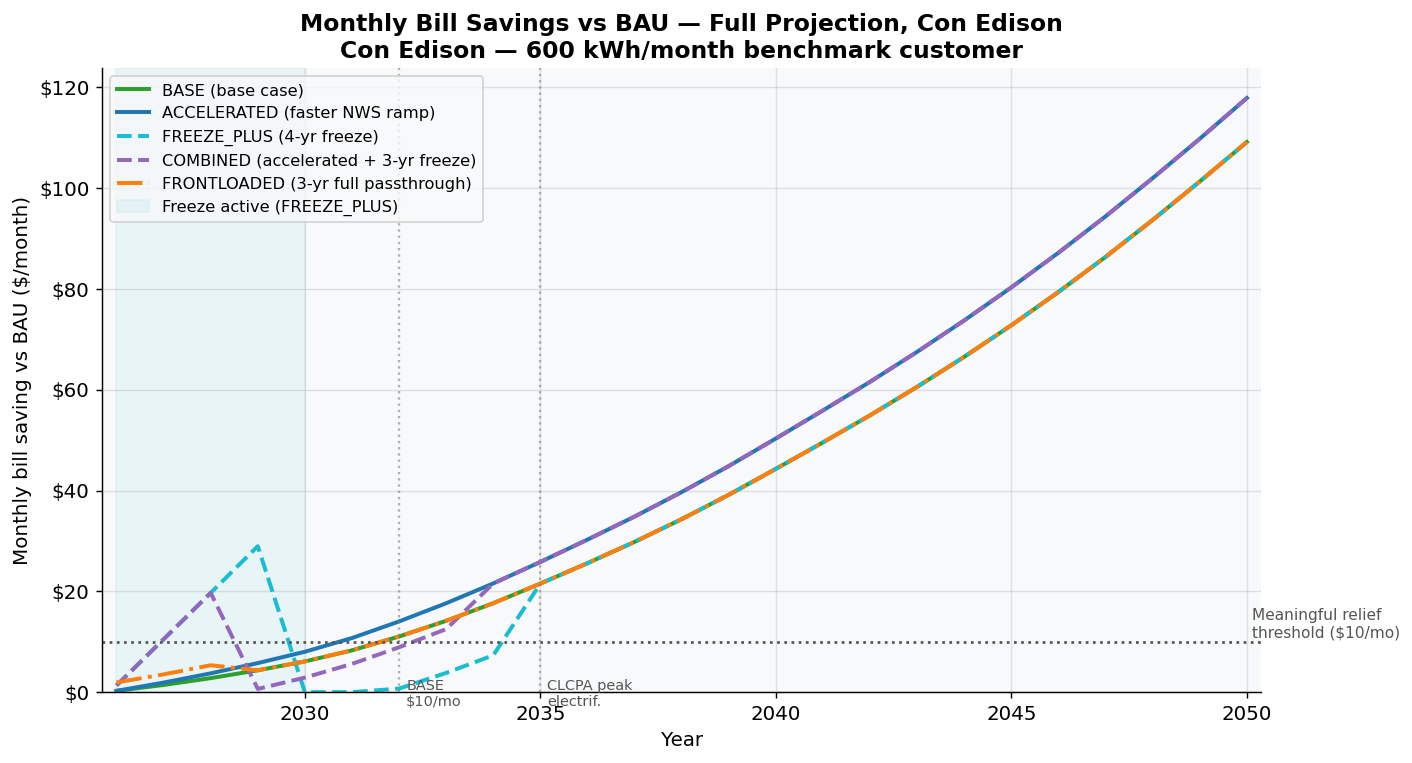

Saved: charts_article/chart3_rge_nearterm.png


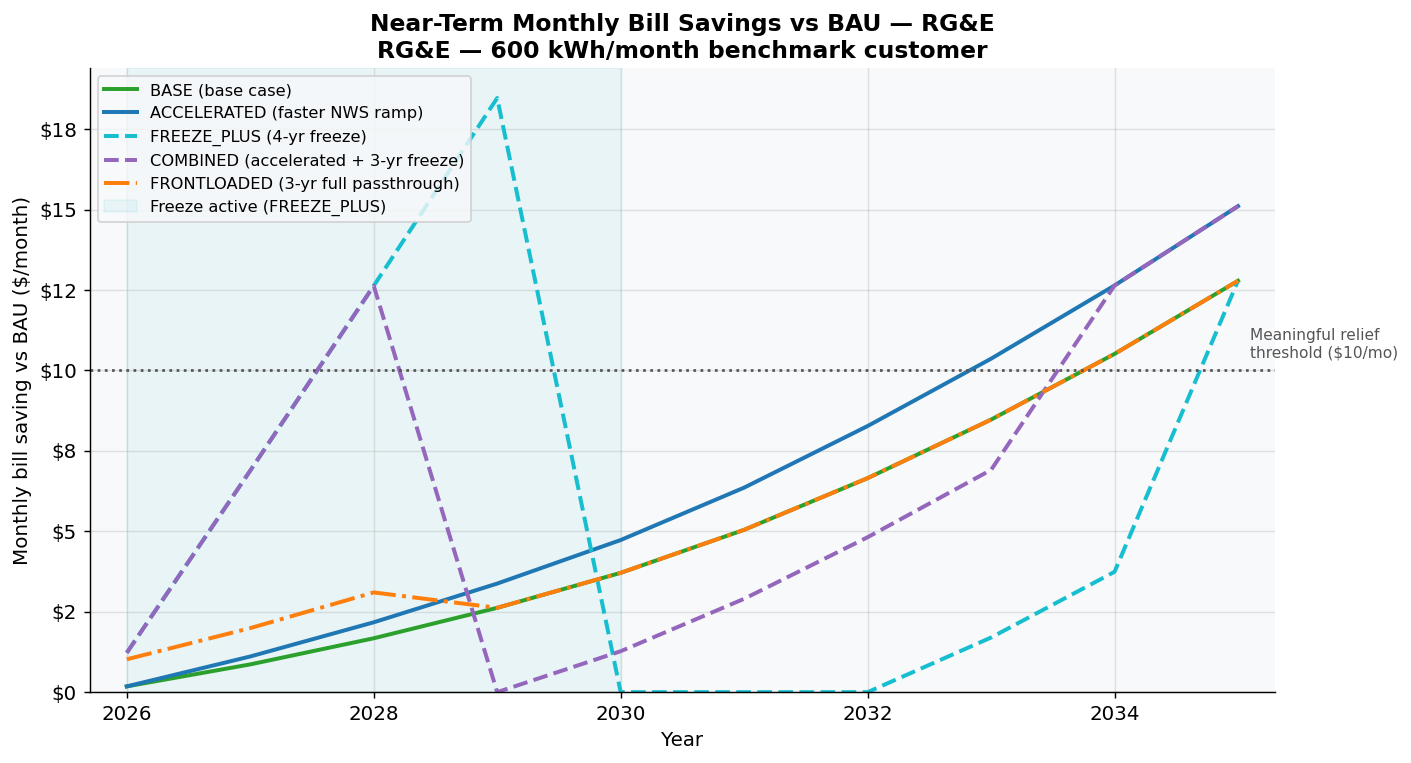

Saved: charts_article/chart4_rge_full.png


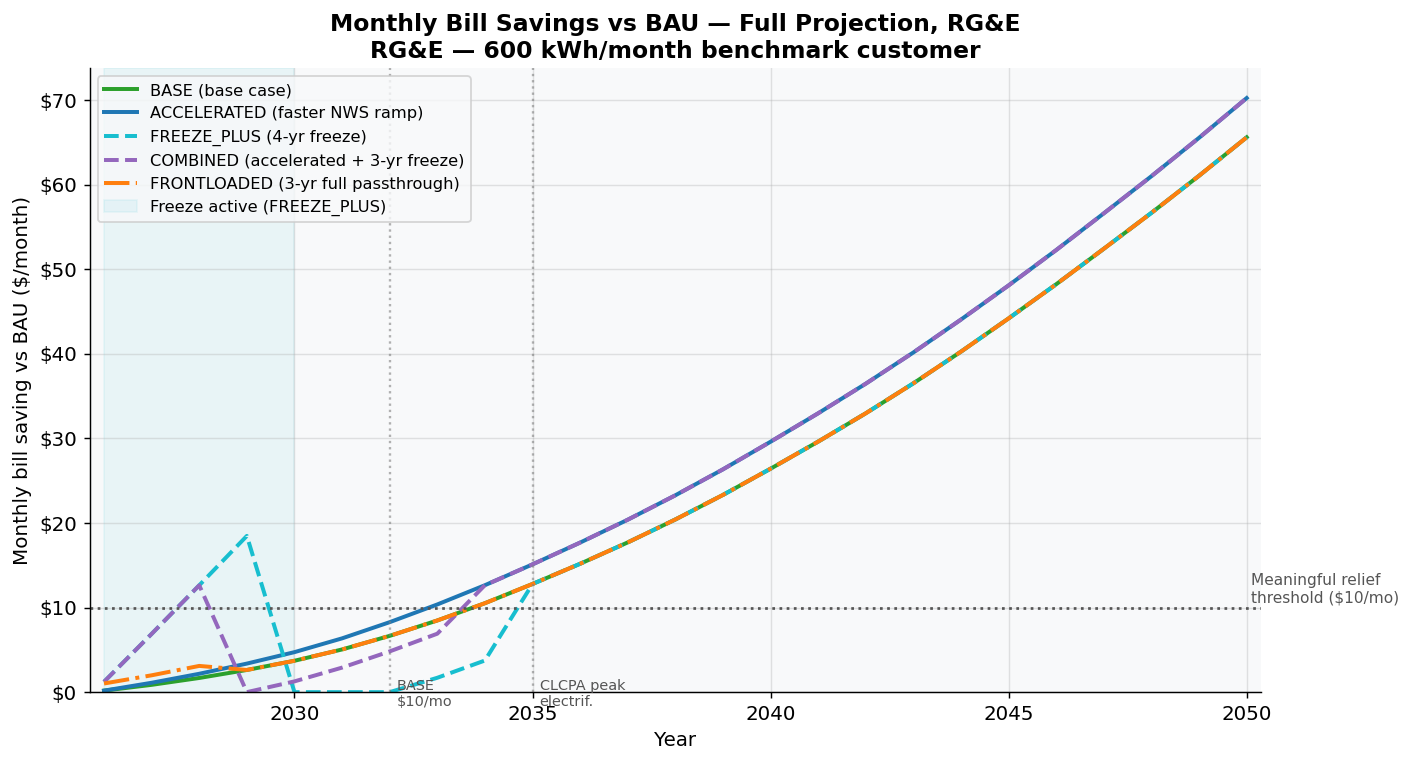

Saved: charts_article/chart5_milestone_bars.png


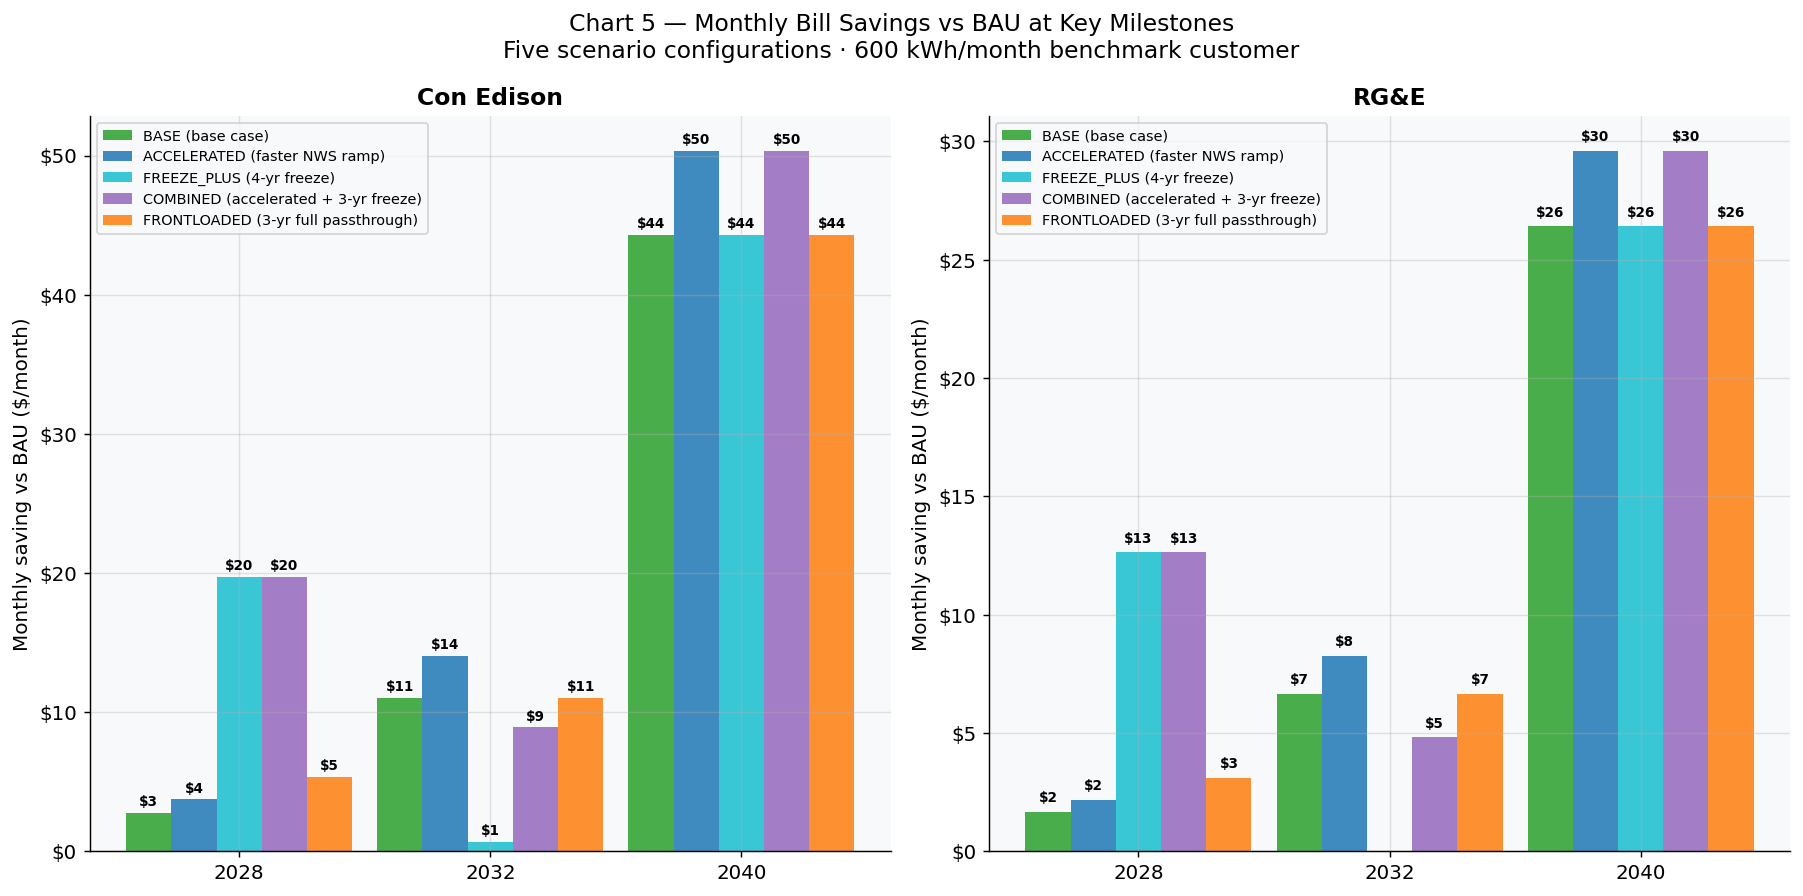

In [19]:
# ============================================================
# SECTION 9c: ARTICLE CHARTS 1-5
# All saved to charts_article/ at 300 dpi.
# Charts 1-4: monthly savings vs BAU (floor 0), near-term and full.
# Chart 5: bar chart at milestone years, both utilities.
# ============================================================

import os; os.makedirs('charts_article', exist_ok=True)

SC = {sname: sdef for sname, sdef in SCENARIO_DEFS.items()}
SC_LINES = {
    'BASE':        ('-',   SC['BASE']['colour'],        'BASE (base case)'),
    'ACCELERATED': ('-',   SC['ACCELERATED']['colour'], 'ACCELERATED (faster NWS ramp)'),
    'FREEZE_PLUS': ('--',  SC['FREEZE_PLUS']['colour'], 'FREEZE_PLUS (4-yr freeze)'),
    'COMBINED':    ('--',  SC['COMBINED']['colour'],    'COMBINED (accelerated + 3-yr freeze)'),
    'FRONTLOADED': ('-.',  SC['FRONTLOADED']['colour'], 'FRONTLOADED (3-yr full passthrough)'),
}

def savings_series(k, sname, years=None):
    """Monthly savings vs BAU, floored at 0, for given years."""
    if years is None: years = YEARS
    bau_df = results[k]['bau']
    sh_df  = scenario_results[k][sname]
    savs = []
    for yr in years:
        b = bau_df[bau_df['year']==yr].iloc[0]['avg_monthly_bill']
        s = sh_df[sh_df['year']==yr].iloc[0]['avg_monthly_bill']
        savs.append(max(0.0, b - s))
    return savs

def make_savings_chart(k, years, title, fname, extra_vlines=None):
    """Charts 1-4 template: savings vs BAU over a year range."""
    name = UTILITIES[k]['short_name']
    # FREEZE_PLUS freeze end year (2026 + RATE_FREEZE_YEARS = 2030)
    freeze_end_yr = 2026 + SC['FREEZE_PLUS']['params'].get('RATE_FREEZE_YEARS', RATE_FREEZE_YEARS)

    fig, ax = plt.subplots(figsize=(11, 6))
    for sname, (ls, col, lbl) in SC_LINES.items():
        svs = savings_series(k, sname, years)
        ax.plot(years, svs, color=col, ls=ls, lw=2.2, label=lbl)

    # $10/month reference line
    ax.axhline(10, color='#555', ls=':', lw=1.5)
    ax.text(years[-1] + 0.1, 10.3, 'Meaningful relief\nthreshold ($10/mo)',
            fontsize=8.5, va='bottom', color='#555')

    # Shade freeze-active period for FREEZE_PLUS
    freeze_shade_end = min(freeze_end_yr, years[-1])
    if freeze_shade_end > years[0]:
        ax.axvspan(years[0], freeze_shade_end, alpha=0.07,
                   color=SC['FREEZE_PLUS']['colour'], label='Freeze active (FREEZE_PLUS)')

    # Extra vertical reference lines
    if extra_vlines:
        for yr, lbl in extra_vlines.items():
            if years[0] <= yr <= years[-1]:
                ax.axvline(yr, color='gray', ls=':', lw=1.3, alpha=0.6)
                ylo, yhi = ax.get_ylim()
                ax.text(yr + 0.15, ylo + (yhi-ylo)*0.02, lbl,
                        fontsize=8, color='#555', va='bottom')

    ax.set_xlabel('Year', fontsize=11)
    ax.set_ylabel('Monthly bill saving vs BAU ($/month)', fontsize=11)
    ax.set_title(f'{title}\n{name} — 600 kWh/month benchmark customer', fontsize=13)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}'))
    ax.set_xlim(years[0] - 0.3, years[-1] + 0.3)
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=9, loc='upper left')
    fig.tight_layout()
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    print(f'Saved: {fname}')
    plt.show()

# ── Charts 1–4 ───────────────────────────────────────────────────────────────
near = [y for y in YEARS if y <= 2035]
full = YEARS
vlines_full = {2032: 'BASE\n$10/mo', 2035: 'CLCPA peak\nelectrif.'}

k_primary = utilities_to_run[0]
name_primary = UTILITIES[k_primary]['short_name']

make_savings_chart(
    k_primary, near,
    f'Near-Term Monthly Bill Savings vs BAU — {name_primary}',
    f'charts_article/chart1_{k_primary.lower()}_nearterm.png')

make_savings_chart(
    k_primary, full,
    f'Monthly Bill Savings vs BAU — Full Projection, {name_primary}',
    f'charts_article/chart2_{k_primary.lower()}_full.png',
    extra_vlines=vlines_full)

if 'RGE' in utilities_to_run:
    make_savings_chart(
        'RGE', near,
        'Near-Term Monthly Bill Savings vs BAU — RG\u0026E',
        'charts_article/chart3_rge_nearterm.png')

    make_savings_chart(
        'RGE', full,
        'Monthly Bill Savings vs BAU — Full Projection, RG\u0026E',
        'charts_article/chart4_rge_full.png',
        extra_vlines=vlines_full)

# ── Chart 5: bar chart — milestone savings, both utilities ────────────────────
snapshots  = [2028, 2032, 2040]
x_pos      = np.arange(len(snapshots))
snames     = list(SC.keys())
bar_w      = max(0.10, 0.90 / len(snames))
n_util     = min(2, len(utilities_to_run))

fig5, axes5 = plt.subplots(1, n_util, figsize=(7 * n_util, 7), sharey=False)
if n_util == 1: axes5 = [axes5]

for ci, k in enumerate(utilities_to_run[:n_util]):
    ax = axes5[ci]
    bau_df = results[k]['bau']
    for si, sname in enumerate(snames):
        ls, col, lbl = SC_LINES[sname]
        sh_df   = scenario_results[k][sname]
        savings = []
        for yr in snapshots:
            b = bau_df[bau_df['year']==yr].iloc[0]['avg_monthly_bill']
            s = sh_df[sh_df['year']==yr].iloc[0]['avg_monthly_bill']
            savings.append(max(0.0, b - s))
        offset = (si - (len(snames) - 1) / 2) * bar_w
        bars = ax.bar(x_pos + offset, savings, bar_w, color=col,
                      label=lbl, alpha=0.85)
        for bar, val in zip(bars, savings):
            if val >= 0.5:
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                        f'${val:.0f}', ha='center', va='bottom', fontsize=7.5,
                        fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels([str(y) for y in snapshots], fontsize=11)
    ax.set_ylabel('Monthly saving vs BAU ($/month)', fontsize=11)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}'))
    ax.set_title(f'{UTILITIES[k]["short_name"]}', fontsize=13, fontweight='bold')
    ax.legend(fontsize=8)
    ax.set_ylim(bottom=0)

fig5.suptitle(
    'Chart 5 — Monthly Bill Savings vs BAU at Key Milestones\n'
    'Five scenario configurations · 600 kWh/month benchmark customer',
    fontsize=13)
fig5.tight_layout()
fname5 = 'charts_article/chart5_milestone_bars.png'
fig5.savefig(fname5, dpi=300, bbox_inches='tight')
print(f'Saved: {fname5}')
plt.show()


Saved: charts_article/chart7_deferral_sensitivity.png


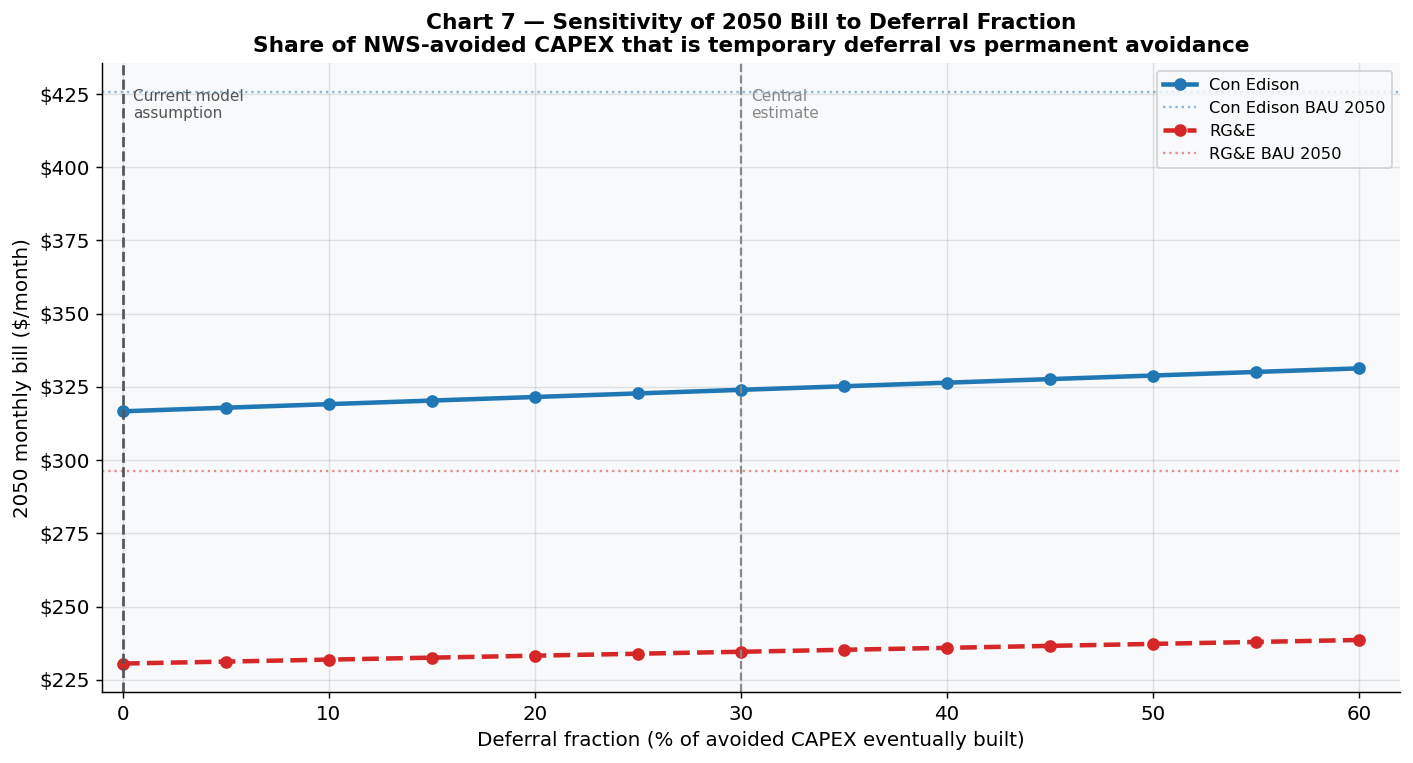


Deferral fraction sensitivity — 2050 monthly bill ($/month)
    Deferral %  Con Edison        RG&E
  --------------------------------------
            0%  $     317  $     231  ← current model
            5%  $     318  $     231
           10%  $     319  $     232
           15%  $     320  $     233
           20%  $     322  $     233
           25%  $     323  $     234
           30%  $     324  $     235  ← central estimate
           35%  $     325  $     235
           40%  $     326  $     236
           45%  $     328  $     237
           50%  $     329  $     237
           55%  $     330  $     238
           60%  $     331  $     239


In [20]:
# ============================================================
# SECTION 9d: DEFERRAL FRACTION SENSITIVITY
# Sweeps DEFERRAL_FRACTION 0.0 → 0.60 in steps of 0.05.
# For each value: re-runs shared savings scenario, records 2050 monthly bill.
# Saves chart7_deferral_sensitivity.png to charts_article/.
# ============================================================

import os; os.makedirs('charts_article', exist_ok=True)

deferral_range   = [round(x * 0.05, 2) for x in range(13)]  # 0.00 to 0.60
bill_2050_by_df  = {k: [] for k in utilities_to_run}

for df_val in deferral_range:
    cfg = {**MODEL_CONFIG, 'DEFERRAL_FRACTION': df_val}
    for k in utilities_to_run:
        p    = utility_data[k]
        sh   = project(p, 'shared', False, config=cfg)
        # Apply capacity pass-through (same as BASE scenario)
        bau_df_ref = results[k]['bau']
        cap_cs = (CAPACITY_COST_START[k]
                  if isinstance(CAPACITY_COST_START, dict) else CAPACITY_COST_START)
        pt_m = []
        for yr in YEARS:
            b_row = bau_df_ref[bau_df_ref['year'] == yr].iloc[0]
            s_row = sh[sh['year'] == yr].iloc[0]
            peak_red = max(0.0, b_row['peak_mw'] - s_row['peak_mw'])
            cap_c    = cap_cs * (1 + CAPACITY_COST_GROWTH) ** (yr - 2026)
            monthly_red = (peak_red * cap_c * (1 - UTILITY_SAVINGS_SHARE) * 1e6) / (
                           s_row['customers'] * 12)
            pt_m.append(monthly_red)
        pt_frame = pd.DataFrame({'year': YEARS, 'pt': pt_m})
        sh = sh.merge(pt_frame, on='year', how='left')
        sh['avg_monthly_bill'] -= sh['pt']
        b50 = sh[sh['year'] == 2050].iloc[0]['avg_monthly_bill']
        bill_2050_by_df[k].append(b50)

# ── Chart 7 ────────────────────────────────────────────────────────────────
fig7, ax7 = plt.subplots(figsize=(11, 6))

util_styles7 = {
    'ConEd': ('-',  '#1f77b4', 'Con Edison'),
    'RGE':   ('--', '#d62728', 'RG\u0026E'),
}

for k in utilities_to_run:
    ls7, col7, lbl7 = util_styles7.get(k, ('-', '#888888', k))
    ax7.plot([v * 100 for v in deferral_range], bill_2050_by_df[k],
             color=col7, ls=ls7, lw=2.5, marker='o', ms=6, label=lbl7)
    # BAU reference line
    bau_50 = results[k]['bau'][results[k]['bau']['year'] == 2050].iloc[0]['avg_monthly_bill']
    ax7.axhline(bau_50, color=col7, ls=':', lw=1.3, alpha=0.5,
                label=f'{UTILITIES[k]["short_name"]} BAU 2050')

ax7.axvline(0.0,  color='#555', ls='--', lw=1.5)
ax7.text(0.5,  ax7.get_ylim()[1] * 0.98, 'Current model\nassumption',
         fontsize=8.5, va='top', color='#555')
ax7.axvline(30.0, color='#888', ls='--', lw=1.2)
ax7.text(30.5, ax7.get_ylim()[1] * 0.98, 'Central\nestimate',
         fontsize=8.5, va='top', color='#888')

ax7.set_xlabel('Deferral fraction (% of avoided CAPEX eventually built)', fontsize=11)
ax7.set_ylabel('2050 monthly bill ($/month)', fontsize=11)
ax7.set_title(
    'Chart 7 — Sensitivity of 2050 Bill to Deferral Fraction\n'
    'Share of NWS-avoided CAPEX that is temporary deferral vs permanent avoidance',
    fontsize=12)
ax7.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}'))
ax7.set_xlim(-1, 62)
ax7.legend(fontsize=9)
fig7.tight_layout()
fname7 = 'charts_article/chart7_deferral_sensitivity.png'
fig7.savefig(fname7, dpi=300, bbox_inches='tight')
print(f'Saved: {fname7}')
plt.show()

# Print summary table
print('\nDeferral fraction sensitivity — 2050 monthly bill ($/month)')
hdr = f"  {'Deferral %':>12}"
for k in utilities_to_run:
    hdr += f"  {UTILITIES[k]['short_name']:>10}"
print(hdr)
print('  ' + '-' * (14 + 12 * len(utilities_to_run)))
for i, df_val in enumerate(deferral_range):
    row = f'  {df_val*100:>11.0f}%'
    for k in utilities_to_run:
        row += f'  ${bill_2050_by_df[k][i]:>8.0f}'
    marker = '  ← current model' if df_val == 0.0 else (
             '  ← central estimate' if df_val == 0.30 else '')
    print(row + marker)

## Section 9d: The Long-Term Case — Cumulative Cost and Policy Window Analysis

These charts address the central policy question: not how much does shared savings reform save in year one, but what does it mean for what customers pay over the lifetime of the programme? The cumulative cost chart, the crossover analysis, and the policy window framing are designed to reframe the discussion from short-term relief to long-term trajectory.

Saved: charts_article/chart8_cumulative_coned.png


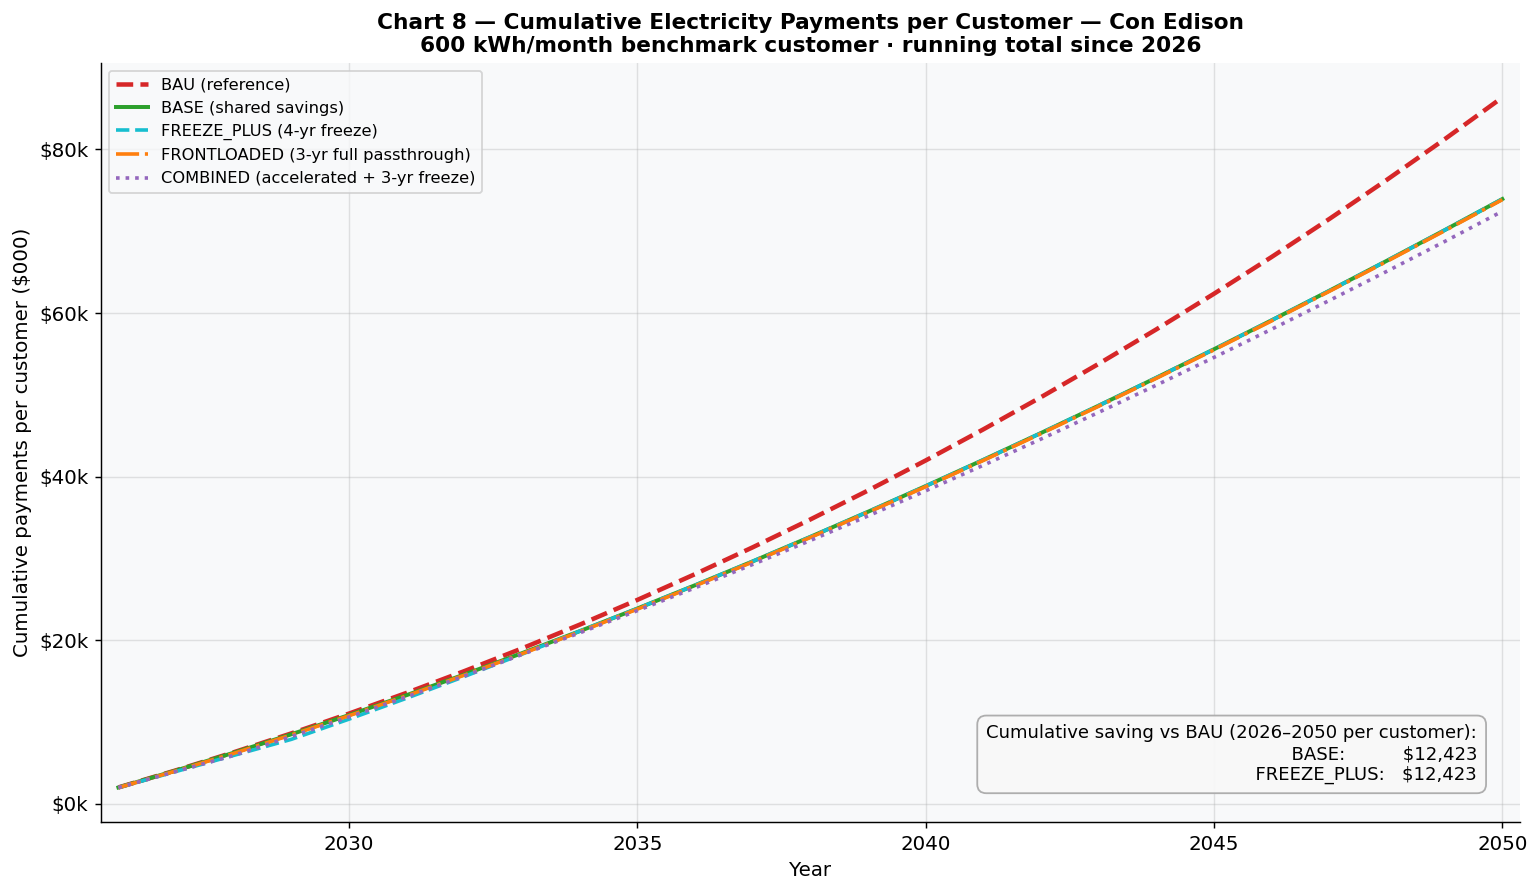

Saved: charts_article/chart9_crossover_coned.png


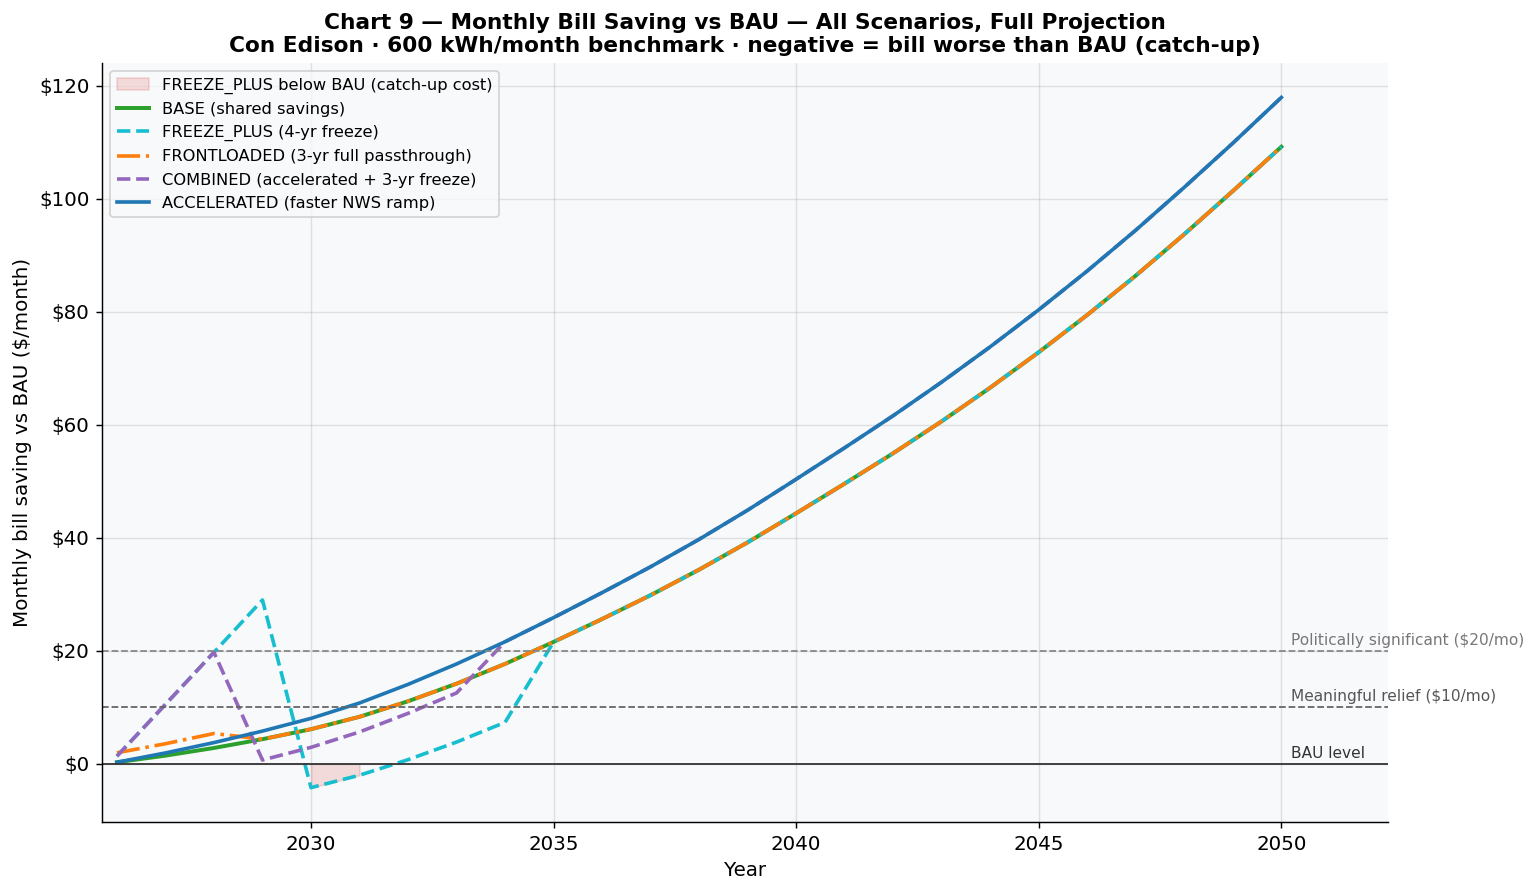

Saved: charts_article/chart10_policy_window_coned.png


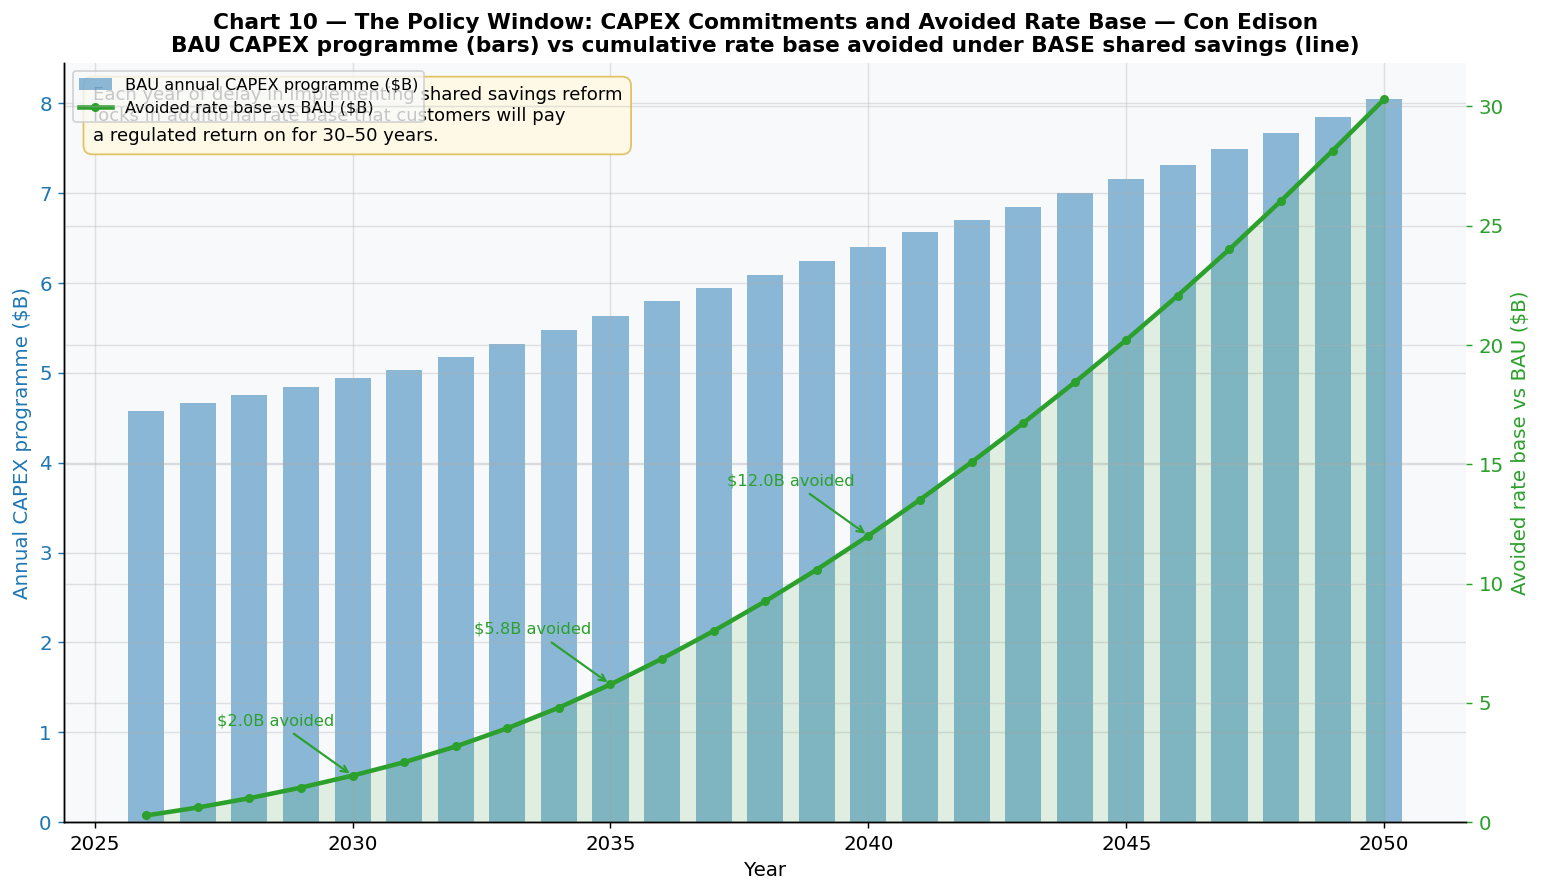

Saved: charts_article/chart11_household_impact_coned.png


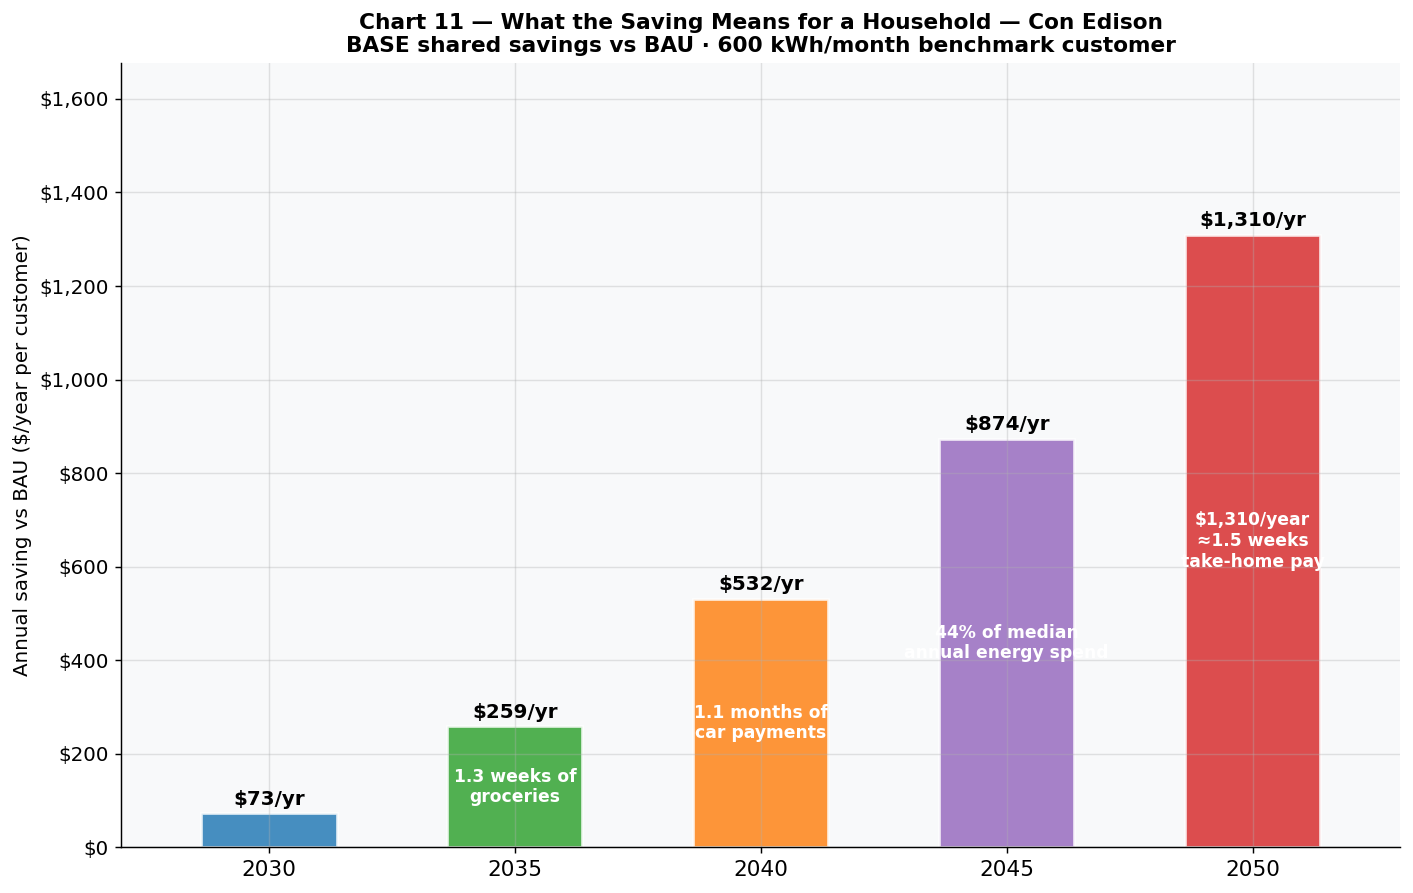


KEY NUMBERS — SECTION 9d

Crossover year (BASE cumulative cost first < FREEZE_PLUS cumulative):
  Does not occur within 2026–2050

Cumulative payments 2026–2050 per customer (600 kWh/month):
  BAU:          $    86,341
  BASE:         $    73,918  (saves $12,423 vs BAU)
  FREEZE_PLUS:  $    73,918  (saves $12,423 vs BAU)

Avoided rate base BASE vs BAU ($B):
  2035: $5.8B
  2050: $30.3B

Annual saving per customer — BASE vs BAU:
  2030: $73/year   ($6/month)
  2035: $259/year   ($22/month)
  2040: $532/year   ($44/month)
  2045: $874/year   ($73/month)
  2050: $1,310/year   ($109/month)


Saved: charts_article/chart12_the_case_for_reform_coned.png


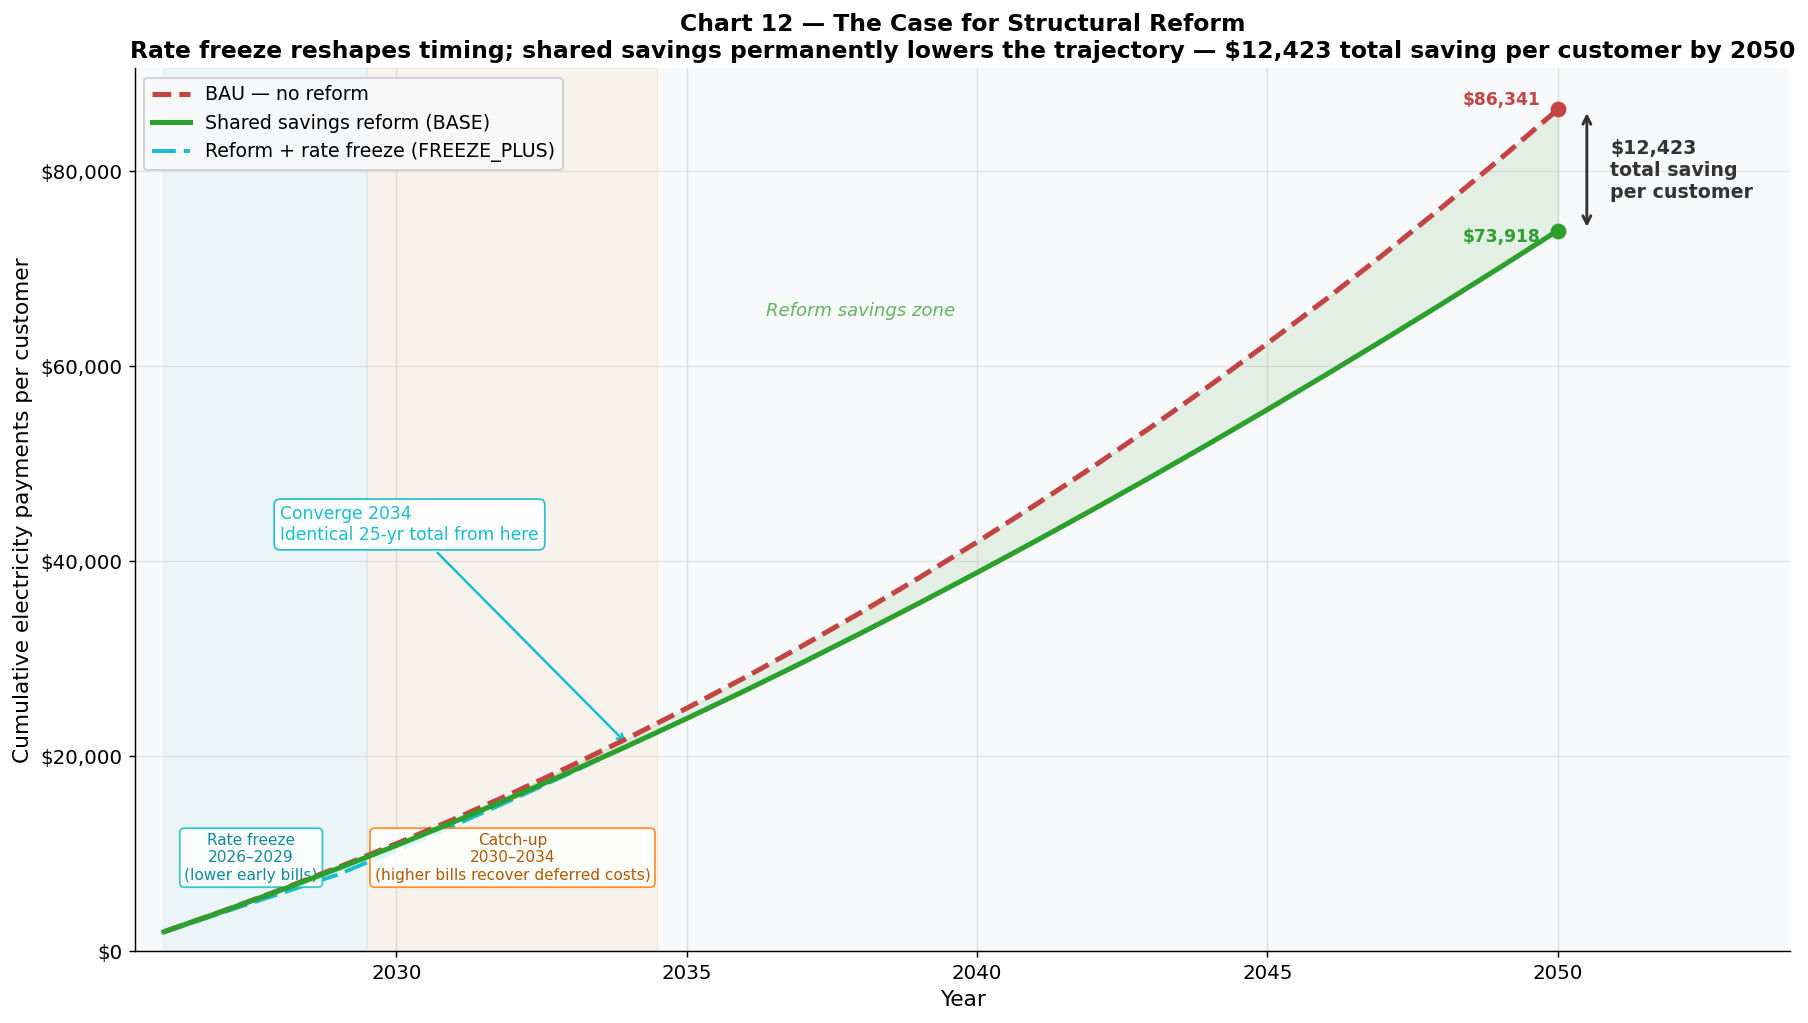

In [21]:
# ============================================================
# SECTION 9d: LONG-TERM CASE — CUMULATIVE COST AND POLICY WINDOW
# Charts 8–11 saved to charts_article/ at 300 dpi.
# ============================================================

import os
os.makedirs('charts_article', exist_ok=True)

k_9d   = utilities_to_run[0]
name_9d = UTILITIES[k_9d]['short_name']
bau_9d  = results[k_9d]['bau']
base_9d = scenario_results[k_9d]['BASE']
frzp_9d = scenario_results[k_9d]['FREEZE_PLUS']
fl_9d   = scenario_results[k_9d]['FRONTLOADED']
comb_9d = scenario_results[k_9d]['COMBINED']
accel_9d = scenario_results[k_9d]['ACCELERATED']

# ── Helpers ───────────────────────────────────────────────────────────────────
def cum_payments_9d(df):
    """Running total paid by a 600 kWh/month customer ($ thousands) since 2026."""
    return np.cumsum(df.sort_values('year')['avg_annual_bill'].values) / 1000

def monthly_saving_9d(sc_df):
    """Monthly saving vs BAU ($/month); NOT floored — can be negative."""
    return [
        float(bau_9d[bau_9d['year'] == yr].iloc[0]['avg_monthly_bill']) -
        float(sc_df[sc_df['year'] == yr].iloc[0]['avg_monthly_bill'])
        for yr in YEARS
    ]

# Pre-compute cumulative series
cum_bau_9d  = cum_payments_9d(bau_9d)
cum_base_9d = cum_payments_9d(base_9d)
cum_frzp_9d = cum_payments_9d(frzp_9d)
cum_fl_9d   = cum_payments_9d(fl_9d)
cum_comb_9d = cum_payments_9d(comb_9d)

# Pre-compute saving series
sav_base_9d  = monthly_saving_9d(base_9d)
sav_frzp_9d  = monthly_saving_9d(frzp_9d)
sav_fl_9d    = monthly_saving_9d(fl_9d)
sav_comb_9d  = monthly_saving_9d(comb_9d)
sav_accel_9d = monthly_saving_9d(accel_9d)

# Find crossover: first year where BASE cumulative cost < FREEZE_PLUS cumulative cost
crossover_9d = None
for _i9d, _yr9d in enumerate(YEARS):
    if cum_base_9d[_i9d] < cum_frzp_9d[_i9d]:
        crossover_9d = _yr9d
        break

# ============================================================
# CHART 8: Cumulative customer payments — Con Edison
# ============================================================
fig8, ax8 = plt.subplots(figsize=(12, 7))

_cum_lines_8 = [
    (cum_bau_9d,  '--', C['bau'],                              2.5, 'BAU (reference)'),
    (cum_base_9d, '-',  SCENARIO_DEFS['BASE']['colour'],       2.2, 'BASE (shared savings)'),
    (cum_frzp_9d, '--', SCENARIO_DEFS['FREEZE_PLUS']['colour'], 2.0, 'FREEZE_PLUS (4-yr freeze)'),
    (cum_fl_9d,   '-.', SCENARIO_DEFS['FRONTLOADED']['colour'], 2.0, 'FRONTLOADED (3-yr full passthrough)'),
    (cum_comb_9d, ':',  SCENARIO_DEFS['COMBINED']['colour'],   2.0, 'COMBINED (accelerated + 3-yr freeze)'),
]
for _vals, _ls, _col, _lw, _lbl in _cum_lines_8:
    ax8.plot(YEARS, _vals, ls=_ls, color=_col, lw=_lw, label=_lbl)

# Vertical crossover line
if crossover_9d is not None:
    _ylo8, _yhi8 = ax8.get_ylim()
    ax8.axvline(crossover_9d, color='#444', ls=':', lw=1.8, alpha=0.8)
    ax8.text(crossover_9d + 0.3, _ylo8 + (_yhi8 - _ylo8) * 0.50,
             f'Shared savings\novertakes freeze\n({crossover_9d})',
             fontsize=9, color='#444', va='center',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#ccc', alpha=0.90))

# Cumulative saving text box (lower right)
_csave_base = (cum_bau_9d[-1] - cum_base_9d[-1]) * 1000
_csave_frzp = (cum_bau_9d[-1] - cum_frzp_9d[-1]) * 1000
ax8.text(0.97, 0.05,
         f'Cumulative saving vs BAU (2026–2050 per customer):\n'
         f'  BASE:          ${_csave_base:,.0f}\n'
         f'  FREEZE_PLUS:   ${_csave_frzp:,.0f}',
         transform=ax8.transAxes, ha='right', va='bottom', fontsize=10,
         bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f8f8', edgecolor='#aaa', alpha=0.95))

ax8.set_xlabel('Year', fontsize=11)
ax8.set_ylabel('Cumulative payments per customer ($000)', fontsize=11)
ax8.set_title(
    f'Chart 8 — Cumulative Electricity Payments per Customer — {name_9d}\n'
    '600 kWh/month benchmark customer · running total since 2026',
    fontsize=12)
ax8.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}k'))
ax8.set_xlim(YEARS[0] - 0.3, YEARS[-1] + 0.3)
ax8.legend(fontsize=9, loc='upper left')
fig8.tight_layout()
fname8 = f'charts_article/chart8_cumulative_{k_9d.lower()}.png'
fig8.savefig(fname8, dpi=300, bbox_inches='tight')
print(f'Saved: {fname8}')
plt.show()

# ============================================================
# CHART 9: Crossover analysis — annual saving vs BAU, all scenarios
# ============================================================
fig9, ax9 = plt.subplots(figsize=(12, 7))

# Shade region where FREEZE_PLUS saving is negative (bills worse than BAU)
_frzp_arr = np.array(sav_frzp_9d)
if np.any(_frzp_arr < 0):
    ax9.fill_between(YEARS, _frzp_arr, 0,
                     where=(_frzp_arr < 0),
                     color='#d62728', alpha=0.15,
                     label='FREEZE_PLUS below BAU (catch-up cost)')

_sav_lines_9 = [
    (sav_base_9d,  '-',   SCENARIO_DEFS['BASE']['colour'],        2.2, 'BASE (shared savings)'),
    (sav_frzp_9d,  '--',  SCENARIO_DEFS['FREEZE_PLUS']['colour'], 2.0, 'FREEZE_PLUS (4-yr freeze)'),
    (sav_fl_9d,    '-.',  SCENARIO_DEFS['FRONTLOADED']['colour'], 2.0, 'FRONTLOADED (3-yr full passthrough)'),
    (sav_comb_9d,  '--',  SCENARIO_DEFS['COMBINED']['colour'],    2.0, 'COMBINED (accelerated + 3-yr freeze)'),
    (sav_accel_9d, '-',   SCENARIO_DEFS['ACCELERATED']['colour'], 2.0, 'ACCELERATED (faster NWS ramp)'),
]
for _vals, _ls, _col, _lw, _lbl in _sav_lines_9:
    ax9.plot(YEARS, _vals, ls=_ls, color=_col, lw=_lw, label=_lbl)

# Reference lines
_yr_end = YEARS[-1]
ax9.axhline(0,  color='#333', ls='-',  lw=1.0)
ax9.axhline(10, color='#666', ls='--', lw=1.0)
ax9.axhline(20, color='#888', ls='--', lw=1.0)
ax9.text(_yr_end + 0.2,  0.5, 'BAU level',                       fontsize=8.5, va='bottom', color='#333')
ax9.text(_yr_end + 0.2, 10.5, 'Meaningful relief ($10/mo)',       fontsize=8.5, va='bottom', color='#555')
ax9.text(_yr_end + 0.2, 20.5, 'Politically significant ($20/mo)', fontsize=8.5, va='bottom', color='#777')

ax9.set_xlabel('Year', fontsize=11)
ax9.set_ylabel('Monthly bill saving vs BAU ($/month)', fontsize=11)
ax9.set_title(
    'Chart 9 — Monthly Bill Saving vs BAU — All Scenarios, Full Projection\n'
    f'{name_9d} · 600 kWh/month benchmark · negative = bill worse than BAU (catch-up)',
    fontsize=12)
ax9.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}'))
ax9.set_xlim(YEARS[0] - 0.3, YEARS[-1] + 2.2)
ax9.legend(fontsize=9, loc='upper left')
fig9.tight_layout()
fname9 = f'charts_article/chart9_crossover_{k_9d.lower()}.png'
fig9.savefig(fname9, dpi=300, bbox_inches='tight')
print(f'Saved: {fname9}')
plt.show()

# ============================================================
# CHART 10: Policy window — rate base commitments
# ============================================================
fig10, ax10a = plt.subplots(figsize=(12, 7))
ax10b = ax10a.twinx()

# Left axis: BAU annual CAPEX programme in $B (bars)
_bau_capex_b = [
    float(bau_9d[bau_9d['year'] == yr].iloc[0]['capex_total_programme_m']) / 1000
    for yr in YEARS
]
ax10a.bar(YEARS, _bau_capex_b, color='#1f77b4', alpha=0.50, width=0.7,
          label='BAU annual CAPEX programme ($B)')

# Right axis: cumulative avoided rate base (rb_bau − rb_base, $B)
_rb_diff_b = [
    (float(bau_9d[bau_9d['year'] == yr].iloc[0]['rate_base_m']) -
     float(base_9d[base_9d['year'] == yr].iloc[0]['rate_base_m'])) / 1000
    for yr in YEARS
]
ax10b.plot(YEARS, _rb_diff_b, color='#2ca02c', lw=2.5, marker='o', ms=4,
           label='Avoided rate base vs BAU ($B)')
ax10b.fill_between(YEARS, 0, _rb_diff_b, color='#2ca02c', alpha=0.12)
ax10b.set_ylim(bottom=0)

# Annotations at 2030, 2035, 2040
for _ann_yr in [2030, 2035, 2040]:
    _ann_i = YEARS.index(_ann_yr)
    _ann_v = _rb_diff_b[_ann_i]
    ax10b.annotate(
        f'${_ann_v:.1f}B avoided',
        xy=(_ann_yr, _ann_v),
        xytext=(_ann_yr - 1.5, _ann_v + max(_rb_diff_b) * 0.07),
        fontsize=9, color='#2ca02c', ha='center',
        arrowprops=dict(arrowstyle='->', color='#2ca02c', lw=1.2))

# Policy window text box
ax10a.text(0.02, 0.97,
           'Each year of delay in implementing shared savings reform\n'
           'locks in additional rate base that customers will pay\n'
           'a regulated return on for 30\u201350 years.',
           transform=ax10a.transAxes, ha='left', va='top', fontsize=10,
           bbox=dict(boxstyle='round,pad=0.5', facecolor='#fff9e6', edgecolor='#e0c060', alpha=0.95))

ax10a.set_xlabel('Year', fontsize=11)
ax10a.set_ylabel('Annual CAPEX programme ($B)', fontsize=11, color='#1f77b4')
ax10b.set_ylabel('Avoided rate base vs BAU ($B)', fontsize=11, color='#2ca02c')
ax10a.tick_params(axis='y', colors='#1f77b4')
ax10b.tick_params(axis='y', colors='#2ca02c')
ax10a.set_title(
    f'Chart 10 — The Policy Window: CAPEX Commitments and Avoided Rate Base — {name_9d}\n'
    'BAU CAPEX programme (bars) vs cumulative rate base avoided under BASE shared savings (line)',
    fontsize=12)
_h10a, _l10a = ax10a.get_legend_handles_labels()
_h10b, _l10b = ax10b.get_legend_handles_labels()
ax10a.legend(_h10a + _h10b, _l10a + _l10b, fontsize=9, loc='upper left')
fig10.tight_layout()
fname10 = f'charts_article/chart10_policy_window_{k_9d.lower()}.png'
fig10.savefig(fname10, dpi=300, bbox_inches='tight')
print(f'Saved: {fname10}')
plt.show()

# ============================================================
# CHART 11: Household budget impact — what the saving buys
# ============================================================
_milestones_11 = [2030, 2035, 2040, 2045, 2050]
_ann_save_11   = {}
_bau_ann_11    = {}
for _yr11 in _milestones_11:
    _b_bau11  = float(bau_9d[bau_9d['year'] == _yr11].iloc[0]['avg_monthly_bill'])
    _b_base11 = float(base_9d[base_9d['year'] == _yr11].iloc[0]['avg_monthly_bill'])
    _ann_save_11[_yr11] = (_b_bau11 - _b_base11) * 12
    _bau_ann_11[_yr11]  = _b_bau11 * 12

_START_BILL   = utility_data[k_9d]['start_monthly_bill']   # $/month starting bill (label only)
_GROCERY_WK   = 200.0    # $/week grocery assumption
_CAR_PMT_MO   = 500.0    # $/month car payment assumption
_ENERGY_BURDEN = 2000.0  # median US household annual electricity spend estimate $/yr
_TAKEHOME_MO  = 3750.0   # $45k net annual / 12 months

def _human_label_11(yr, saving):
    if yr == 2030:
        months = saving / (_START_BILL * 12) * 12
        return f'{months:.1f} months of\nelectricity bills'
    elif yr == 2035:
        weeks = saving / _GROCERY_WK
        return f'{weeks:.1f} weeks of\ngroceries'
    elif yr == 2040:
        mo_car = saving / _CAR_PMT_MO
        return f'{mo_car:.1f} months of\ncar payments'
    elif yr == 2045:
        pct = saving / _ENERGY_BURDEN * 100
        return f'{pct:.0f}% of median\nannual energy spend'
    elif yr == 2050:
        wks_pay = saving / (_TAKEHOME_MO / 4.33)
        return f'${saving:,.0f}/year\n\u2248{wks_pay:.1f} weeks\ntake-home pay'

fig11, ax11 = plt.subplots(figsize=(11, 7))
_bar_colors_11 = ['#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd', '#d62728']
_x11 = np.arange(len(_milestones_11))
_bars11 = ax11.bar(_x11,
                   [_ann_save_11[yr] for yr in _milestones_11],
                   color=_bar_colors_11, alpha=0.82, width=0.55,
                   edgecolor='white', linewidth=1.5)

for _i11, (_yr11, _bar11) in enumerate(zip(_milestones_11, _bars11)):
    _val11 = _ann_save_11[_yr11]
    _lbl11 = _human_label_11(_yr11, _val11)
    # Dollar amount above bar
    ax11.text(_bar11.get_x() + _bar11.get_width() / 2,
              _bar11.get_height() + 10,
              f'${_val11:,.0f}/yr',
              ha='center', va='bottom', fontsize=11, fontweight='bold')
    # Human label inside bar (white text)
    if _val11 > 80:
        ax11.text(_bar11.get_x() + _bar11.get_width() / 2,
                  _bar11.get_height() / 2,
                  _lbl11,
                  ha='center', va='center', fontsize=9.5,
                  color='white', fontweight='bold')

ax11.set_xticks(_x11)
ax11.set_xticklabels([str(yr) for yr in _milestones_11], fontsize=12)
ax11.set_ylabel('Annual saving vs BAU ($/year per customer)', fontsize=11)
ax11.set_title(
    f'Chart 11 — What the Saving Means for a Household — {name_9d}\n'
    'BASE shared savings vs BAU · 600 kWh/month benchmark customer',
    fontsize=12)
ax11.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}'))
ax11.set_ylim(0, max(_ann_save_11.values()) * 1.28)
ax11.set_xlim(-0.6, len(_milestones_11) - 0.4)
fig11.tight_layout()
fname11 = f'charts_article/chart11_household_impact_{k_9d.lower()}.png'
fig11.savefig(fname11, dpi=300, bbox_inches='tight')
print(f'Saved: {fname11}')
plt.show()

# ============================================================
# KEY NUMBERS FOR ARTICLE TEXT
# ============================================================
print()
print('=' * 65)
print('KEY NUMBERS — SECTION 9d')
print('=' * 65)

print(f'\nCrossover year (BASE cumulative cost first < FREEZE_PLUS cumulative):')
print(f'  {crossover_9d if crossover_9d else "Does not occur within 2026–2050"}')

print(f'\nCumulative payments 2026–2050 per customer (600 kWh/month):')
print(f'  BAU:          ${cum_bau_9d[-1]*1000:>10,.0f}')
print(f'  BASE:         ${cum_base_9d[-1]*1000:>10,.0f}  (saves ${(cum_bau_9d[-1]-cum_base_9d[-1])*1000:,.0f} vs BAU)')
print(f'  FREEZE_PLUS:  ${cum_frzp_9d[-1]*1000:>10,.0f}  (saves ${(cum_bau_9d[-1]-cum_frzp_9d[-1])*1000:,.0f} vs BAU)')

print(f'\nAvoided rate base BASE vs BAU ($B):')
_idx35 = YEARS.index(2035); _idx50 = YEARS.index(2050)
print(f'  2035: ${_rb_diff_b[_idx35]:.1f}B')
print(f'  2050: ${_rb_diff_b[_idx50]:.1f}B')

print(f'\nAnnual saving per customer — BASE vs BAU:')
for _yr11 in _milestones_11:
    _s = _ann_save_11[_yr11]
    print(f'  {_yr11}: ${_s:,.0f}/year   (${_s/12:.0f}/month)')

# ============================================================
# CHART 12: THE CASE FOR REFORM — headline chart
# Three cumulative payment lines 2026-2050.
# ============================================================
_conv_yr_12 = None
for _i12, _yr12 in enumerate(YEARS):
    if abs(cum_base_9d[_i12] - cum_frzp_9d[_i12]) < 0.001:
        _conv_yr_12 = _yr12
        break

cum_saving_12 = int(round(
    (bau_9d['avg_annual_bill'].values - base_9d['avg_annual_bill'].values).sum()
))

fig12, ax12 = plt.subplots(figsize=(14, 8))

# ── Fill the reform savings zone (between BAU and BASE) ─────────────────────
ax12.fill_between(YEARS, cum_bau_9d, cum_base_9d,
                  color='#2ca02c', alpha=0.10, zorder=1)

# ── Shade freeze period and catch-up period ──────────────────────────────────
# Same timing as run_named_scenario(): freeze 2026 to freeze_end - 1, catch-up freeze_end to catchup_end
_fz_yrs = SC['FREEZE_PLUS']['params'].get('RATE_FREEZE_YEARS', RATE_FREEZE_YEARS)
_fz_end = 2026 + _fz_yrs
_cu_end = _fz_end + RATE_FREEZE_RECOVERY_YEARS
ax12.axvspan(2026, _fz_end - 0.5, alpha=0.055, color='#17becf', zorder=1,
             label='_nolegend_')
ax12.axvspan(_fz_end - 0.5, _cu_end + 0.5, alpha=0.055, color='#ff7f0e', zorder=1,
             label='_nolegend_')

# ── Three lines ───────────────────────────────────────────────────────────────
ax12.plot(YEARS, cum_bau_9d,
          color='#c44444', ls='--', lw=2.8, zorder=4,
          label='BAU — no reform')
ax12.plot(YEARS, cum_base_9d,
          color='#2ca02c', ls='-', lw=2.8, zorder=5,
          label='Shared savings reform (BASE)')
ax12.plot(YEARS, cum_frzp_9d,
          color='#17becf', ls=(0, (6, 2)), lw=2.2, zorder=3,
          label='Reform + rate freeze (FREEZE_PLUS)')

# ── Mark convergence ─────────────────────────────────────────────────────────
if _conv_yr_12:
    _cv_i = YEARS.index(_conv_yr_12)
    _cv_y = cum_base_9d[_cv_i]
    ax12.annotate(
        f'Converge {_conv_yr_12}\nIdentical 25-yr total from here',
        xy=(_conv_yr_12, _cv_y),
        xytext=(_conv_yr_12 - 6.0, _cv_y * 2.0),
        fontsize=9.5, color='#17becf',
        arrowprops=dict(arrowstyle='->', color='#17becf', lw=1.4),
        bbox=dict(boxstyle='round,pad=0.35', facecolor='white',
                  edgecolor='#17becf', alpha=0.92))

# ── Total saving bracket at right edge ───────────────────────────────────────
_y_bau50  = cum_bau_9d[-1]
_y_base50 = cum_base_9d[-1]
_x_ann    = YEARS[-1] + 0.5

ax12.annotate('', xy=(_x_ann, _y_base50), xytext=(_x_ann, _y_bau50),
              arrowprops=dict(arrowstyle='<->', color='#333', lw=1.6))
ax12.text(_x_ann + 0.4, (_y_bau50 + _y_base50) / 2,
          f'${cum_saving_12:,}\ntotal saving\nper customer',
          fontsize=10.5, color='#333', va='center', fontweight='bold')

# ── Endpoint dots ─────────────────────────────────────────────────────────────
ax12.scatter([2050], [_y_bau50],  color='#c44444', s=60, zorder=6)
ax12.scatter([2050], [_y_base50], color='#2ca02c', s=60, zorder=6)

_bau50_k  = _y_bau50 * 1000
_base50_k = _y_base50 * 1000
ax12.text(YEARS[-1] - 0.3, _y_bau50  + 0.5, f'${_bau50_k:,.0f}',
          ha='right', fontsize=9.5, color='#c44444', fontweight='bold')
ax12.text(YEARS[-1] - 0.3, _y_base50 - 1.2, f'${_base50_k:,.0f}',
          ha='right', fontsize=9.5, color='#2ca02c', fontweight='bold')

# ── Period annotations ────────────────────────────────────────────────────────
_ylo12, _yhi12 = ax12.get_ylim()
_ann_y = _ylo12 + (_yhi12 - _ylo12) * 0.10
ax12.text((2026 + _fz_end - 1) / 2, _ann_y,
          f'Rate freeze\n2026–{_fz_end - 1}\n(lower early bills)',
          ha='center', va='bottom', fontsize=8.5, color='#0e8a9e',
          bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                    edgecolor='#17becf', alpha=0.85))
ax12.text((_fz_end + _cu_end) / 2, _ann_y,
          f'Catch-up\n{_fz_end}–{_cu_end}\n(higher bills recover deferred costs)',
          ha='center', va='bottom', fontsize=8.5, color='#b05a00',
          bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                    edgecolor='#ff7f0e', alpha=0.85))

# ── Reform zone label ─────────────────────────────────────────────────────────
ax12.text(2038, (_y_bau50 + _y_base50) / 2 * 0.82,
          'Reform savings zone',
          ha='center', va='center', fontsize=10, color='#2ca02c',
          style='italic', alpha=0.75)

# ── Axes ─────────────────────────────────────────────────────────────────────
ax12.set_xlabel('Year', fontsize=12)
ax12.set_ylabel('Cumulative electricity payments per customer', fontsize=12)
ax12.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v, _: f'${v*1000:,.0f}'))
ax12.set_xlim(YEARS[0] - 0.5, YEARS[-1] + 4.0)
ax12.set_ylim(bottom=0)

ax12.set_title(
    'Chart 12 — The Case for Structural Reform\n'
    'Rate freeze reshapes timing; shared savings permanently lowers the trajectory — '
    f'${cum_saving_12:,} total saving per customer by 2050',
    fontsize=13, fontweight='bold')

ax12.legend(fontsize=10.5, loc='upper left',
            framealpha=0.95, edgecolor='#ccc')
ax12.grid(axis='y', alpha=0.25, lw=0.8)

fig12.tight_layout()
fname12 = f'charts_article/chart12_the_case_for_reform_{k_9d.lower()}.png'
fig12.savefig(fname12, dpi=300, bbox_inches='tight')
print(f'Saved: {fname12}')
plt.show()

## Section 10: Model Caveats

### Primary Scope Statement

*These caveats describe the earlier model (Sections 1-12). The layered model's method and limitations (Section 13) are in [`docs/METHODOLOGY.md`](../docs/METHODOLOGY.md).*

GridDividend is a **strategic policy simulation framework** demonstrating the direction and order of magnitude of the shared savings opportunity. It is not a utility planning model, a rate case replica, or a forecast. The following limitations should be understood before interpreting any result.

### The Three Most Important Limitations

**A. The model is spatially aggregate — this is its most fundamental constraint.**

Real distribution systems are constrained *networks*, not pools of interchangeable capacity. A battery in one neighbourhood cannot relieve a thermal overload in another. NWS effectiveness depends critically on whether the DER is located at or near the constrained feeder, whether its dispatch window coincides with the overload interval, and what type of constraint it is — thermal, voltage, fault current, or protection coordination. The model represents NWS as a system-wide percentage of eligible CAPEX, which is a necessary simplification but one that could materially overstate NWS effectiveness in spatially concentrated or constraint-type-specific portions of the CAPEX programme. Individual feeders will see outcomes ranging from zero NWS benefit (fault-current-driven, asset-condition-driven, or geographically isolated upgrades) to near-complete NWS deferral (growth-driven, thermally constrained, demand-coincident feeders with local DER). The system average used in this model does not predict outcomes at the project level. State-level analysis should obtain the utility's CAPEX programme by constraint type and location and apply NWS eligibility and avoidance rates at that level.

**B. The model tracks the full tariff bill but not all bill drivers.**

The bill figures include both delivery (distribution infrastructure) and supply (energy and NYISO capacity costs), and the reform affects both: delivery falls as infrastructure investment is avoided; supply falls modestly as lower peak demand reduces NYISO capacity market obligations. What the model does not project are independent movements in wholesale energy prices, transmission investment costs, or policy surcharges — these grow with load at their starting trajectory and are unaffected by the shared savings reform. Readers should interpret the savings figures as what a distribution utility under shared savings incentives can influence, not as a projection of total electricity bill movements.

**C. The 80% mature avoidance rate is a programme-level average, not a guarantee.**

The `NWS_AVOIDANCE_OF_ELIGIBLE_MATURE` parameter (default 80%) represents what a well-run, mature NWS programme could achieve across a diverse portfolio of eligible upgrades. It is supported by the Brattle Ontario analysis (NWS cost-effective in 95% of feeder scenarios) and UK DSO flexibility market outcomes. However, it assumes geographic diversity — that the programme spans many feeder types, constraint categories, and seasons so that high avoidance on some projects compensates for low avoidance on others. For any individual feeder or project, the achievable avoidance could be anywhere from zero to 100%. The UK reference should also be used carefully: UK feeders, planning criteria, and market design differ materially from US distribution systems, and demonstrated UK outcomes cannot be imported directly. Applying this parameter to a single constrained corridor or a narrow CAPEX category would likely overstate achievable avoidance significantly.

### Additional Caveats

**1. Time value of money.** Cumulative savings in Sections 4-9 are undiscounted nominal sums. Near-term deferrals are worth more in present value than late deferrals (Brattle Ontario). Section 8b and Section 13 also report NPVs (3% and 7%, base year 2026), which are lower but tell the same directional story.

**2. DERMS and programme administration costs.** Not separately tracked. Both GridDividend and the Brattle Ontario analysis omit these. Both analyses therefore slightly overstate net NWS benefits. The operational question is addressed in the companion piece on distribution system operations.

**3. Gas operations** not modelled. Both utilities have large gas distribution businesses interacting with electrification in complex ways.

**4. Full revenue requirement disaggregation** not attempted. Pension costs, storm recovery, environmental remediation, and depreciation schedules are simplified.

**5. NYISO market dynamics** represented by a simple pass-through savings rate. Full capacity market modelling is future work, particularly for application to other regions.

**6. CIAC dynamics** not modelled. Under current regulation, utilities have a financial incentive to specify infrastructure solutions funded by ratepayers — which add to rate base and earn a regulated return — over flexible interconnection alternatives. Developer-funded CIAC contributions reduce rate base under FERC accounting but do not change this fundamental bias toward hardware. The model assumes the full CAPEX programme is utility-funded and rate-base-eligible, slightly overstating BAU bills. Both scenarios are therefore slightly mis-stated in the same direction; savings estimates may be modestly overstated. A future version should add a `developer_funded_capex_fraction` parameter.

**7. Individual customer class impacts** estimated from revenue share proxies, not actual tariff structures. Low-income customers not separately tracked.

**8. RG&E data uncertainty.** Case 25-E-0379 was filed June 2025. The PSC set temporary rates effective June 1, 2026 (+4.0% electric). The final order has not yet been issued as of May 2026. All RG&E parameters are estimates from the June 2025 filing.

**9. Regulatory gaming** not modelled. The model assumes honest accounting.

**10. Utilisation credit scope.** The 15% default is conservative relative to Brattle's Untapped Grid base case (~33%), appropriate because GridDividend models distribution scope only.

**11. Parameter correlation and probabilistic uncertainty.** The sensitivity analysis varies parameters one at a time. In practice many are correlated — high electrification growth increases NWS opportunity but also increases operational complexity; higher DER penetration is both a driver of flexibility and a source of dispatch uncertainty. These correlations mean outputs represent one deterministic path through a wide distribution of plausible outcomes. The directional conclusion is robust; the specific 2050 magnitudes are not.

---

## Future Work (Part Nine of companion article)

Key extensions prioritised for future versions:

**Model refinement:** Discounted cash flow analysis · Revenue requirement disaggregation · NYISO capacity market modelling · DERMS cost parameter · CIAC/flexible interconnection dynamics

**Usability:** Graphical parameter interface (Jupyter widgets) · Scenario comparison table · Low-income customer tracking · Gas interaction module

**Other regulatory environments:** Multi-state parameterisation · Vertically integrated utility variant · UK/Australian DSO variant

**Removing fat from customer bills:** Energy efficiency as bill reduction (not surcharge) · Demand response programme unbundling · Interconnection cost reduction for DER developers

**Operational frontier:** Companion piece in preparation on DER management for grid reliability — pre-fault positioning, contingency response, post-fault restoration, protection coordination.

**Legislative design:** A well-designed shared savings statute prioritises the utility's commercial position: annual recognition of shared savings income (no rate case needed to capture what was earned); ring-fencing of that income from rate case compression; and streamlined contract approval to reduce administrative burden on NWS programmes. These protections make the reform commercially attractive to utilities, not just to customers.

---

## References and Further Reading

- Currie, R.A.F. (2025). *Electric Utility Reform in an Age of Electrification.* The States Forum. https://www.statesforum.org/electric-utility-reform-in-an-age-of-electrification/
- Hledik, R., Lam, L., and Peters, K. (2026). *The Untapped Grid: How Better Utilization of the Power System Can Improve Energy Affordability.* The Brattle Group, prepared for GridLab and Utilize Coalition.
- Sergici, S., Ramakrishnan, A., Graham, K., Hledik, R., Grocott, O., and McAdam, C. (2026). *The Value of Using DERs for Distribution System Services in Ontario.* The Brattle Group, prepared for Clean Energy Canada. https://cleanenergycanada.org/wp-content/uploads/2026/04/Distribution-Value-of-DERs-in-Ontario-Final-1.pdf
- NYPSC Case 25-E-0072: Con Edison Electric Rate Case (approved January 2026)
- NYPSC Case 25-E-0379: RG&E Electric Rate Case (filed June 2025; PSC set temporary rates June 1, 2026 at +4.0% electric; final order pending as of May 2026)
- NY CLCPA (2019): Climate Leadership and Community Protection Act, Chapter 106 of the Laws of 2019
- IRS Notice 2016-36: Safe harbor for transfers of interconnection equipment to regulated public utilities
- UKPN DSO (2025). *DSO Performance Panel Report 2024/25.* UK Power Networks. https://dso.ukpowernetworks.co.uk/
- Blake Clough Consulting (2025). *DSO Flexibility Markets: Transforming GB's Grid Economics.* https://www.blakeclough.com/dso-flexibility-markets-transforming-gbs-grid-economics/

---
*GridDividend is open source (MIT License). github.com/robertafcurrie/GridDividend*  
*The author welcomes corrections, contributions, and extensions. If you improve a parameter, add a utility, or find a better data source, please open a pull request.*

**12. Accelerated scenario assumptions.** The ACCELERATED and COMBINED scenarios in Section 1b assume the utility has existing NWS infrastructure, active DER aggregator relationships, and demonstrated programme delivery capability before the shared savings reform takes effect. These preconditions are a legislative design choice — not a modelling assumption that can be applied unconditionally. In jurisdictions without mature NWS programmes, the accelerated ramp parameters (35% starting avoidance, 6-year ramp to maturity) would likely overstate early-year savings. Any application of the accelerated scenarios should be validated against the utility's actual DER programme status, aggregator market depth, and demonstrated dispatch performance before use in policy analysis.

**13. Permanent avoidance vs temporary deferral.** The model assumes all NWS avoidance is permanent — avoided CAPEX never enters the rate base. In practice, a significant share of NWS outcomes are temporary deferrals: the constraint returns as load eventually outgrows NWS capacity and the deferred asset must be built. For dense urban networks like Con Edison, where electrification and data centre load will continue to grow, a deferral fraction of 40–60% may be more realistic long-term than the current assumption of zero. The `DEFERRAL_FRACTION` and `DEFERRAL_PERIOD_YEARS` parameters in Section 1 allow this to be explored. A further statutory design question arises: if the utility earns shared savings income during a deferral window and the deferred asset is eventually built and added to rate base, have customers paid twice? Whether this requires a clawback provision in  the shared savings statute is identified as priority legislative design work.

**14. No real grid-utilization data (earlier model).** In Sections 1-12, NWS-eligible CAPEX share and avoidance rates are system-wide estimates calibrated from rate-case filings and industry benchmarks (Brattle, UKPN), not measured from actual utility grid-utilization data — feeder-level hosting capacity, loading, or constraint maps. Where a utility publishes real grid-utilization data, it should replace these assumptions; until then, results should be read as illustrative of the shared-savings mechanism's mechanics, not as a claim about where on a specific utility's network NWS is actually viable. The layered model (Section 13) uses Dominion's grid utilization filing (SCC PUR-2026-00164) for its loading bands, as a proxy for the other utilities.

## Section 11: Summary Report

Generates a single-scenario HTML summary report per utility (never a cross-scenario comparison) for each key in `REPORT_SCENARIOS`, reusing the Section 5 bill chart. HTML only — see `engine/report.py`.

In [22]:
if GENERATE_SUMMARY_REPORT:
    from datetime import datetime, timezone
    from engine import compute_insights, render_report_html
    from engine.report import render_layered_section

    os.makedirs('../reports', exist_ok=True)  # top-level, sibling of notebooks/
    try:
        git_sha = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'],
                                  capture_output=True, text=True, cwd='..',
                                  timeout=5).stdout.strip() or None
    except Exception:
        git_sha = None
    generated_at = datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')

    # Report prose calls the shared-savings scenario "EASE Case" regardless of
    # which SCENARIO_DEFS key drives it; BAU is always the counterfactual.
    REPORT_LABEL_OVERRIDES = {'BASE': 'EASE Case'}

    for k in utilities_to_run:
        layered_html = render_layered_section(k, UTILITIES[k], utility_data[k])
        for sname in REPORT_SCENARIOS:
            sdef = SCENARIO_DEFS[sname]
            scenario_label = REPORT_LABEL_OVERRIDES.get(sname, sdef['label'])
            bau_df = results[k]['bau']
            scenario_df = scenario_results[k][sname]
            bau_freeze_df = results[k]['bau_freeze']
            scenario_freeze_df = results[k]['shared_freeze']
            chart_png = f'charts/chart1_bills_{k.lower()}.png'
            insights = compute_insights(bau_df, scenario_df, scenario_label, YEARS,
                                         bau_freeze_df=bau_freeze_df,
                                         scenario_freeze_df=scenario_freeze_df)
            html = render_report_html(k, UTILITIES[k], utility_data[k], scenario_label,
                                       YEARS, bau_df, scenario_df, insights, chart_png,
                                       generated_at, git_sha, model_config=MODEL_CONFIG,
                                       bau_freeze_df=bau_freeze_df,
                                       scenario_freeze_df=scenario_freeze_df,
                                       layered_html=layered_html)
            base = f'../reports/{k}_{sname}_{YEARS[0]}-{YEARS[-1]}'
            with open(f'{base}.html', 'w') as f:
                f.write(html)
            print(f"  {UTILITIES[k]['short_name']} / {sname}: wrote {base}.html")

  Con Edison / BASE: wrote ../reports/ConEd_BASE_2026-2050.html


  RG&E / BASE: wrote ../reports/RGE_BASE_2026-2050.html


## Section 13: Layered Bill Projection

The current model (`engine/layers.py`; full method in [`docs/METHODOLOGY.md`](../docs/METHODOLOGY.md), every input in [`docs/ASSUMPTIONS.md`](../docs/ASSUMPTIONS.md)). It is independent of Sections 1-12.

**How it works.**
- It starts from today's residential bill, line by line (`starting_bill` in each utility JSON).
- It projects each bill category 2026-2050 under BAU and under shared savings.
- The difference is built from switchable layers, in waterfall order:
  - programs as core business (surcharges leave the bill; spend = incremental flexible MW x cost per kW-year, plus energy efficiency);
  - deferral;
  - load enabled;
  - capacity;
  - wholesale energy (flexible load shifted to off-peak hours);
  - avoided transmission;
  - avoided distribution losses;
  - the shared savings mechanism;
  - an ROE lever (allowed ROE vs BAU, outside the pool).

  System needs (load growth, peak, capex split) applies to both cases.
- The utility's share of the savings pool is its **shared savings earnings**. Customers keep the rest.
- Values, sources and the Cautious / Central / Ambitious scenarios are in the JSON `forward_assumptions`.

**BAU basis.** BAU follows each utility's published distribution capital plan (`bau_plan` in the JSON; sources in [`docs/ASSUMPTIONS.md`](../docs/ASSUMPTIONS.md)).
- After the plan horizon, capex growth tapers to load growth by 2035; continuing the plan's growth rate or high electrification are the alternatives.
- Plan capex is split into growth, replacement, grid modernisation / resilience and other, each with an addressable share.
- Shared savings defers the growth-driven part as far as the network model finds deferrable, and right-sizes replacements and some grid modernisation.
- Transmission follows its own plan where it is a separate bill line.
- Set `bau_plan.basis` to `'model'` for the earlier, network-model BAU.

**The network.**
- Network capacity is explicit, in loading bands. Firm capacity grows only through reinforcement (lead time, maximum build rate), and load above capacity waits for the upgrade.
- A constrained sub-band (load above the planning limit, from Dominion PUR-2026-00164; a proxy elsewhere) is on in every scenario. There, the backlog is cleared at a set share a year, and new load waits the **Upgrade Delay for Interconnection**: the time a new customer in a constrained area waits for the grid upgrade before connecting (ordinary and large loads). The delay is measured per request year.
- Flexible headroom (firm flexible MW x locational match, plus flexible large-load connections) has one use per MW. It connects waiting load sooner (**load enabled**) where BAU leaves load waiting; otherwise it goes to **deferral** of reinforcement.
- Set any network input for a what-if in `NETWORK_OVERRIDES` at the top of the cell below. It overrides the scenario and JSON values for every run in this section and in the report.

**Outputs, Central unless stated.**
- Bills by category: the **average residential bill** (headline; efficiency lowers usage) and the benchmark-usage bill.
- Scenarios.
- Waterfall by layer.
- System-wide results and each layer's contribution to customer savings, bills and shared savings earnings (3b), with the ROE lever.
- Network capacity, MW by resource type, loading bands, access benefits (reported apart from the bill) and MW paths vs ramp limits (4a-4e).
- The constrained sub-band and the Upgrade Delay table (4f).
- The headroom sweep (4g).
- The value stack and the cost at which flexibility pays for itself.
- The tornado on the saving.
- Cumulative savings: undiscounted nominal, and NPV at 3% and 7% in 2026 $.
- Utility earnings.

Results are ranges across scenarios, not forecasts.


Con Edison: layered projection, Central scenario ($/month nominal per residential customer)
  Today's core-business program spend: $611.1M/yr (vder_cost_recovery: 94.5 (derived: rate x total sales); sbc_company_nonlmi_eebe: 239.4 (derived: rate x total sales); sbc_company_lmi_eebe: 6.3 (derived: rate x total sales); dlm: 144.9 (derived: rate x total sales); ev_make_ready: 126.0 (derived: rate x total sales)); residential allocation factor 1.00

AVERAGE residential bill (usage lowered by EE), by category ($/month nominal):


,,Distribution base,Distribution riders,Programs,Supply energy,Capacity,Transmission,Taxes and fees,total
year,case,,,,,,,,
2026,BAU,122.28,-1.46,11.97,45.38,28.69,0.0,8.16,215.01
2030,BAU,188.23,-2.25,13.21,50.09,31.72,0.0,11.56,292.56
2035,BAU,285.44,-3.41,14.94,56.67,35.95,0.0,16.56,406.16
2050,BAU,600.78,-7.17,21.64,82.08,52.32,0.0,32.98,782.63
2026,Shared savings,122.28,-1.46,11.97,45.38,28.69,0.0,8.16,215.01
2030,Shared savings,186.94,-2.23,13.98,49.26,30.04,0.0,11.48,289.46
2035,Shared savings,271.19,-3.21,18.50,54.28,31.76,0.0,15.89,388.41
2050,Shared savings,474.07,-5.60,42.13,77.29,42.11,0.0,27.54,657.54



benchmark-usage bill (600 kWh/month), by category ($/month nominal):


,,Distribution base,Distribution riders,Programs,Supply energy,Capacity,Transmission,Taxes and fees,total
year,case,,,,,,,,
2026,BAU,122.28,-1.46,11.97,45.38,28.69,0.0,8.16,215.01
2030,BAU,188.23,-2.25,13.21,50.09,31.72,0.0,11.56,292.56
2035,BAU,285.44,-3.41,14.94,56.67,35.95,0.0,16.56,406.16
2050,BAU,600.78,-7.17,21.64,82.08,52.32,0.0,32.98,782.63
2026,Shared savings,122.28,-1.46,11.97,45.38,28.69,0.0,8.16,215.01
2030,Shared savings,189.26,-2.26,14.19,50.00,30.49,0.0,11.63,293.31
2035,Shared savings,280.10,-3.34,19.24,56.44,33.02,0.0,16.43,401.90
2050,Shared savings,495.45,-5.91,44.44,81.54,44.43,0.0,28.83,688.77


Scenarios (average residential bill; cumulative saving per residential customer 2026-2050):


,BAU 2026,Shared savings 2026,BAU 2035,Shared savings 2035,BAU 2050,Shared savings 2050,"cum saving, undiscounted nominal $","cum saving, NPV 3% (2026 $)","cum saving, NPV 7% (2026 $)"
scenario,,,,,,,,,
Cautious,215.0,215.0,406.2,401.0,782.6,751.0,3630.0,2146.0,1125.1
Central,215.0,215.0,406.2,388.4,782.6,657.5,13706.8,8062.8,4196.9
Ambitious,215.0,215.0,406.2,376.3,782.6,573.6,22505.3,13219.9,6871.2


Waterfall, BAU to shared-savings AVERAGE residential bill ($/month nominal, Central; system needs applies to both cases so its bar is zero):


,BAU,System needs,Programs as core business,Deferral,Load enabled (bill effect only),Capacity,Wholesale energy (load shifting),Avoided transmission,Avoided distribution losses,Shared savings earnings,ROE lever,Shared savings
2026,215.01,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,215.01
2030,292.56,0.0,0.25,-1.15,-0.03,-1.53,-0.07,-0.63,-0.21,0.29,0.0,289.46
2035,406.16,0.0,1.49,-16.00,0.82,-3.81,-0.18,-1.58,-0.53,2.05,0.0,388.41
2050,782.63,0.0,7.00,-134.31,0.99,-9.28,-0.43,-3.85,-1.27,16.06,0.0,657.54


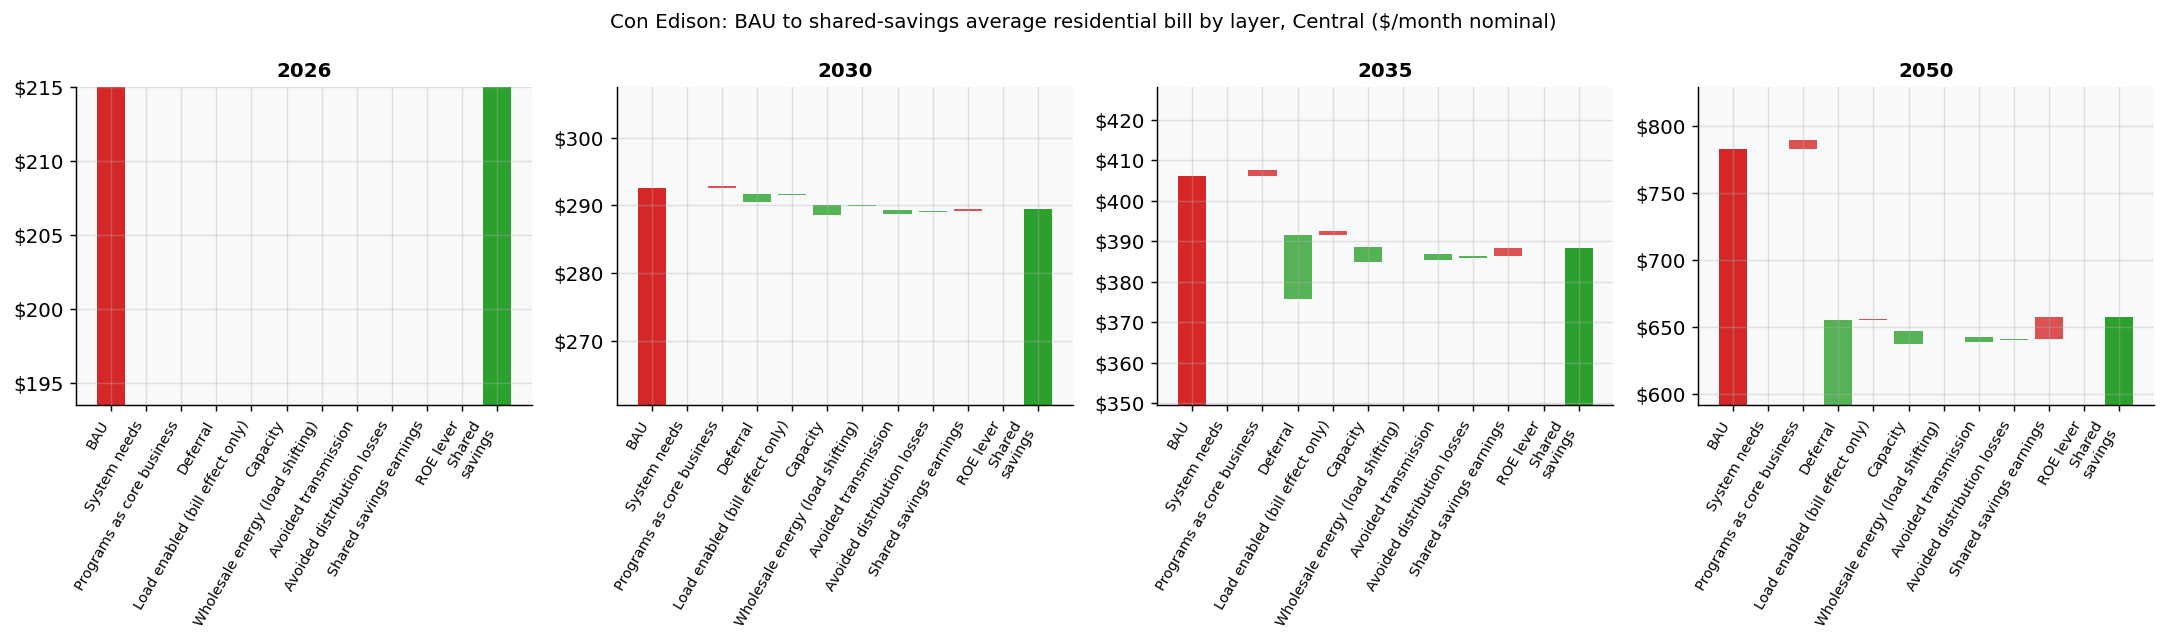

System-wide results, Central (BAU minus shared savings, all customers; $B undiscounted nominal unless marked):


,Central
"Customer savings ($B, undiscounted nominal)",49.46
"Customer savings ($B, NPV 3%, 2026 $)",29.10
"of which efficiency energy ($B, undiscounted nominal)",7.95
"of which wholesale energy, load shifted ($B, undiscounted nominal)",0.68
"of which avoided transmission ($B, undiscounted nominal)",2.34
"of which avoided distribution losses ($B, undiscounted nominal)",1.05
"of which ROE change, cost to customers ($B, undiscounted nominal)",-0.00
"Wires capex avoided or deferred ($B, undiscounted nominal)",69.74
"Wires capex avoided or deferred ($B, NPV 3%, 2026 $)",42.61
Reinforcement deferred (MW),885.02


Contribution by layer, Central (added in waterfall order; earnings attributable computed with the mechanism on):


,"Customer savings ($B, undiscounted nominal)","Customer savings ($B, NPV 3%, 2026 $)","Monthly bill 2035 ($, nominal)","Monthly bill 2050 ($, nominal)","Shared savings earnings ($B, undiscounted nominal)","Shared savings earnings ($B, NPV 3%, 2026 $)","Utility equity return ($B, undiscounted nominal)","Savings pool contribution ($B, undiscounted nominal)","Savings pool contribution ($B, NPV 3%, 2026 $)","Shared savings earnings attributable ($B, undiscounted nominal)","Shared savings earnings attributable ($B, NPV 3%, 2026 $)"
layer,,,,,,,,,,,
Programs as core business,-0.817,-0.369,1.490,7.001,0.000,0.000,0.854,-8.770,-5.348,-2.631,-1.604
Deferral,58.166,33.679,-16.001,-134.308,0.000,0.000,-21.477,58.166,33.679,17.450,10.104
Load enabled (bill effect only),-1.060,-0.668,0.815,0.988,0.000,0.000,0.383,-1.060,-0.668,-0.318,-0.200
Capacity,6.897,4.278,-3.812,-9.277,0.000,0.000,0.000,6.897,4.278,2.069,1.283
Wholesale energy (load shifting),0.677,0.420,-0.178,-0.435,0.000,0.000,0.000,0.677,0.420,0.203,0.126
Avoided transmission,2.338,1.450,-1.579,-3.853,0.000,0.000,0.000,2.338,1.450,0.701,0.435
Avoided distribution losses,1.046,0.650,-0.532,-1.273,0.000,0.000,0.000,1.046,0.650,0.314,0.195
Shared savings earnings,-17.788,-10.338,2.049,16.062,17.788,10.338,0.000,0.000,0.000,0.000,0.000
ROE lever,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


ROE lever (Central = no change; outside the shared-savings pool):
  roe_delta -60 bp: customer savings $57.43B; 2050 monthly saving $135.86; SS equity return $120.44B vs BAU $148.65B
  roe_delta +60 bp: customer savings $41.49B; 2050 monthly saving $114.32; SS equity return $136.38B vs BAU $148.65B
Network capacity, Central network and Tight network (low headroom, long lead time, low build rate):
  Central network, Cautious:


,BAU MW waiting for upgrade,SS MW waiting for upgrade,MW connected sooner (SS),"BAU Upgrade Delay for Interconnection (yr, load requested that year)","SS Upgrade Delay for Interconnection (yr, load requested that year)",BAU GWh not served on time,SS GWh not served on time,Effective capacity uplift %,Headroom created MW,to load enabled MW,to deferral MW,Reinforcement deferred MW (cum.)
year,,,,,,,,,,,,
2035,10.28,8.48,0.0,1.3,1.17,54.77,45.21,0.0,32.17,0.69,31.48,52.11
2050,0.00,0.00,0.0,0.0,0.00,0.00,0.00,0.0,64.34,0.00,64.34,187.28


... (30 outputs left out)

  Customer savings ($B, undiscounted nominal): 49.46; Customer savings ($B, NPV 3%, 2026 $): 29.10; of which efficiency energy ($B, undiscounted nominal): 7.95; of which wholesale energy, load shifted ($B, undiscounted nominal): 0.68; of which avoided transmission ($B, undiscounted nominal): 2.34; of which avoided distribution losses ($B, undiscounted nominal): 1.05; of which ROE change, cost to customers ($B, undiscounted nominal): -0.00; Wires capex avoided or deferred ($B, undiscounted nominal): 69.74; Wires capex avoided or deferred ($B, NPV 3%, 2026 $): 42.61; Reinforcement deferred (MW): 885.02; Capacity cost avoided ($B, undiscounted nominal): 6.88; Shared savings earnings ($B, undiscounted nominal): 17.79; Shared savings earnings ($B, NPV 3%, 2026 $): 10.34; MW connected sooner (peak year): 7.07; Upgrade Delay for Interconnection avoided (MW-years): 133.33; Upgrade Delay for Interconnection, BAU (avg yr): 1.73; Upgrade Delay for Interconnection, SS (avg yr): 1.47; Upgrade Delay

  Central, flexibility targeted:


,BAU MW above planning limit,SS MW above planning limit,BAU MW waiting for upgrade,SS MW waiting for upgrade
year,,,,
2026,43.0,43.0,0.0,0.0
2030,0.0,0.0,21.0,0.0
2035,0.0,0.0,10.0,0.0
2040,0.0,0.0,5.0,0.0
2050,0.0,0.0,0.0,0.0


  Customer savings ($B, undiscounted nominal): 51.41; Customer savings ($B, NPV 3%, 2026 $): 30.25; of which efficiency energy ($B, undiscounted nominal): 7.95; of which wholesale energy, load shifted ($B, undiscounted nominal): 0.68; of which avoided transmission ($B, undiscounted nominal): 2.34; of which avoided distribution losses ($B, undiscounted nominal): 1.05; of which ROE change, cost to customers ($B, undiscounted nominal): -0.00; Wires capex avoided or deferred ($B, undiscounted nominal): 72.89; Wires capex avoided or deferred ($B, NPV 3%, 2026 $): 44.58; Reinforcement deferred (MW): 922.57; Capacity cost avoided ($B, undiscounted nominal): 6.87; Shared savings earnings ($B, undiscounted nominal): 18.63; Shared savings earnings ($B, NPV 3%, 2026 $): 10.83; MW connected sooner (peak year): 16.61; Upgrade Delay for Interconnection avoided (MW-years): 167.44; Upgrade Delay for Interconnection, BAU (avg yr): 1.73; Upgrade Delay for Interconnection, SS (avg yr): 1.00; Upgrade Dela

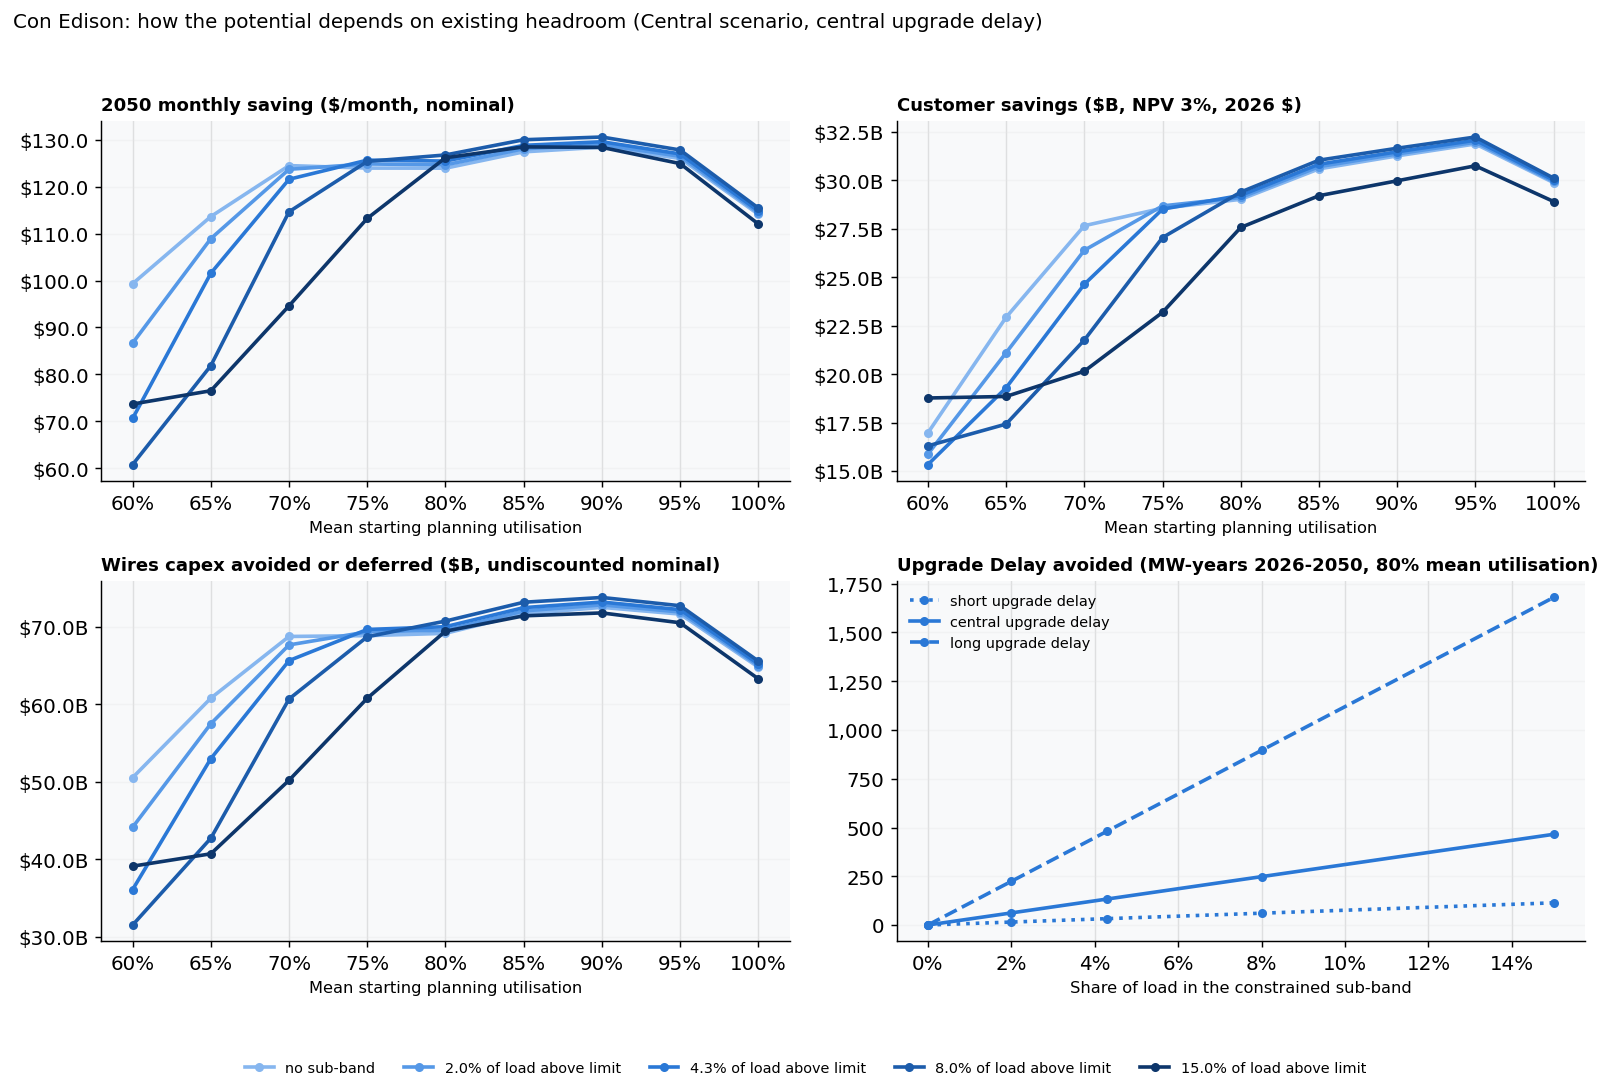

Headroom sweep, Central scenario ($ nominal; NPV at 3% in 2026 $):


2050 monthly saving ($, nominal)  \
delay case mean utilisation sub-band share                                     
short      0.6              0.000                                      99.33   
                            0.020                                      87.79   
                            0.043                                      72.81   
                            0.080                                      64.30   
                            0.150                                      78.72   
...                                                                      ...   
long       1.0              0.000                                     114.14   
                            0.020                                     114.14   
                            0.043                                     114.12   
                            0.080                                     114.10   
                            0.150                                     109.27   

                                            Customer savings ($B, undiscounted nominal)  \
delay case mean utilisation sub-band share                                                
short      0.6              0.000                                                 29.29   
                            0.020                                                 27.99   
                            0.043                                                 27.60   
                            0.080                                                 30.15   
                            0.150                                                 35.83   
...                                                                                 ...   
long       1.0              0.000                                                 50.18   
                            0.020                                                 50.10   
                            0.043                                                 50.00   
                            0.080                                                 49.84   
                            0.150                                                 47.08   

                                            Customer savings ($B, NPV 3%, 2026 $)  \
delay case mean utilisation sub-band share                                          
short      0.6              0.000                                           16.97   
                            0.020                                           16.46   
                            0.043                                           16.47   
                            0.080                                           18.11   
                            0.150                                           21.44   
...                                                                           ...   
long       1.0              0.000                                           29.87   
                            0.020                                           29.83   
                            0.043                                           29.78   
                            0.080                                           29.69   
                            0.150                                           28.05   

                                            of which efficiency energy ($B, undiscounted nominal)  \
delay case mean utilisation sub-band share                                                          
short      0.6              0.000                                                        7.95       
                            0.020                                                        7.95       
                            0.043                                                        7.95       
                            0.080                                                        7.95       
                            0.150                                                        7.95       
...   


Value stack, flexible resources ($ per kW-year nominal; incremental nameplate kW):


flexible kW (incremental)  cost $/kW-yr  \
scenario  year                                            
Cautious  2030                   103600.0          88.3   
          2035                   233100.0          99.9   
          2050                   466200.0         144.7   
Central   2030                   773066.7          93.6   
          2035                  1739400.0         105.9   
          2050                  3576200.0         151.8   
Ambitious 2030                  1059066.7          56.7   
          2035                  2382900.0          64.1   
          2050                  3728900.0          95.1   

                capacity value $/kW-yr  deferral value $/kW-yr  \
scenario  year                                                   
Cautious  2030                    91.4                   117.6   
          2035                   103.4                   544.0   
          2050                   149.8                  2340.5   
Central   2030                    81.8                    53.7   
          2035                    92.5                   318.0   
          2050                   136.3                  1560.4   
Ambitious 2030                    89.4                    59.8   
          2035                   101.1                   351.2   
          2050                   148.6                  2163.8   

                load-enabled value $/kW-yr  total value $/kW-yr  
scenario  year                                                   
Cautious  2030                        10.1                219.1  
          2035                         7.7                655.1  
          2050                         0.0               2490.2  
Central   2030                         9.2                144.6  
          2035                         5.8                416.2  
          2050                         0.0               1696.7  
Ambitious 2030                        13.4                162.6  
          2035                         4.2                456.5  
          2050                         0.0               2312.5

Cost at which flexibility pays for itself (MW-weighted flexible cost per kW-year, 2026 $; Central assumption $85/kW-yr):


  average bill equal to BAU in 2035: $1,340/kW-yr  (bisection)
  average bill equal to BAU in 2050: $1,697/kW-yr  (pays for itself at every cost tested (>= $1,697/kW-yr))
  cumulative 2026-2050 saving = 0 at 3% NPV: $1,697/kW-yr  (pays for itself at every cost tested (>= $1,697/kW-yr))


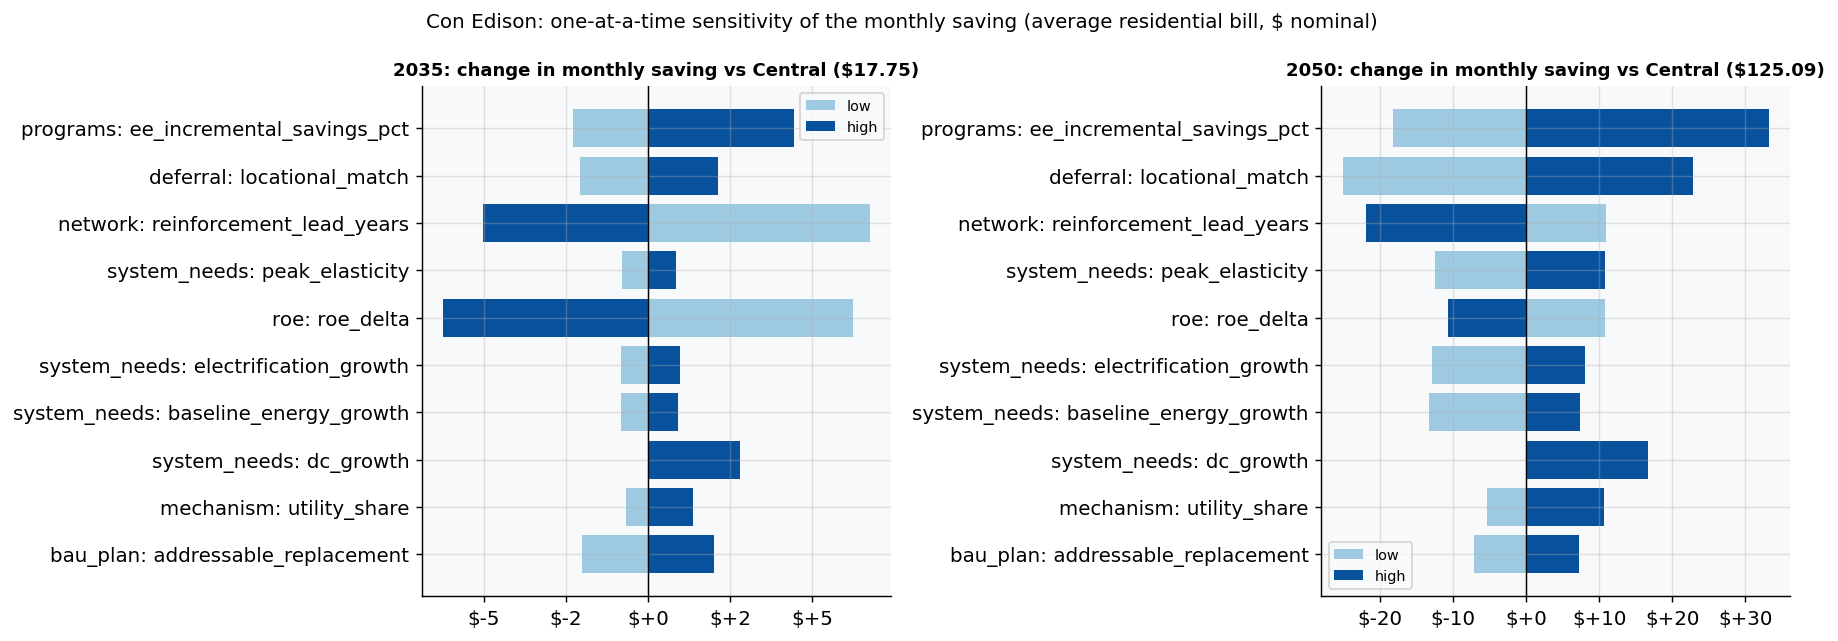

Top three assumptions by 2050 swing in the saving: programs/ee_incremental_savings_pct ($51.51); deferral/locational_match ($47.91); network/reinforcement_lead_years ($32.90)

Cumulative saving per residential customer, 2026-2050, Central (average residential bill):
  undiscounted nominal $: $13,707
  NPV 3% (2026 $): $8,063
  NPV 7% (2026 $): $4,197


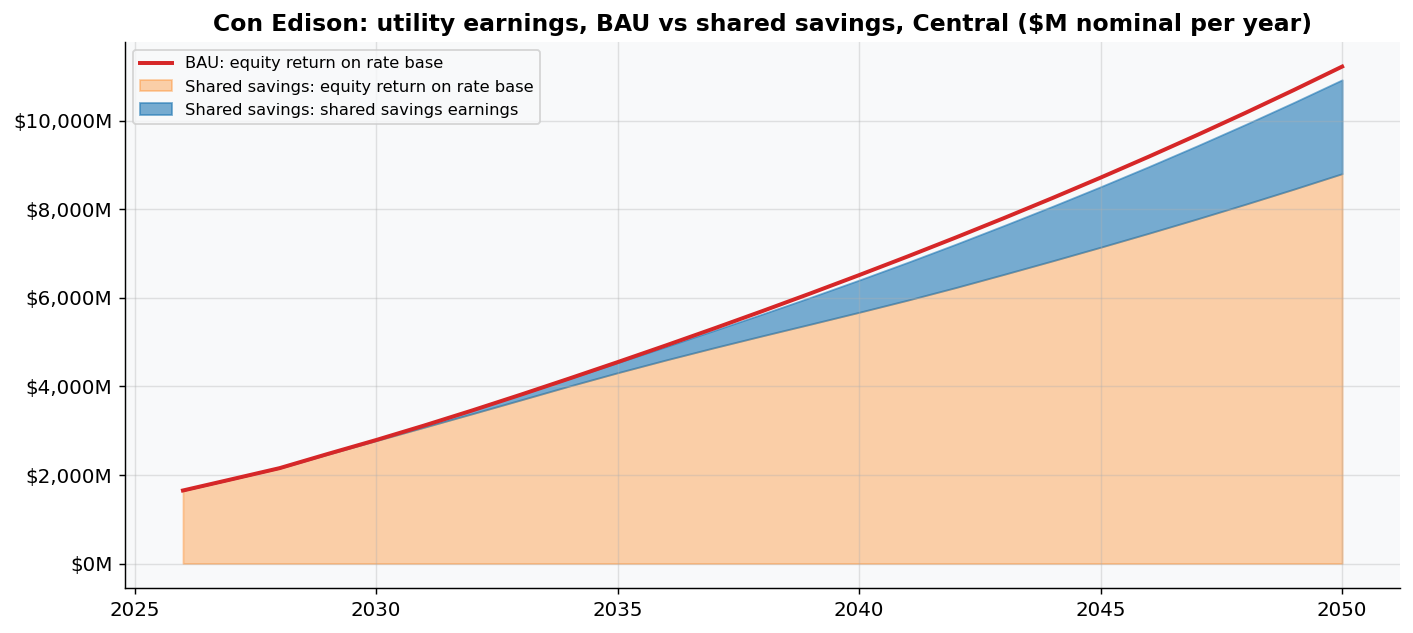

Cumulative utility earnings 2026-2050 ($M, undiscounted nominal):


,BAU equity return,SS equity return,SS shared savings earnings,SS total earnings
$M,148647.0,128407.0,17788.0,146195.0



RG&E: layered projection, Central scenario ($/month nominal per residential customer)
  Year-zero carve_out: Capacity (carved out: supply_charge 100%) $7.46/month
  Today's core-business program spend: $0.0M/yr (none); residential allocation factor 1.00

AVERAGE residential bill (usage lowered by EE), by category ($/month nominal):


,,Distribution base,Distribution riders,Programs,Supply energy,Capacity,Transmission,Taxes and fees,total
year,case,,,,,,,,
2026,BAU,74.22,10.53,3.56,60.27,7.46,0.0,3.42,159.45
2030,BAU,104.71,14.85,3.93,66.52,7.91,0.0,4.57,202.50
2035,BAU,167.31,23.73,4.45,75.27,9.00,0.0,6.90,286.66
2050,BAU,365.83,51.88,6.45,109.01,13.24,0.0,14.35,560.76
2026,Shared savings,74.22,10.53,3.56,60.27,7.46,0.0,3.42,159.45
2030,Shared savings,103.52,14.62,5.01,65.48,7.32,0.0,4.54,200.49
2035,Shared savings,158.67,22.23,9.45,72.08,7.40,0.0,6.69,276.52
2050,Shared savings,301.46,42.02,31.95,102.43,9.07,0.0,12.74,499.67



benchmark-usage bill (600 kWh/month), by category ($/month nominal):


,,Distribution base,Distribution riders,Programs,Supply energy,Capacity,Transmission,Taxes and fees,total
year,case,,,,,,,,
2026,BAU,74.22,10.53,3.56,60.27,7.46,0.0,3.42,159.45
2030,BAU,104.71,14.85,3.93,66.52,7.91,0.0,4.57,202.50
2035,BAU,167.31,23.73,4.45,75.27,9.00,0.0,6.90,286.66
2050,BAU,365.83,51.88,6.45,109.01,13.24,0.0,14.35,560.76
2026,Shared savings,74.22,10.53,3.56,60.27,7.46,0.0,3.42,159.45
2030,Shared savings,104.52,14.82,5.08,66.40,7.42,0.0,4.59,202.85
2035,Shared savings,162.95,23.11,9.82,74.94,7.69,0.0,6.89,285.40
2050,Shared savings,312.93,44.38,33.74,108.18,9.58,0.0,13.28,522.08


Scenarios (average residential bill; cumulative saving per residential customer 2026-2050):


,BAU 2026,Shared savings 2026,BAU 2035,Shared savings 2035,BAU 2050,Shared savings 2050,"cum saving, undiscounted nominal $","cum saving, NPV 3% (2026 $)","cum saving, NPV 7% (2026 $)"
scenario,,,,,,,,,
Cautious,159.5,159.5,286.7,282.6,560.8,543.8,2094.0,1261.0,680.5
Central,159.5,159.5,286.7,276.5,560.8,499.7,6675.1,3947.8,2074.6
Ambitious,159.5,159.5,286.7,269.7,560.8,473.8,9847.1,5868.6,3119.4


Waterfall, BAU to shared-savings AVERAGE residential bill ($/month nominal, Central; system needs applies to both cases so its bar is zero):


,BAU,System needs,Programs as core business,Deferral,Load enabled (bill effect only),Capacity,Wholesale energy (load shifting),Avoided transmission,Avoided distribution losses,Shared savings earnings,ROE lever,Shared savings
2026,159.45,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,159.45
2030,202.50,0.0,0.16,-1.75,-0.09,-0.50,-0.09,-0.03,-0.14,0.42,0.0,200.49
2035,286.66,0.0,1.51,-13.00,0.54,-1.34,-0.22,-0.09,-0.38,2.84,0.0,276.52
2050,560.76,0.0,8.32,-83.38,0.52,-3.49,-0.59,-0.23,-0.93,18.69,0.0,499.67


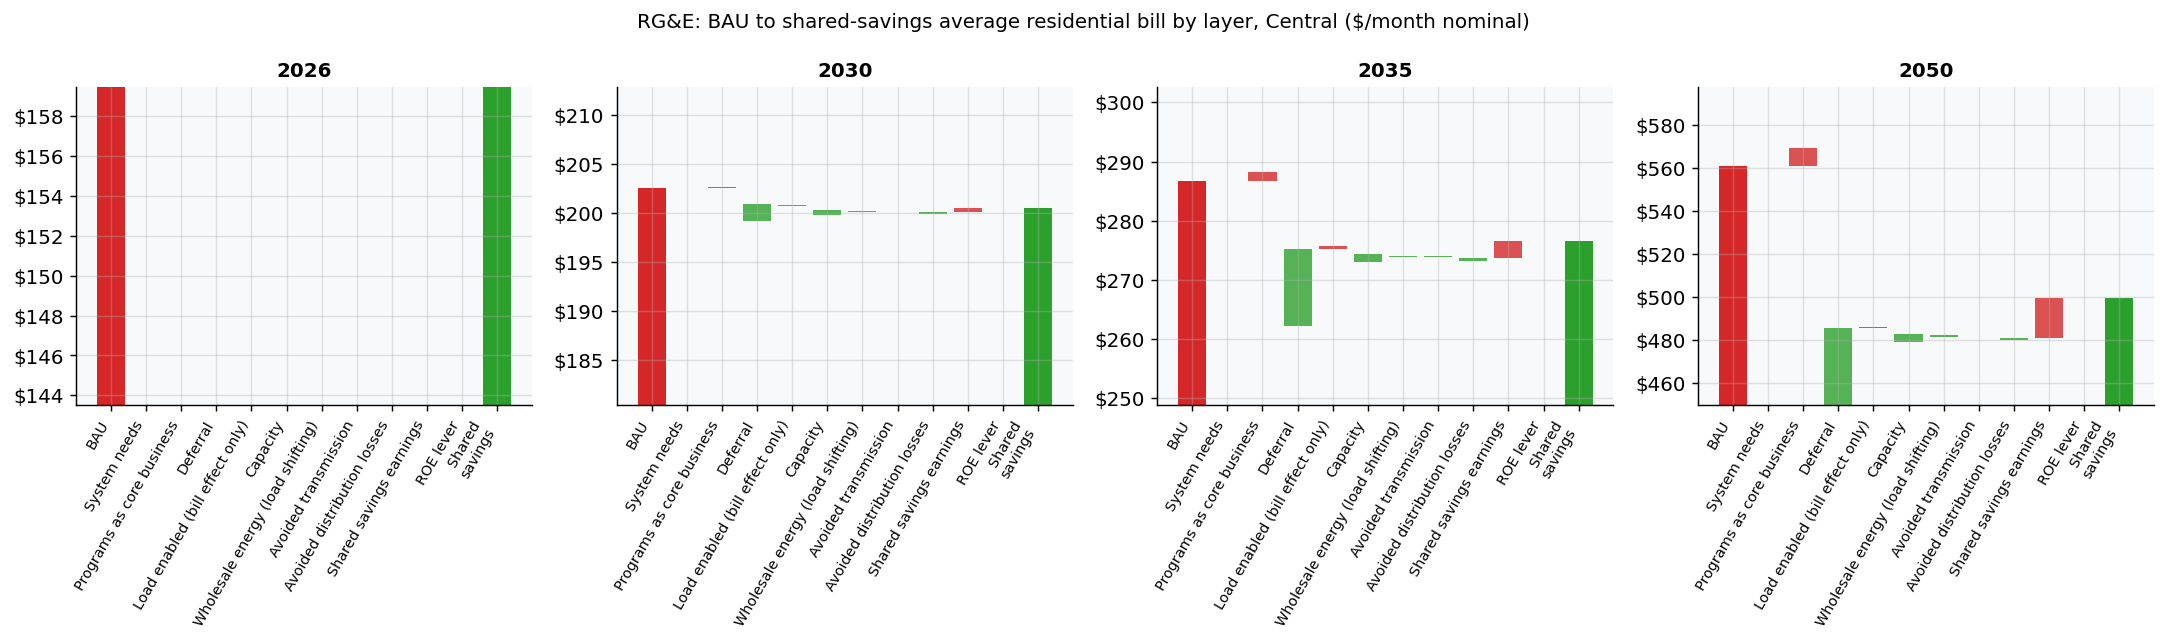

System-wide results, Central (BAU minus shared savings, all customers; $B undiscounted nominal unless marked):


,Central
"Customer savings ($B, undiscounted nominal)",6.12
"Customer savings ($B, NPV 3%, 2026 $)",3.63
"of which efficiency energy ($B, undiscounted nominal)",1.11
"of which wholesale energy, load shifted ($B, undiscounted nominal)",0.09
"of which avoided transmission ($B, undiscounted nominal)",0.03
"of which avoided distribution losses ($B, undiscounted nominal)",0.17
"of which ROE change, cost to customers ($B, undiscounted nominal)",-0.00
"Wires capex avoided or deferred ($B, undiscounted nominal)",8.45
"Wires capex avoided or deferred ($B, NPV 3%, 2026 $)",5.22
Reinforcement deferred (MW),109.21


Contribution by layer, Central (added in waterfall order; earnings attributable computed with the mechanism on):


,"Customer savings ($B, undiscounted nominal)","Customer savings ($B, NPV 3%, 2026 $)","Monthly bill 2035 ($, nominal)","Monthly bill 2050 ($, nominal)","Shared savings earnings ($B, undiscounted nominal)","Shared savings earnings ($B, NPV 3%, 2026 $)","Utility equity return ($B, undiscounted nominal)","Savings pool contribution ($B, undiscounted nominal)","Savings pool contribution ($B, NPV 3%, 2026 $)","Shared savings earnings attributable ($B, undiscounted nominal)","Shared savings earnings attributable ($B, NPV 3%, 2026 $)"
layer,,,,,,,,,,,
Programs as core business,-0.070,-0.023,1.506,8.320,0.00,0.000,0.113,-1.175,-0.716,-0.352,-0.215
Deferral,7.564,4.431,-12.999,-83.376,0.00,0.000,-2.844,7.564,4.431,2.269,1.329
Load enabled (bill effect only),-0.129,-0.082,0.537,0.516,0.00,0.000,0.048,-0.129,-0.082,-0.039,-0.025
Capacity,0.618,0.383,-1.341,-3.488,0.00,0.000,0.000,0.618,0.383,0.186,0.115
Wholesale energy (load shifting),0.093,0.057,-0.220,-0.592,0.00,0.000,0.000,0.093,0.057,0.028,0.017
Avoided transmission,0.028,0.017,-0.087,-0.228,0.00,0.000,0.000,0.028,0.017,0.008,0.005
Avoided distribution losses,0.167,0.104,-0.379,-0.928,0.00,0.000,0.000,0.167,0.104,0.050,0.031
Shared savings earnings,-2.150,-1.258,2.845,18.691,2.15,1.258,0.000,0.000,0.000,0.000,0.000
ROE lever,0.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,0.000,0.000,0.000


ROE lever (Central = no change; outside the shared-savings pool):
  roe_delta -60 bp: customer savings $7.02B; 2050 monthly saving $67.43; SS equity return $14.23B vs BAU $17.80B
  roe_delta +60 bp: customer savings $5.23B; 2050 monthly saving $54.74; SS equity return $16.02B vs BAU $17.80B
Network capacity, Central network and Tight network (low headroom, long lead time, low build rate):
  Central network, Cautious:


,BAU MW waiting for upgrade,SS MW waiting for upgrade,MW connected sooner (SS),"BAU Upgrade Delay for Interconnection (yr, load requested that year)","SS Upgrade Delay for Interconnection (yr, load requested that year)",BAU GWh not served on time,SS GWh not served on time,Effective capacity uplift %,Headroom created MW,to load enabled MW,to deferral MW,Reinforcement deferred MW (cum.)
year,,,,,,,,,,,,
2035,0.28,0.18,0.0,1.0,1.0,1.48,0.96,0.0,0.51,0.01,0.50,4.62
2050,0.00,0.00,0.0,0.0,0.0,0.00,0.00,0.0,1.02,0.00,1.02,16.01


... (29 outputs left out)

,BAU MW above planning limit,SS MW above planning limit,BAU MW waiting for upgrade,SS MW waiting for upgrade
year,,,,
2026,3.0,3.0,0.0,0.0
2030,0.0,0.0,4.0,1.0
2035,0.0,0.0,0.0,0.0
2040,0.0,0.0,0.0,0.0
2050,0.0,0.0,0.0,0.0


  Customer savings ($B, undiscounted nominal): 6.12; Customer savings ($B, NPV 3%, 2026 $): 3.63; of which efficiency energy ($B, undiscounted nominal): 1.11; of which wholesale energy, load shifted ($B, undiscounted nominal): 0.09; of which avoided transmission ($B, undiscounted nominal): 0.03; of which avoided distribution losses ($B, undiscounted nominal): 0.17; of which ROE change, cost to customers ($B, undiscounted nominal): -0.00; Wires capex avoided or deferred ($B, undiscounted nominal): 8.45; Wires capex avoided or deferred ($B, NPV 3%, 2026 $): 5.22; Reinforcement deferred (MW): 109.21; Capacity cost avoided ($B, undiscounted nominal): 0.62; Shared savings earnings ($B, undiscounted nominal): 2.15; Shared savings earnings ($B, NPV 3%, 2026 $): 1.26; MW connected sooner (peak year): 1.60; Upgrade Delay for Interconnection avoided (MW-years): 9.56; Upgrade Delay for Interconnection, BAU (avg yr): 1.89; Upgrade Delay for Interconnection, SS (avg yr): 1.17; Upgrade Delay for Int

,BAU MW above planning limit,SS MW above planning limit,BAU MW waiting for upgrade,SS MW waiting for upgrade
year,,,,
2026,3.0,3.0,0.0,0.0
2030,0.0,0.0,4.0,0.0
2035,0.0,0.0,0.0,0.0
2040,0.0,0.0,0.0,0.0
2050,0.0,0.0,0.0,0.0


  Customer savings ($B, undiscounted nominal): 6.26; Customer savings ($B, NPV 3%, 2026 $): 3.71; of which efficiency energy ($B, undiscounted nominal): 1.11; of which wholesale energy, load shifted ($B, undiscounted nominal): 0.09; of which avoided transmission ($B, undiscounted nominal): 0.03; of which avoided distribution losses ($B, undiscounted nominal): 0.17; of which ROE change, cost to customers ($B, undiscounted nominal): -0.00; Wires capex avoided or deferred ($B, undiscounted nominal): 8.86; Wires capex avoided or deferred ($B, NPV 3%, 2026 $): 5.44; Reinforcement deferred (MW): 126.42; Capacity cost avoided ($B, undiscounted nominal): 0.62; Shared savings earnings ($B, undiscounted nominal): 2.21; Shared savings earnings ($B, NPV 3%, 2026 $): 1.29; MW connected sooner (peak year): 2.88; Upgrade Delay for Interconnection avoided (MW-years): 13.51; Upgrade Delay for Interconnection, BAU (avg yr): 1.89; Upgrade Delay for Interconnection, SS (avg yr): 1.00; Upgrade Delay for In

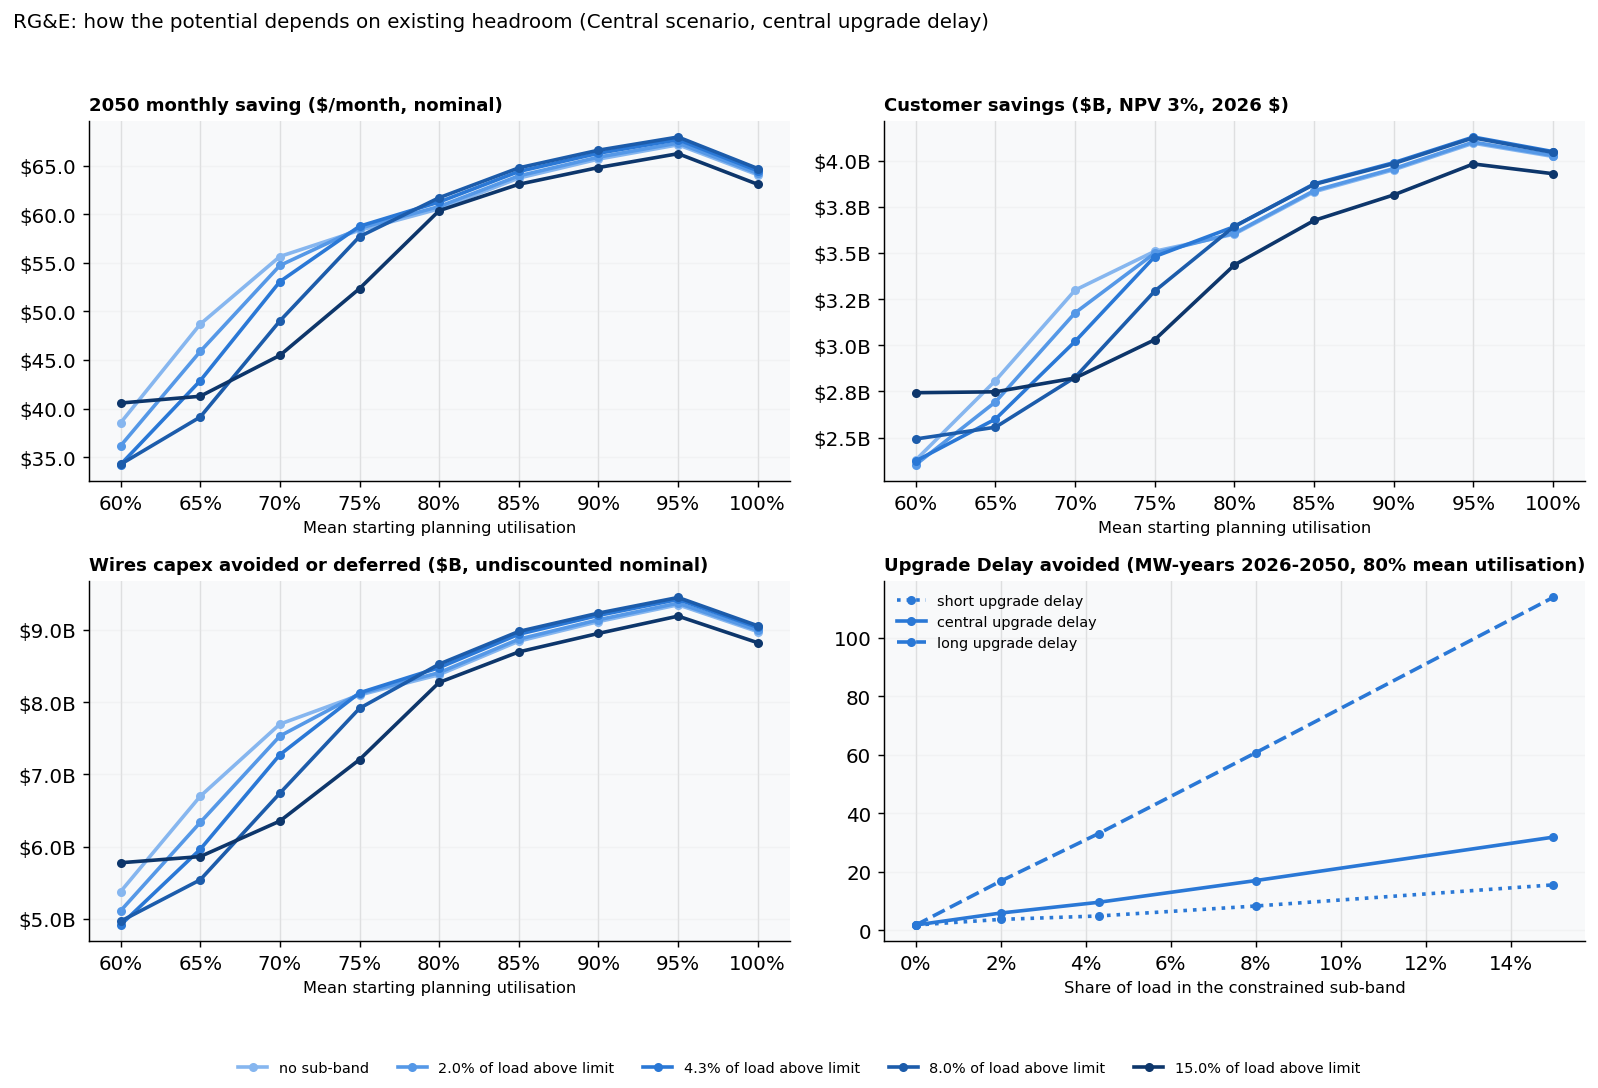

Headroom sweep, Central scenario ($ nominal; NPV at 3% in 2026 $):


2050 monthly saving ($, nominal)  \
delay case mean utilisation sub-band share                                     
short      0.6              0.000                                      38.54   
                            0.020                                      36.37   
                            0.043                                      34.66   
                            0.080                                      34.96   
                            0.150                                      41.61   
...                                                                      ...   
long       1.0              0.000                                      64.05   
                            0.020                                      64.11   
                            0.043                                      64.29   
                            0.080                                      64.36   
                            0.150                                      62.40   

                                            Customer savings ($B, undiscounted nominal)  \
delay case mean utilisation sub-band share                                                
short      0.6              0.000                                                  3.97   
                            0.020                                                  3.95   
                            0.043                                                  4.01   
                            0.080                                                  4.25   
                            0.150                                                  4.76   
...                                                                                 ...   
long       1.0              0.000                                                  6.76   
                            0.020                                                  6.75   
                            0.043                                                  6.76   
                            0.080                                                  6.73   
                            0.150                                                  6.47   

                                            Customer savings ($B, NPV 3%, 2026 $)  \
delay case mean utilisation sub-band share                                          
short      0.6              0.000                                            2.38   
                            0.020                                            2.38   
                            0.043                                            2.42   
                            0.080                                            2.57   
                            0.150                                            2.86   
...                                                                           ...   
long       1.0              0.000                                            4.02   
                            0.020                                            4.02   
                            0.043                                            4.03   
                            0.080                                            4.00   
                            0.150                                            3.85   

                                            of which efficiency energy ($B, undiscounted nominal)  \
delay case mean utilisation sub-band share                                                          
short      0.6              0.000                                                        1.11       
                            0.020                                                        1.11       
                            0.043                                                        1.11       
                            0.080                                                        1.11       
                            0.150                                                        1.11       
...   


Value stack, flexible resources ($ per kW-year nominal; incremental nameplate kW):


flexible kW (incremental)  cost $/kW-yr  \
scenario  year                                            
Cautious  2030                     1644.4          88.3   
          2035                     3700.0          99.9   
          2050                     7400.0         144.7   
Central   2030                   110843.9          91.3   
          2035                   262500.0         101.9   
          2050                   545400.0         147.4   
Ambitious 2030                   118266.7          57.1   
          2035                   266100.0          64.6   
          2050                   545400.0          93.9   

                capacity value $/kW-yr  deferral value $/kW-yr  \
scenario  year                                                   
Cautious  2030                    55.2                   995.4   
          2035                    62.4                  2052.0   
          2050                    90.4                  6361.0   
Central   2030                    51.4                   140.5   
          2035                    59.4                   397.4   
          2050                    86.2                  1364.3   
Ambitious 2030                    56.3                   180.6   
          2035                    63.7                   533.9   
          2050                    92.6                  1665.1   

                load-enabled value $/kW-yr  total value $/kW-yr  
scenario  year                                                   
Cautious  2030                       309.7               1360.3  
          2035                        35.0               2149.3  
          2050                         0.0               6451.4  
Central   2030                        16.3                208.3  
          2035                         1.2                458.1  
          2050                         0.0               1450.5  
Ambitious 2030                        26.1                263.0  
          2035                         1.2                598.8  
          2050                         0.0               1757.7

Cost at which flexibility pays for itself (MW-weighted flexible cost per kW-year, 2026 $; Central assumption $82/kW-yr):


  average bill equal to BAU in 2035: $657/kW-yr  (bisection)


  average bill equal to BAU in 2050: $1,146/kW-yr  (bisection)


  cumulative 2026-2050 saving = 0 at 3% NPV: $915/kW-yr  (bisection)


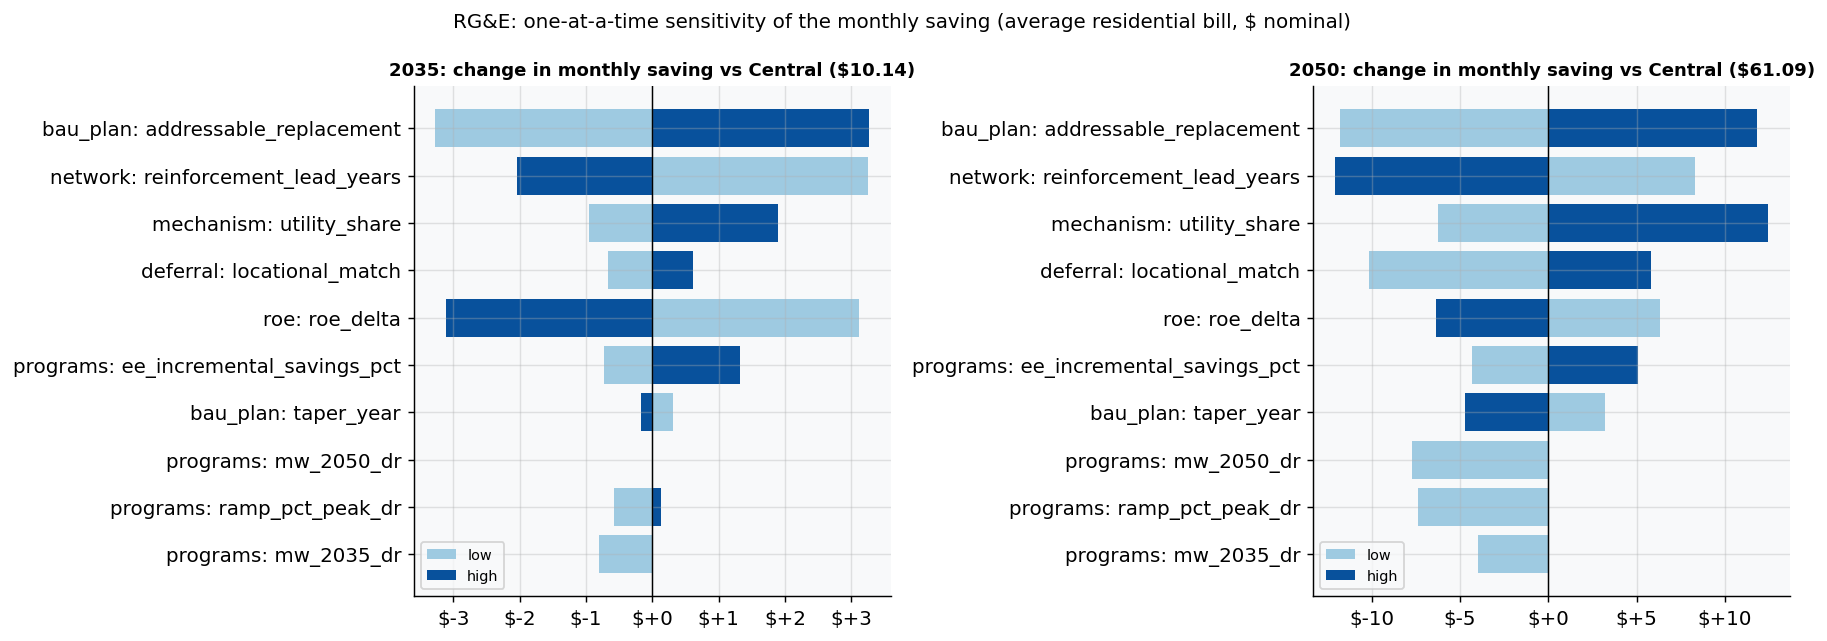

Top three assumptions by 2050 swing in the saving: bau_plan/addressable_replacement ($23.60); network/reinforcement_lead_years ($20.41); mechanism/utility_share ($18.69)

Cumulative saving per residential customer, 2026-2050, Central (average residential bill):
  undiscounted nominal $: $6,675
  NPV 3% (2026 $): $3,948
  NPV 7% (2026 $): $2,075


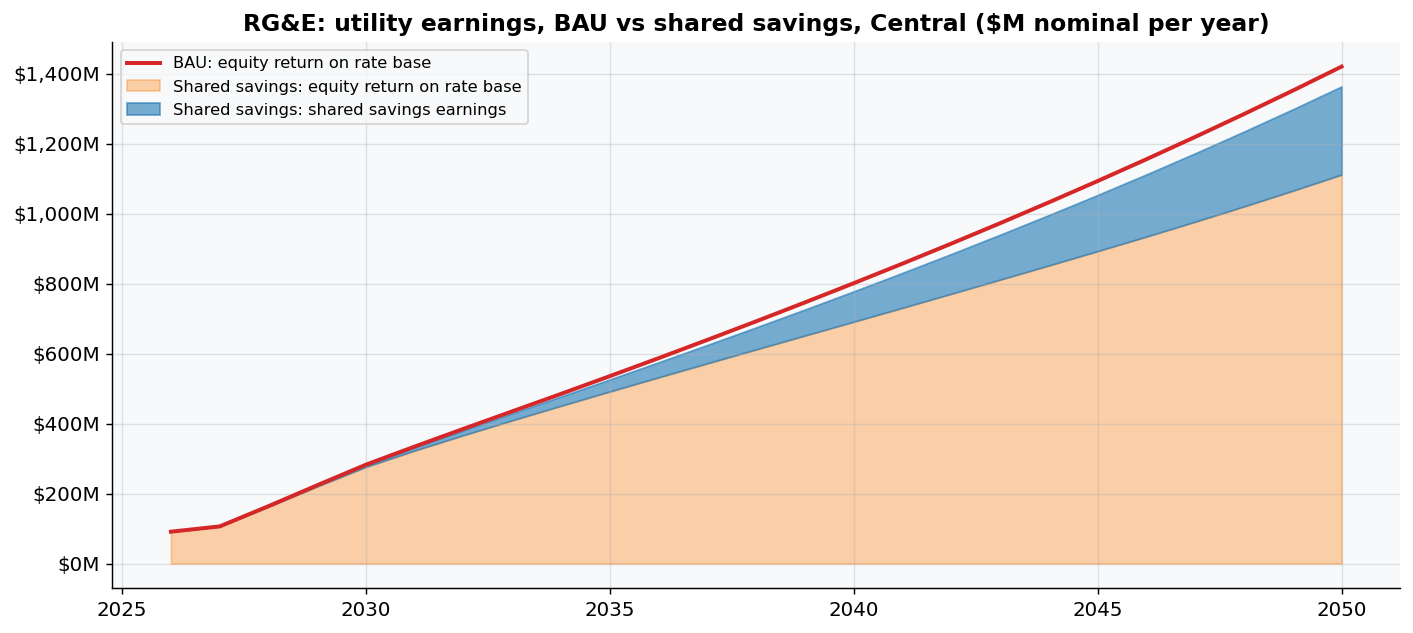

Cumulative utility earnings 2026-2050 ($M, undiscounted nominal):


,BAU equity return,SS equity return,SS shared savings earnings,SS total earnings
$M,17804.0,15121.0,2150.0,17271.0


In [23]:
# ============================================================
# SECTION 13: LAYERED BILL PROJECTION (engine/layers.py)
# Year zero = each utility's starting_bill (utilities/*.json). BAU vs SHARED
# SAVINGS 2026-2050 built from switchable layers; low / central / high values
# and the Cautious / Central / Ambitious scenarios are in the JSON
# 'forward_assumptions'. Independent of Sections 1-12 (v1.0 / CORRECTED
# unchanged). All $ nominal. Headline bill = AVERAGE residential bill
# (usage lowered by energy efficiency); the benchmark-usage bill is shown too.
# ============================================================
from engine import layers as LY

# Network what-if: set any input of the JSON 'network' block here (value, or
# 'low' / 'central' / 'high' where the JSON gives a range). Highest precedence:
# overrides the scenario 'network' values and the JSON for every run below.
# Example: {'subband_enabled': True, 'flex_targeting_enabled': True, 'mean_utilisation': 0.9}
NETWORK_OVERRIDES = {}
LY.NETWORK_OVERRIDES.clear()
LY.NETWORK_OVERRIDES.update(NETWORK_OVERRIDES)

os.makedirs('charts', exist_ok=True)
LAYER_LABEL = {'system_needs': 'System needs', 'programs': 'Programs as core business',
               'deferral': 'Deferral', 'load_enabled': 'Load enabled (bill effect only)', 'capacity': 'Capacity',
               'wholesale_energy': 'Wholesale energy (load shifting)', 'transmission': 'Avoided transmission',
               'losses': 'Avoided distribution losses', 'mechanism': 'Shared savings earnings', 'roe': 'ROE lever'}
from engine.report import TIGHT_NETWORK, headroom_sweep_figure
CAT_LABEL = {'distribution_base': 'Distribution base', 'distribution_rider': 'Distribution riders',
             'program_surcharge': 'Programs', 'supply_energy': 'Supply energy',
             'capacity': 'Capacity', 'transmission': 'Transmission', 'taxes_and_fees': 'Taxes and fees'}
layer_results = {}

for k in utilities_to_run:
    uj, p = UTILITIES[k], utility_data[k]
    name = uj['short_name']
    kwh = uj['starting_bill']['benchmark_kwh_month']
    run = LY.project_layers(uj, p, scenario='Central')
    layer_results[k] = run
    print(f"\n{'=' * 78}\n{name}: layered projection, Central scenario ($/month nominal per residential customer)\n{'=' * 78}")
    for d in run['starting_lines']:
        if d['origin'] != 'starting_bill':
            print(f"  Year-zero {d['origin']}: {d['name']} ${d['month']:.2f}/month")
    print(f"  Today's core-business program spend: ${run['program_spend0_m']:,.1f}M/yr "
          f"({'; '.join(f'{i}: {v:,.1f} ({h})' for i, v, h in run['program_spend0_parts']) or 'none'}); "
          f"residential allocation factor {run['residential_program_allocation']:.2f}")

    # 1. Bills by category: average residential bill (headline) and benchmark usage
    for measure, lbl in (('average', 'AVERAGE residential bill (usage lowered by EE)'),
                         ('benchmark', f'benchmark-usage bill ({kwh:,} kWh/month)')):
        print(f'\n{lbl}, by category ($/month nominal):')
        display(LY.bill_table(run, measure=measure).rename(columns=CAT_LABEL).round(2))

    # 2. Scenarios
    sc = LY.scenario_table(uj, p)
    print('Scenarios (average residential bill; cumulative saving per residential customer 2026-2050):')
    display(sc.round(1))

    # 3. Waterfall, average residential bill, Central
    wf = LY.waterfall(uj, p, measure='average')
    print('Waterfall, BAU to shared-savings AVERAGE residential bill ($/month nominal, Central; '
          'system needs applies to both cases so its bar is zero):')
    display(wf.rename(columns=LAYER_LABEL).round(2))
    fig, axes = plt.subplots(1, len(wf), figsize=(4.2 * len(wf), 5))
    steps = list(LAYER_LABEL)
    for ax, (y, row) in zip(axes, wf.iterrows()):
        level = row['BAU']
        ax.bar(0, row['BAU'], color=C['bau'])
        for i, l in enumerate(steps, start=1):
            v = row[l]
            ax.bar(i, v, bottom=level if v >= 0 else level + v, color=C['bau'] if v > 0 else C['shared'], alpha=0.8)
            level += v
        ax.bar(len(steps) + 1, row['Shared savings'], color=C['shared'])
        ax.set_xticks(range(len(steps) + 2))
        ax.set_xticklabels(['BAU'] + [LAYER_LABEL[s] for s in steps] + ['Shared\nsavings'], rotation=60, ha='right', fontsize=8)
        ax.set_ylim(bottom=min(row['BAU'], row['Shared savings']) * 0.9)
        ax.set_title(f'{y}', fontsize=11)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}'))
    fig.suptitle(f'{name}: BAU to shared-savings average residential bill by layer, Central ($/month nominal)', fontsize=11)
    plt.tight_layout()
    plt.savefig(f'charts/layers_waterfall_{k.lower()}.png', bbox_inches='tight', dpi=130)
    plt.show()

    # 3b. System-wide results and each layer's contribution (customer savings $B, monthly bill, shared savings earnings)
    print('System-wide results, Central (BAU minus shared savings, all customers; $B undiscounted nominal unless marked):')
    display(pd.Series(LY.system_summary(run)).round(2).to_frame('Central'))
    print("Contribution by layer, Central (added in waterfall order; earnings attributable computed with the mechanism on):")
    display(LY.layer_contributions(uj, p).rename(index=LAYER_LABEL).round(3))
    print('ROE lever (Central = no change; outside the shared-savings pool):')
    for lev in ('low', 'high'):
        r_roe = LY.project_layers(uj, p, overrides={('roe', 'roe_delta'): lev})
        print(f"  roe_delta {r_roe['assumptions']['roe']['roe_delta'] * 1e4:+.0f} bp: customer savings "
              f"${LY.system_summary(r_roe)['Customer savings ($B, undiscounted nominal)']:,.2f}B; 2050 monthly saving "
              f"${r_roe['bau']['avg_bill_total'].iloc[-1] - r_roe['ss']['avg_bill_total'].iloc[-1]:,.2f}; SS equity return "
              f"${r_roe['ss']['equity_return_m'].sum() / 1e3:,.2f}B vs BAU ${r_roe['bau']['equity_return_m'].sum() / 1e3:,.2f}B")

    # 4a. Network capacity: headroom, load connected sooner, Upgrade Delay for Interconnection
    print('Network capacity, Central network and Tight network (low headroom, long lead time, low build rate):')
    for lbl, ov in (('Central network', {}), ('Tight network', TIGHT_NETWORK)):
        for scn in LY.SCENARIOS:
            ct = LY.connection_table(LY.project_layers(uj, p, scenario=scn, overrides=ov), (2035, 2050))
            print(f"  {lbl}, {scn}:")
            display(ct.round(2))
    print('Effective capacity uplift, derived vs direct mode (Central):')
    for mode in ('derived', 'direct'):
        ct = LY.connection_table(LY.project_layers(uj, p, uplift_mode=mode), (2035, 2050))
        print(f"  {mode}: " + ', '.join(f"{y} {ct.loc[y, 'Effective capacity uplift %']:.1%}" for y in ct.index))

    # 4b. MW by resource type
    print('\nFlexible MW by resource type (today = BAU; SS = shared savings) and EE peak MW, Central:')
    mt = LY.mw_table(run)
    display(mt.drop(columns='Flexible share of peak (SS)').T.round(0))
    print(f"  Flexible share of peak (SS): " + ', '.join(f"{y} {mt.loc[y, 'Flexible share of peak (SS)']:.1%}" for y in mt.index))

    # 4c. Loading bands: MW of load in constrained bands, and per-band detail
    print('\nLoading bands (starting loading = network peak / firm capacity): '
          + '; '.join(f"{b['name']} {b['loading0']:.0%} of capacity, {b['load_share']:.0%} of load" for b in run['bands']))
    for lbl, ov in (('Central network', {}), ('Tight network', TIGHT_NETWORK)):
        print(f'MW of network load in constrained bands, {lbl}, Central scenario:')
        display(LY.constrained_table(LY.project_layers(uj, p, overrides=ov)).round(0))
    print('Per-band detail, Tight network, Central scenario (MW):')
    display(LY.band_table(LY.project_layers(uj, p, overrides=TIGHT_NETWORK), (2035, 2050)).drop(columns='year', errors='ignore').round(2))

    # 4d. Access: faster connections, reported separately from the bill (benefit to the customers being connected)
    for lbl, ov, nw in (('Central network', {}, None),
                        ('Central network, sub-band on in every scenario', {}, {'subband_enabled': True}),
                        ('Tight network', TIGHT_NETWORK, None)):
        print(f'Access block, {lbl} (Upgrade Delay for Interconnection = years a new customer in a constrained area '
              'waits for the grid upgrade; connection cost avoided = upper bound at the distribution upgrade cost per MW; '
              '$M nominal undiscounted and NPV 3% 2026 $):')
        display(LY.access_table(uj, p, overrides=ov, network=nw).T.round(2))

    # 4e. Flexible MW: target path vs maximum annual growth per resource type
    print('Flexible MW, Central: target path vs ramp limit (observed program ramps):')
    display(LY.mw_path_table(uj, p).round(0))

    # 4f. Constrained sub-band: load above the planning limit (on in every scenario), and the Upgrade Delay
    #     for Interconnection
    nwp = LY.resolve(uj['forward_assumptions'])['network']
    print(f"\nConstrained sub-band, Central scenario: {nwp['subband_load_share']:.1%} of network load at "
          f"{nwp['subband_utilisation']:.1%} planning utilisation; operating limit {LY.operating_limit(nwp):.2f} x "
          "planning capacity. Existing load stays connected up to the operating limit; the backlog above the planning "
          f"limit is cleared at {nwp.get('backlog_clearance_pct', float('nan')):.0%} a year; new load waits the Upgrade "
          f"Delay for Interconnection ({nwp.get('upgrade_delay_ordinary_years')} yr ordinary, "
          f"{nwp.get('upgrade_delay_large_years')} yr large loads; build-rate priority "
          f"{'on' if nwp.get('constrained_build_priority') else 'off'}). MW above the planning limit and MW waiting for "
          "upgrade are separate measures.")
    print('Upgrade Delay for Interconnection by request year, Central:')
    display(LY.upgrade_delay_table(run).round(2))
    for lbl, nw in (('Central (sub-band on)', {'subband_enabled': True}),
                    ('Central, flexibility targeted', {'subband_enabled': True, 'flex_targeting_enabled': True})):
        r_sub = LY.project_layers(uj, p, network=nw)
        print(f'  {lbl}:')
        display(LY.constrained_table(r_sub)[['BAU MW above planning limit', 'SS MW above planning limit',
                                             'BAU MW waiting for upgrade', 'SS MW waiting for upgrade']].round(0))
        print('  ' + '; '.join(f'{k}: {v:,.2f}' for k, v in LY.system_summary(r_sub).items()))

    # 4g. Headroom sweep: mean starting utilisation x share of load in the sub-band x Upgrade Delay case
    #     (short / central / long), Central otherwise
    sw = LY.headroom_sweep(uj, p)
    fig = headroom_sweep_figure(sw, name)
    fig.savefig(f'charts/layers_headroom_sweep_{k.lower()}.png', bbox_inches='tight', dpi=130)
    display(fig)
    print('Headroom sweep, Central scenario ($ nominal; NPV at 3% in 2026 $):')
    display(sw.set_index(['delay case', 'mean utilisation', 'sub-band share']).round(2))

    # 5. Value stack and the cost at which flexibility pays for itself
    print('\nValue stack, flexible resources ($ per kW-year nominal; incremental nameplate kW):')
    vs_rows = []
    for scn in LY.SCENARIOS:
        v = LY.value_stack(LY.project_layers(uj, p, scenario=scn), p).assign(scenario=scn)
        vs_rows.append(v)
    display(pd.concat(vs_rows).reset_index().set_index(['scenario', 'year']).round(1))
    print('Cost at which flexibility pays for itself (MW-weighted flexible cost per kW-year, 2026 $; '
          f"Central assumption ${LY.weighted_flex_cost(uj):,.0f}/kW-yr):")
    for target in (2035, 2050, 'npv3'):
        cost, note = LY.flex_pays_cost(uj, p, target=target)
        lbl = f'average bill equal to BAU in {target}' if target != 'npv3' else 'cumulative 2026-2050 saving = 0 at 3% NPV'
        print(f"  {lbl}: " + (f'${cost:,.0f}/kW-yr' if cost is not None else 'n/a') + f'  ({note})')

    # 6. Tornado on the saving
    tor, cen = LY.tornado(uj, p, measure='average')
    top = tor.head(10).iloc[::-1]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, y in zip(axes, (2035, 2050)):
        labels = [f"{r['layer']}: {r['assumption']}" for _, r in top.iterrows()]
        ax.barh(labels, top[f'low {y}'], color='#9ecae1', label='low')
        ax.barh(labels, top[f'high {y}'], color='#08519c', label='high')
        ax.axvline(0, color='k', lw=0.8)
        ax.set_title(f'{y}: change in monthly saving vs Central (${cen[y]:,.2f})', fontsize=10)
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:+,.0f}'))
        ax.legend(fontsize=8)
    fig.suptitle(f'{name}: one-at-a-time sensitivity of the monthly saving (average residential bill, $ nominal)', fontsize=11)
    plt.tight_layout()
    plt.savefig(f'charts/layers_tornado_{k.lower()}.png', bbox_inches='tight', dpi=130)
    plt.show()
    print('Top three assumptions by 2050 swing in the saving: '
          + '; '.join(f"{r['layer']}/{r['assumption']} (${r['swing 2050']:,.2f})" for _, r in tor.head(3).iterrows()))

    # 7. Cumulative savings and utility earnings
    print('\nCumulative saving per residential customer, 2026-2050, Central (average residential bill):')
    for lbl, v in LY.cumulative_savings(run).items():
        print(f'  {lbl}: ${v:,.0f}')
    et = LY.earnings_table(run)
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(et['year'], et['BAU equity return'], color=C['bau'], lw=2.2, label='BAU: equity return on rate base')
    ax.fill_between(et['year'], 0, et['SS equity return'], color=C['util_bau'], alpha=0.35,
                    label='Shared savings: equity return on rate base')
    ax.fill_between(et['year'], et['SS equity return'], et['SS total earnings'], color=C['util_shared'], alpha=0.6,
                    label='Shared savings: shared savings earnings')
    ax.set_title(f'{name}: utility earnings, BAU vs shared savings, Central ($M nominal per year)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}M'))
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(f'charts/layers_earnings_{k.lower()}.png', bbox_inches='tight', dpi=130)
    plt.show()
    print('Cumulative utility earnings 2026-2050 ($M, undiscounted nominal):')
    display(et[['BAU equity return', 'SS equity return', 'SS shared savings earnings', 'SS total earnings']]
            .sum().round(0).to_frame('$M').T)
